In [1]:
# ============================================================
# ARTIGO 3 — APRENDIZADO DE MÁQUINA APLICADO AO VENTO
# SBCY / CUIABÁ–VÁRZEA GRANDE
#
# Notebook 00 — Desenho experimental e inventário de dados
# ============================================================

# Bibliotecas básicas
import os
from pathlib import Path
import random

import numpy as np
import pandas as pd

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configuração de visualização do pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("Ambiente configurado com sucesso.")
print(f"Seed definida: {SEED}")

Ambiente configurado com sucesso.
Seed definida: 42


In [2]:
from pathlib import Path

# ============================================================
# CAMINHOS DO PROJETO — ARTIGO 3
# ============================================================

# Pasta principal do Artigo 3
PASTA_PROJETO = Path(
    r"C:\Users\USUARIO\Documents\PESQUISA_VENTO_CUIABA\ARTIGO_3_ML_VENTO_SBCY"
)

# Subpastas
PASTA_DADOS = PASTA_PROJETO / "01_DADOS"
PASTA_NOTEBOOKS = PASTA_PROJETO / "02_NOTEBOOKS"
PASTA_RESULTADOS = PASTA_PROJETO / "03_RESULTADOS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"
PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_MODELOS = PASTA_PROJETO / "06_MODELOS"

# Criar as pastas automaticamente, caso ainda não existam
for pasta in [
    PASTA_PROJETO,
    PASTA_DADOS,
    PASTA_NOTEBOOKS,
    PASTA_RESULTADOS,
    PASTA_GRAFICOS,
    PASTA_TABELAS,
    PASTA_MODELOS
]:
    pasta.mkdir(parents=True, exist_ok=True)

print("Estrutura do Artigo 3 criada/verificada com sucesso.")
print(f"Pasta principal: {PASTA_PROJETO}")

Estrutura do Artigo 3 criada/verificada com sucesso.
Pasta principal: C:\Users\USUARIO\Documents\PESQUISA_VENTO_CUIABA\ARTIGO_3_ML_VENTO_SBCY


In [3]:
from pathlib import Path

# ============================================================
# CAMINHOS DO PROJETO — ARTIGO 3
# ============================================================

PASTA_PROJETO = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML"
)

PASTA_DADOS = PASTA_PROJETO / "01_DADOS"
PASTA_NOTEBOOKS = PASTA_PROJETO / "02_NOTEBOOKS"
PASTA_RESULTADOS = PASTA_PROJETO / "03_RESULTADOS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"
PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_MODELOS = PASTA_PROJETO / "06_MODELOS"

for pasta in [
    PASTA_PROJETO,
    PASTA_DADOS,
    PASTA_NOTEBOOKS,
    PASTA_RESULTADOS,
    PASTA_GRAFICOS,
    PASTA_TABELAS,
    PASTA_MODELOS
]:
    pasta.mkdir(parents=True, exist_ok=True)

print("Estrutura do Artigo 3 criada/verificada com sucesso.")
print(f"Pasta principal: {PASTA_PROJETO}")

Estrutura do Artigo 3 criada/verificada com sucesso.
Pasta principal: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML


In [4]:
from pathlib import Path

# ============================================================
# CAMINHOS DO PROJETO — ARTIGO 3
# ============================================================

PASTA_PROJETO = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML"
)

PASTA_GESTAO = PASTA_PROJETO / "00_GESTAO"
PASTA_DADOS = PASTA_PROJETO / "01_DADOS"
PASTA_NOTEBOOKS = PASTA_PROJETO / "02_NOTEBOOKS"
PASTA_RESULTADOS = PASTA_PROJETO / "03_RESULTADOS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"
PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_TEXTO = PASTA_PROJETO / "05_TEXTO"
PASTA_MODELOS = PASTA_PROJETO / "06_MODELOS"

# Verificação
pastas = {
    "Projeto": PASTA_PROJETO,
    "Gestão": PASTA_GESTAO,
    "Dados": PASTA_DADOS,
    "Notebooks": PASTA_NOTEBOOKS,
    "Resultados": PASTA_RESULTADOS,
    "Gráficos": PASTA_GRAFICOS,
    "Tabelas": PASTA_TABELAS,
    "Texto": PASTA_TEXTO,
    "Modelos": PASTA_MODELOS
}

for nome, caminho in pastas.items():
    print(f"{nome:12} -> {caminho.exists()} | {caminho}")

Projeto      -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML
Gestão       -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\00_GESTAO
Dados        -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\01_DADOS
Notebooks    -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\02_NOTEBOOKS
Resultados   -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\03_RESULTADOS
Gráficos     -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS
Tabelas      -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS
Texto        -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TEXTO
Modelos      -> True | D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\06_MODELOS


In [5]:
# ============================================================
# INVENTÁRIO INICIAL DOS ARQUIVOS DE DADOS
# ============================================================

arquivos_dados = []

for arquivo in PASTA_DADOS.rglob("*"):
    if arquivo.is_file():
        arquivos_dados.append({
            "arquivo": arquivo.name,
            "extensao": arquivo.suffix.lower(),
            "pasta_relativa": str(arquivo.parent.relative_to(PASTA_DADOS)),
            "tamanho_mb": round(arquivo.stat().st_size / (1024**2), 2)
        })

inventario_dados = pd.DataFrame(arquivos_dados)

if inventario_dados.empty:
    print("Nenhum arquivo encontrado em 01_DADOS.")
else:
    inventario_dados = inventario_dados.sort_values(
        ["pasta_relativa", "arquivo"]
    ).reset_index(drop=True)

    print(f"Total de arquivos encontrados: {len(inventario_dados)}")
    display(inventario_dados)

Total de arquivos encontrados: 5


,arquivo,extensao,pasta_relativa,tamanho_mb
0,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,.csv,01_PREDITORES,5.61
1,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,.csv,01_PREDITORES,9.42
2,ICEA_SBCY_PRESSAO_PREPARADO.csv,.csv,01_PREDITORES,21.40
3,ICEA_SBCY_TEMPERATURA_PREPARADO.csv,.csv,01_PREDITORES,25.84
4,ICEA_SBCY_VISIBILIDADE_PREPARADO.csv,.csv,01_PREDITORES,9.46


In [6]:
# ============================================================
# INSPEÇÃO ESTRUTURAL DOS ARQUIVOS DE PREDITORES ICEA
# ============================================================

arquivos_icea = sorted(
    (PASTA_DADOS / "01_PREDITORES").glob("*.csv")
)

resumo_estrutura = []

for arquivo in arquivos_icea:
    df_temp = pd.read_csv(arquivo, nrows=5)

    resumo_estrutura.append({
        "arquivo": arquivo.name,
        "n_colunas": len(df_temp.columns),
        "colunas": " | ".join(df_temp.columns.astype(str))
    })

resumo_estrutura = pd.DataFrame(resumo_estrutura)

display(resumo_estrutura)

,arquivo,n_colunas,colunas
0,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,4,sigla | hora_observacao | cgt_1 | cgt_2
1,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,5,sigla | hora_observacao | durpreci | precip | ...
2,ICEA_SBCY_PRESSAO_PREPARADO.csv,12,sigla | hora_observacao | qnh | qfe | qff | te...
3,ICEA_SBCY_TEMPERATURA_PREPARADO.csv,16,sigla | hora_observacao | cabeceira_raw | temp...
4,ICEA_SBCY_VISIBILIDADE_PREPARADO.csv,5,sigla | hora_observacao | dirvisibmin | visibm...


In [7]:
# ============================================================
# AUDITORIA TEMPORAL E DE INTEGRIDADE — PREDITORES ICEA
# ============================================================

resumo_icea = []

for arquivo in arquivos_icea:
    
    df_temp = pd.read_csv(arquivo)

    # Converter coluna temporal
    df_temp["hora_observacao"] = pd.to_datetime(
        df_temp["hora_observacao"],
        errors="coerce"
    )

    # Número total de registros
    n_registros = len(df_temp)

    # Datas inválidas
    datas_invalidas = df_temp["hora_observacao"].isna().sum()

    # Período disponível
    data_inicio = df_temp["hora_observacao"].min()
    data_fim = df_temp["hora_observacao"].max()

    # Duplicidades temporais
    duplicados_tempo = df_temp.duplicated(
        subset=["hora_observacao"],
        keep=False
    ).sum()

    # Total de valores ausentes na base
    total_ausentes = df_temp.isna().sum().sum()

    # Percentual geral de células ausentes
    total_celulas = df_temp.shape[0] * df_temp.shape[1]

    pct_ausentes = (
        100 * total_ausentes / total_celulas
        if total_celulas > 0
        else np.nan
    )

    resumo_icea.append({
        "arquivo": arquivo.name,
        "registros": n_registros,
        "inicio": data_inicio,
        "fim": data_fim,
        "datas_invalidas": datas_invalidas,
        "duplicados_tempo": duplicados_tempo,
        "ausentes_total": total_ausentes,
        "ausentes_pct": round(pct_ausentes, 2)
    })

resumo_icea = pd.DataFrame(resumo_icea)

display(resumo_icea)

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_18364\1237567114.py:9: DtypeWarning: Columns (2,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo)
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_18364\1237567114.py:9: DtypeWarning: Columns (2,7,8,9,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo)


,arquivo,registros,inicio,fim,datas_invalidas,duplicados_tempo,ausentes_total,ausentes_pct
0,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,201185,1991-01-01,2020-12-31 17:00:00,0,40,272963,33.92
1,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,260579,1991-01-01,2020-12-31 23:00:00,0,56,179652,13.79
2,ICEA_SBCY_PRESSAO_PREPARADO.csv,283905,1991-01-01,2020-12-31 23:00:00,0,60,481623,14.14
3,ICEA_SBCY_TEMPERATURA_PREPARADO.csv,282411,1991-01-01,2020-12-31 23:00:00,0,60,70532,1.56
4,ICEA_SBCY_VISIBILIDADE_PREPARADO.csv,283954,1991-01-01,2020-12-31 23:00:00,0,60,566076,39.87


In [8]:
# ============================================================
# COMPLETUDE POR VARIÁVEL — PREDITORES ICEA
# ============================================================

resumo_colunas = []

for arquivo in arquivos_icea:
    
    df_temp = pd.read_csv(
        arquivo,
        low_memory=False
    )

    n = len(df_temp)

    for coluna in df_temp.columns:
        
        ausentes = df_temp[coluna].isna().sum()
        preenchidos = n - ausentes

        resumo_colunas.append({
            "arquivo": arquivo.name,
            "variavel": coluna,
            "registros": n,
            "preenchidos": preenchidos,
            "ausentes": ausentes,
            "preenchimento_pct": round(100 * preenchidos / n, 2)
        })

resumo_colunas = pd.DataFrame(resumo_colunas)

display(
    resumo_colunas.sort_values(
        ["arquivo", "preenchimento_pct"],
        ascending=[True, False]
    )
)

,arquivo,variavel,registros,preenchidos,ausentes,preenchimento_pct
0,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,sigla,201185,201185,0,100.00
1,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,hora_observacao,201185,201185,0,100.00
2,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,cgt_1,201185,118476,82709,58.89
3,ICEA_SBCY_CONDICOES_TEMPO_PREPARADO.csv,cgt_2,201185,10931,190254,5.43
4,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,sigla,260579,260579,0,100.00
5,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,hora_observacao,260579,260579,0,100.00
7,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,precip,260579,260579,0,100.00
8,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,flag_duracao_ausente_com_chuva,260579,260579,0,100.00
6,ICEA_SBCY_PRECIPITACAO_PREPARADO.csv,durpreci,260579,80927,179652,31.06
9,ICEA_SBCY_PRESSAO_PREPARADO.csv,sigla,283905,283905,0,100.00


In [9]:
# ============================================================
# DEFINIÇÃO DO PROBLEMA DE APRENDIZADO DE MÁQUINA
# ============================================================

PROBLEMA_ML = {
    "objetivo_principal": "previsao_temporal",
    
    "variavel_alvo": "velocidade_do_vento_série_final_artigo_2",
    
    "resolucao_temporal": "horaria",
    
    "horizonte_inicial": "t+1_hora",
    
    "objetivo_secundario": "interpretacao_dos_preditores",
    
    "grupos_de_preditores": [
        "temporais",
        "meteorologicos_observados_ICEA",
        "ERA5",
        "ERA5_Land",
        "INMET_quando_pertinente",
        "lags_do_proprio_vento"
    ],
    
    "restricao_principal": (
        "nenhuma variavel futura pode ser usada para prever o alvo"
    ),
    
    "criterio_de_validacao": (
        "divisao cronologica em treino, validacao e teste"
    )
}

for chave, valor in PROBLEMA_ML.items():
    print(f"{chave}: {valor}")

objetivo_principal: previsao_temporal
variavel_alvo: velocidade_do_vento_série_final_artigo_2
resolucao_temporal: horaria
horizonte_inicial: t+1_hora
objetivo_secundario: interpretacao_dos_preditores
grupos_de_preditores: ['temporais', 'meteorologicos_observados_ICEA', 'ERA5', 'ERA5_Land', 'INMET_quando_pertinente', 'lags_do_proprio_vento']
restricao_principal: nenhuma variavel futura pode ser usada para prever o alvo
criterio_de_validacao: divisao cronologica em treino, validacao e teste


In [10]:
# ============================================================
# LOCALIZAÇÃO DA SÉRIE FINAL DO ARTIGO 2
# ============================================================

from pathlib import Path

PASTA_ARTIGOS = Path(r"D:\Mestrado\ARTIGOS_2_3_VENTO")

# Procurar arquivos potencialmente relacionados à série final
candidatos_serie = []

for arquivo in PASTA_ARTIGOS.rglob("*"):
    if arquivo.is_file() and arquivo.suffix.lower() in [".csv", ".parquet", ".xlsx"]:
        
        nome = arquivo.name.lower()

        if any(
            termo in nome
            for termo in [
                "serie",
                "reconstru",
                "final",
                "vento",
                "artigo_2",
                "artigo2"
            ]
        ):
            candidatos_serie.append({
                "arquivo": arquivo.name,
                "caminho": str(arquivo),
                "extensao": arquivo.suffix.lower(),
                "tamanho_mb": round(arquivo.stat().st_size / (1024**2), 2)
            })

candidatos_serie = pd.DataFrame(candidatos_serie)

if candidatos_serie.empty:
    print("Nenhum arquivo candidato encontrado.")
else:
    candidatos_serie = candidatos_serie.sort_values(
        ["arquivo"]
    ).reset_index(drop=True)

    display(candidatos_serie)

,arquivo,caminho,extensao,tamanho_mb
0,AUDITORIA_SERIE_VENTO_SBCY.xlsx,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\02_INTE...,.xlsx,0.09
1,DICIONARIO_DADOS_SERIE_VENTO_SBCY.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\00_GESTAO\INVENT...,.csv,0.00
2,ICEA_SBCY_VENTO_PREPARADO.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADR...,.csv,26.07
3,SERIE_OBSERVACIONAL_COMPOSTA_ICEA_NCEI.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\02_INTE...,.csv,18.02
4,SERIE_VENTO_SBCY_1991_2020_RECONSTRUIDA.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\02_INTE...,.csv,42.33
5,SERIE_VENTO_SBCY_1991_2020_RECONSTRUIDA_EXCEL.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\02_INTE...,.csv,35.82
6,TABELA_AUTOCORRELACAO_LAGS_VENTO_SBCY.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
7,TABELA_CICLO_DIARIO_VENTO_FINAL.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
8,TABELA_CLIMATOLOGIA_MENSAL_VENTO_FINAL.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
9,TABELA_COEFICIENTES_MODELO_FINAL_SBCY.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00


In [11]:
# ============================================================
# CARREGAMENTO DA SÉRIE FINAL DO ARTIGO 2
# Fonte oficial da variável-alvo do Artigo 3
# ============================================================

CAMINHO_SERIE_ALVO = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\02_INTEGRADOS"
) / "SERIE_VENTO_SBCY_1991_2020_RECONSTRUIDA.csv"

serie_alvo = pd.read_csv(
    CAMINHO_SERIE_ALVO,
    low_memory=False
)

print("Arquivo carregado com sucesso.")
print(f"Registros: {len(serie_alvo):,}")
print(f"Colunas: {serie_alvo.shape[1]}")

print("\nColunas disponíveis:")
for coluna in serie_alvo.columns:
    print(f" - {coluna}")

print("\nPrimeiras linhas:")
display(serie_alvo.head())

Arquivo carregado com sucesso.
Registros: 262,992
Colunas: 21

Colunas disponíveis:
 - datetime
 - vento_icea
 - direcao_icea
 - vento_aero
 - dir_aero
 - vento_obs
 - fonte_vento
 - direcao_obs
 - vento_era5
 - vento_era5_lowess
 - vento_final
 - fonte_final
 - flag_reconstruido
 - n_registros_icea
 - flag_conflito_velocidade_icea
 - flag_conflito_direcao_icea
 - dir_era5land
 - dir_era5land_corrigida
 - direcao_final
 - fonte_direcao_final
 - estado_direcao_final

Primeiras linhas:


,datetime,vento_icea,direcao_icea,vento_aero,dir_aero,vento_obs,fonte_vento,direcao_obs,vento_era5,vento_era5_lowess,vento_final,fonte_final,flag_reconstruido,n_registros_icea,flag_conflito_velocidade_icea,flag_conflito_direcao_icea,dir_era5land,dir_era5land_corrigida,direcao_final,fonte_direcao_final,estado_direcao_final
0,1991-01-01 00:00:00,0.000000,NaN,NaN,NaN,0.000000,ICEA,NaN,1.112478,1.803661,0.000000,ICEA,False,1.0,False,False,1.938858,351.269461,NaN,CALMA_OBSERVADA,CALMA
1,1991-01-01 01:00:00,0.000000,NaN,NaN,NaN,0.000000,ICEA,NaN,1.709277,1.989901,0.000000,ICEA,False,1.0,False,False,9.844315,359.174918,NaN,CALMA_OBSERVADA,CALMA
2,1991-01-01 02:00:00,0.000000,NaN,NaN,NaN,0.000000,ICEA,NaN,2.017228,2.133511,0.000000,ICEA,False,1.0,False,False,25.252548,14.583151,NaN,CALMA_OBSERVADA,CALMA
3,1991-01-01 03:00:00,3.086664,340.0,NaN,NaN,3.086664,ICEA,340.0,2.064801,2.163655,3.086664,ICEA,False,1.0,False,False,36.211197,25.541800,340.0,ICEA,DIRECAO
4,1991-01-01 04:00:00,3.086664,340.0,NaN,NaN,3.086664,ICEA,340.0,1.913369,2.083735,3.086664,ICEA,False,1.0,False,False,29.483978,18.814581,340.0,ICEA,DIRECAO


In [12]:
# ============================================================
# AUDITORIA DA VARIÁVEL-ALVO
# Série final proveniente do Artigo 2
# ============================================================

# Converter datetime
serie_alvo["datetime"] = pd.to_datetime(
    serie_alvo["datetime"],
    errors="coerce"
)

print("PERÍODO DA SÉRIE")
print("-" * 50)
print("Início:", serie_alvo["datetime"].min())
print("Fim:   ", serie_alvo["datetime"].max())
print(f"Registros: {len(serie_alvo):,}")

print("\nINTEGRIDADE TEMPORAL")
print("-" * 50)
print("Datas inválidas:", serie_alvo["datetime"].isna().sum())
print(
    "Datas duplicadas:",
    serie_alvo.duplicated(subset="datetime").sum()
)

# Diferença temporal entre registros consecutivos
delta = (
    serie_alvo["datetime"]
    .sort_values()
    .diff()
    .value_counts()
)

print("\nIntervalos mais frequentes:")
display(delta.head())

print("\nVARIÁVEL-ALVO — vento_final")
print("-" * 50)
print("Ausentes:", serie_alvo["vento_final"].isna().sum())
print("Mínimo:", serie_alvo["vento_final"].min())
print("Máximo:", serie_alvo["vento_final"].max())
print("Média:", serie_alvo["vento_final"].mean())
print("Mediana:", serie_alvo["vento_final"].median())

print("\nOBSERVADO × RECONSTRUÍDO")
print("-" * 50)

tab_reconstrucao = (
    serie_alvo["flag_reconstruido"]
    .value_counts(dropna=False)
    .rename_axis("flag_reconstruido")
    .reset_index(name="n")
)

tab_reconstrucao["percentual"] = (
    100 * tab_reconstrucao["n"] / len(serie_alvo)
).round(2)

display(tab_reconstrucao)

print("\nFONTES DA SÉRIE FINAL")
print("-" * 50)

tab_fontes = (
    serie_alvo["fonte_final"]
    .value_counts(dropna=False)
    .rename_axis("fonte_final")
    .reset_index(name="n")
)

tab_fontes["percentual"] = (
    100 * tab_fontes["n"] / len(serie_alvo)
).round(2)

display(tab_fontes)

PERÍODO DA SÉRIE
--------------------------------------------------
Início: 1991-01-01 00:00:00
Fim:    2020-12-31 23:00:00
Registros: 262,992

INTEGRIDADE TEMPORAL
--------------------------------------------------
Datas inválidas: 0
Datas duplicadas: 0

Intervalos mais frequentes:


datetime
0 days 01:00:00    262991
Name: count, dtype: int64


VARIÁVEL-ALVO — vento_final
--------------------------------------------------
Ausentes: 0
Mínimo: 0.0
Máximo: 20.57776
Média: 2.3407150854747396
Mediana: 2.057776

OBSERVADO × RECONSTRUÍDO
--------------------------------------------------


,flag_reconstruido,n,percentual
0,False,252024,95.83
1,True,10968,4.17



FONTES DA SÉRIE FINAL
--------------------------------------------------


,fonte_final,n,percentual
0,ICEA,233251,88.69
1,NCEI,18773,7.14
2,ERA5_LOWESS,10968,4.17


In [13]:
# ============================================================
# CONSTRUÇÃO DO ALVO DE PREVISÃO — t + 1 HORA
# ============================================================

# Garantir ordenação temporal
base_ml = (
    serie_alvo
    .sort_values("datetime")
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# Alvo: velocidade do vento uma hora à frente
# ------------------------------------------------------------

base_ml["vento_alvo_t1"] = base_ml["vento_final"].shift(-1)

# Proveniência do valor que está sendo previsto
# IMPORTANTE: também precisa ser deslocada para t+1
base_ml["fonte_alvo_t1"] = base_ml["fonte_final"].shift(-1)

base_ml["alvo_reconstruido_t1"] = (
    base_ml["flag_reconstruido"].shift(-1)
)

# Data/hora correspondente ao alvo
base_ml["datetime_alvo_t1"] = (
    base_ml["datetime"] + pd.Timedelta(hours=1)
)

# ------------------------------------------------------------
# Verificação
# ------------------------------------------------------------

print("Registros antes da remoção do último horário:")
print(f"{len(base_ml):,}")

print("\nValores ausentes em vento_alvo_t1:")
print(base_ml["vento_alvo_t1"].isna().sum())

print("\nExemplo da construção temporal:")

display(
    base_ml[
        [
            "datetime",
            "vento_final",
            "datetime_alvo_t1",
            "vento_alvo_t1",
            "fonte_alvo_t1",
            "alvo_reconstruido_t1"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# Retirar somente o último registro
# Ele não possui t+1 dentro da série
# ------------------------------------------------------------

base_ml = (
    base_ml
    .dropna(subset=["vento_alvo_t1"])
    .reset_index(drop=True)
)

print("\nBase disponível para previsão t+1:")
print(f"{len(base_ml):,} registros")

Registros antes da remoção do último horário:
262,992

Valores ausentes em vento_alvo_t1:
1

Exemplo da construção temporal:


,datetime,vento_final,datetime_alvo_t1,vento_alvo_t1,fonte_alvo_t1,alvo_reconstruido_t1
0,1991-01-01 00:00:00,0.000000,1991-01-01 01:00:00,0.000000,ICEA,False
1,1991-01-01 01:00:00,0.000000,1991-01-01 02:00:00,0.000000,ICEA,False
2,1991-01-01 02:00:00,0.000000,1991-01-01 03:00:00,3.086664,ICEA,False
3,1991-01-01 03:00:00,3.086664,1991-01-01 04:00:00,3.086664,ICEA,False
4,1991-01-01 04:00:00,3.086664,1991-01-01 05:00:00,3.086664,ICEA,False
5,1991-01-01 05:00:00,3.086664,1991-01-01 06:00:00,3.086664,ICEA,False
6,1991-01-01 06:00:00,3.086664,1991-01-01 07:00:00,3.086664,ICEA,False
7,1991-01-01 07:00:00,3.086664,1991-01-01 08:00:00,3.086664,ICEA,False
8,1991-01-01 08:00:00,3.086664,1991-01-01 09:00:00,3.086664,ICEA,False
9,1991-01-01 09:00:00,3.086664,1991-01-01 10:00:00,4.115552,ICEA,False



Base disponível para previsão t+1:
262,991 registros


In [14]:

# ============================================================
# PRIMEIRO BLOCO DE PREDITORES
# Calendário + histórico passado do próprio vento
# ============================================================

# Cópia de trabalho
df_ml = base_ml.copy()

# ------------------------------------------------------------
# 1. Variáveis temporais simples
# ------------------------------------------------------------

df_ml["hora"] = df_ml["datetime"].dt.hour
df_ml["mes"] = df_ml["datetime"].dt.month
df_ml["dia_semana"] = df_ml["datetime"].dt.dayofweek
df_ml["dia_ano"] = df_ml["datetime"].dt.dayofyear

# ------------------------------------------------------------
# 2. Codificação cíclica
# Evita tratar 23h e 0h como horários "distantes"
# ------------------------------------------------------------

df_ml["hora_sin"] = np.sin(2 * np.pi * df_ml["hora"] / 24)
df_ml["hora_cos"] = np.cos(2 * np.pi * df_ml["hora"] / 24)

df_ml["mes_sin"] = np.sin(2 * np.pi * df_ml["mes"] / 12)
df_ml["mes_cos"] = np.cos(2 * np.pi * df_ml["mes"] / 12)

df_ml["dia_ano_sin"] = np.sin(
    2 * np.pi * df_ml["dia_ano"] / 365.25
)

df_ml["dia_ano_cos"] = np.cos(
    2 * np.pi * df_ml["dia_ano"] / 365.25
)

# ------------------------------------------------------------
# 3. Lags do próprio vento
# Todos usam apenas informações do passado/presente
# ------------------------------------------------------------

lags = [1, 2, 3, 6, 12, 24, 48, 72]

for lag in lags:
    df_ml[f"vento_lag_{lag}h"] = df_ml["vento_final"].shift(lag)

# ------------------------------------------------------------
# 4. Médias móveis usando apenas passado
# shift(1) impede uso do valor atual dentro da média
# ------------------------------------------------------------

for janela in [3, 6, 12, 24]:
    df_ml[f"vento_media_{janela}h"] = (
        df_ml["vento_final"]
        .shift(1)
        .rolling(window=janela)
        .mean()
    )

# ------------------------------------------------------------
# 5. Verificação das variáveis criadas
# ------------------------------------------------------------

colunas_criadas = [
    "hora",
    "mes",
    "dia_semana",
    "dia_ano",
    "hora_sin",
    "hora_cos",
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos"
]

colunas_criadas += [f"vento_lag_{lag}h" for lag in lags]
colunas_criadas += [f"vento_media_{janela}h" for janela in [3, 6, 12, 24]]

print(f"Total de preditores criados: {len(colunas_criadas)}")

display(
    df_ml[
        ["datetime", "vento_final", "vento_alvo_t1"] + colunas_criadas
    ].head(30)
)

Total de preditores criados: 22


,datetime,vento_final,vento_alvo_t1,hora,mes,dia_semana,dia_ano,hora_sin,hora_cos,mes_sin,mes_cos,dia_ano_sin,dia_ano_cos,vento_lag_1h,vento_lag_2h,vento_lag_3h,vento_lag_6h,vento_lag_12h,vento_lag_24h,vento_lag_48h,vento_lag_72h,vento_media_3h,vento_media_6h,vento_media_12h,vento_media_24h
0,1991-01-01 00:00:00,0.000000,0.000000,0,1,1,1,0.000000e+00,1.000000e+00,0.5,0.866025,0.017202,0.999852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1991-01-01 01:00:00,0.000000,0.000000,1,1,1,1,2.588190e-01,9.659258e-01,0.5,0.866025,0.017202,0.999852,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1991-01-01 02:00:00,0.000000,3.086664,2,1,1,1,5.000000e-01,8.660254e-01,0.5,0.866025,0.017202,0.999852,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1991-01-01 03:00:00,3.086664,3.086664,3,1,1,1,7.071068e-01,7.071068e-01,0.5,0.866025,0.017202,0.999852,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
4,1991-01-01 04:00:00,3.086664,3.086664,4,1,1,1,8.660254e-01,5.000000e-01,0.5,0.866025,0.017202,0.999852,3.086664,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,1.028888,NaN,NaN,NaN
5,1991-01-01 05:00:00,3.086664,3.086664,5,1,1,1,9.659258e-01,2.588190e-01,0.5,0.866025,0.017202,0.999852,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,NaN,2.057776,NaN,NaN,NaN
6,1991-01-01 06:00:00,3.086664,3.086664,6,1,1,1,1.000000e+00,6.123234e-17,0.5,0.866025,0.017202,0.999852,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,1.543332,NaN,NaN
7,1991-01-01 07:00:00,3.086664,3.086664,7,1,1,1,9.659258e-01,-2.588190e-01,0.5,0.866025,0.017202,0.999852,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,2.057776,NaN,NaN
8,1991-01-01 08:00:00,3.086664,3.086664,8,1,1,1,8.660254e-01,-5.000000e-01,0.5,0.866025,0.017202,0.999852,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,2.572220,NaN,NaN
9,1991-01-01 09:00:00,3.086664,4.115552,9,1,1,1,7.071068e-01,-7.071068e-01,0.5,0.866025,0.017202,0.999852,3.086664,3.086664,3.086664,3.086664,NaN,NaN,NaN,NaN,3.086664,3.086664,NaN,NaN


In [15]:
# ============================================================
# BLOCO A DE PREDITORES
# Calendário do alvo + histórico do vento disponível até t
# ============================================================

df_ml = base_ml.copy()

# ------------------------------------------------------------
# 1. Vento disponível no instante da previsão
# ------------------------------------------------------------

# Valor mais recente conhecido no instante t
df_ml["vento_t"] = df_ml["vento_final"]

# Histórico anterior a t
lags = [1, 2, 3, 6, 12, 24, 48, 72]

for lag in lags:
    df_ml[f"vento_t_menos_{lag}h"] = (
        df_ml["vento_final"].shift(lag)
    )

# ------------------------------------------------------------
# 2. Estatísticas móveis disponíveis até o instante t
# Incluem o valor atual, pois vento(t) já é conhecido
# ------------------------------------------------------------

for janela in [3, 6, 12, 24]:

    df_ml[f"vento_media_{janela}h"] = (
        df_ml["vento_final"]
        .rolling(window=janela)
        .mean()
    )

# ------------------------------------------------------------
# 3. Calendário correspondente ao instante que será previsto
# Ou seja: t + 1 hora
# ------------------------------------------------------------

df_ml["hora_alvo"] = df_ml["datetime_alvo_t1"].dt.hour
df_ml["mes_alvo"] = df_ml["datetime_alvo_t1"].dt.month
df_ml["dia_semana_alvo"] = df_ml["datetime_alvo_t1"].dt.dayofweek
df_ml["dia_ano_alvo"] = df_ml["datetime_alvo_t1"].dt.dayofyear

# ------------------------------------------------------------
# 4. Codificação cíclica
# ------------------------------------------------------------

df_ml["hora_sin"] = np.sin(
    2 * np.pi * df_ml["hora_alvo"] / 24
)

df_ml["hora_cos"] = np.cos(
    2 * np.pi * df_ml["hora_alvo"] / 24
)

df_ml["mes_sin"] = np.sin(
    2 * np.pi * df_ml["mes_alvo"] / 12
)

df_ml["mes_cos"] = np.cos(
    2 * np.pi * df_ml["mes_alvo"] / 12
)

df_ml["dia_ano_sin"] = np.sin(
    2 * np.pi * df_ml["dia_ano_alvo"] / 365.25
)

df_ml["dia_ano_cos"] = np.cos(
    2 * np.pi * df_ml["dia_ano_alvo"] / 365.25
)

# ------------------------------------------------------------
# 5. Lista oficial do Bloco A
# ------------------------------------------------------------

PREDITORES_BLOCO_A = [
    "vento_t",
    
    "vento_t_menos_1h",
    "vento_t_menos_2h",
    "vento_t_menos_3h",
    "vento_t_menos_6h",
    "vento_t_menos_12h",
    "vento_t_menos_24h",
    "vento_t_menos_48h",
    "vento_t_menos_72h",

    "vento_media_3h",
    "vento_media_6h",
    "vento_media_12h",
    "vento_media_24h",

    "hora_sin",
    "hora_cos",
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos"
]

print(f"Preditores do Bloco A: {len(PREDITORES_BLOCO_A)}")

display(
    df_ml[
        [
            "datetime",
            "vento_final",
            "datetime_alvo_t1",
            "vento_alvo_t1"
        ] + PREDITORES_BLOCO_A
    ].head(30)
)

Preditores do Bloco A: 19


,datetime,vento_final,datetime_alvo_t1,vento_alvo_t1,vento_t,vento_t_menos_1h,vento_t_menos_2h,vento_t_menos_3h,vento_t_menos_6h,vento_t_menos_12h,vento_t_menos_24h,vento_t_menos_48h,vento_t_menos_72h,vento_media_3h,vento_media_6h,vento_media_12h,vento_media_24h,hora_sin,hora_cos,mes_sin,mes_cos,dia_ano_sin,dia_ano_cos
0,1991-01-01 00:00:00,0.000000,1991-01-01 01:00:00,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.588190e-01,9.659258e-01,0.5,0.866025,0.017202,0.999852
1,1991-01-01 01:00:00,0.000000,1991-01-01 02:00:00,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000e-01,8.660254e-01,0.5,0.866025,0.017202,0.999852
2,1991-01-01 02:00:00,0.000000,1991-01-01 03:00:00,3.086664,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,7.071068e-01,7.071068e-01,0.5,0.866025,0.017202,0.999852
3,1991-01-01 03:00:00,3.086664,1991-01-01 04:00:00,3.086664,3.086664,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,1.028888,NaN,NaN,NaN,8.660254e-01,5.000000e-01,0.5,0.866025,0.017202,0.999852
4,1991-01-01 04:00:00,3.086664,1991-01-01 05:00:00,3.086664,3.086664,3.086664,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,2.057776,NaN,NaN,NaN,9.659258e-01,2.588190e-01,0.5,0.866025,0.017202,0.999852
5,1991-01-01 05:00:00,3.086664,1991-01-01 06:00:00,3.086664,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,NaN,3.086664,1.543332,NaN,NaN,1.000000e+00,6.123234e-17,0.5,0.866025,0.017202,0.999852
6,1991-01-01 06:00:00,3.086664,1991-01-01 07:00:00,3.086664,3.086664,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,2.057776,NaN,NaN,9.659258e-01,-2.588190e-01,0.5,0.866025,0.017202,0.999852
7,1991-01-01 07:00:00,3.086664,1991-01-01 08:00:00,3.086664,3.086664,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,2.572220,NaN,NaN,8.660254e-01,-5.000000e-01,0.5,0.866025,0.017202,0.999852
8,1991-01-01 08:00:00,3.086664,1991-01-01 09:00:00,3.086664,3.086664,3.086664,3.086664,3.086664,0.000000,NaN,NaN,NaN,NaN,3.086664,3.086664,NaN,NaN,7.071068e-01,-7.071068e-01,0.5,0.866025,0.017202,0.999852
9,1991-01-01 09:00:00,3.086664,1991-01-01 10:00:00,4.115552,3.086664,3.086664,3.086664,3.086664,3.086664,NaN,NaN,NaN,NaN,3.086664,3.086664,NaN,NaN,5.000000e-01,-8.660254e-01,0.5,0.866025,0.017202,0.999852


## Bloco A — Preditores temporais e histórico do vento

O primeiro conjunto de preditores é composto por informações temporais e pelo histórico da própria velocidade do vento.

Como o objetivo inicial é prever a velocidade do vento em **t+1 hora**, considera-se que, no instante da previsão **t**, o valor de `vento_final(t)` já é conhecido e pode ser utilizado como preditor sem caracterizar vazamento de informação.

Também são utilizados valores defasados da velocidade do vento (`t-1`, `t-2`, `t-3`, `t-6`, `t-12`, `t-24`, `t-48` e `t-72 h`) e médias móveis calculadas exclusivamente com dados disponíveis até o instante `t`.

As variáveis de calendário são associadas ao horário-alvo (`t+1`), pois hora, mês e posição no ciclo anual são informações previamente conhecidas no momento da previsão.

Variáveis cíclicas, como hora do dia e período do ano, são representadas por transformações seno e cosseno, evitando descontinuidades artificiais entre valores como 23 h e 0 h ou dezembro e janeiro.

Nenhuma variável contendo informação posterior ao instante `t` é utilizada como preditor.

### Disponibilidade dos preditores defasados

A utilização de variáveis defasadas e médias móveis provoca ausência de valores apenas no início da série, pois ainda não existe histórico suficiente para o cálculo dessas variáveis.

Essas ausências são estruturais e não representam falhas de observação. Para o conjunto do Bloco A, o maior histórico requerido é de 72 horas. Portanto, somente o início da série deverá ser removido para formar uma matriz completa de preditores.

Nenhum preenchimento ou imputação será realizado para essas ausências estruturais.

In [16]:
# ============================================================
# COMPLETUDE DO BLOCO A
# ============================================================

resumo_bloco_a = []

for variavel in PREDITORES_BLOCO_A:

    n_ausentes = df_ml[variavel].isna().sum()

    resumo_bloco_a.append({
        "variavel": variavel,
        "ausentes": n_ausentes,
        "disponiveis": len(df_ml) - n_ausentes,
        "disponibilidade_pct": round(
            100 * df_ml[variavel].notna().mean(),
            4
        )
    })

resumo_bloco_a = pd.DataFrame(resumo_bloco_a)

display(resumo_bloco_a)

# ------------------------------------------------------------
# Base completa para o experimento com o Bloco A
# ------------------------------------------------------------

df_bloco_a = (
    df_ml
    .dropna(
        subset=PREDITORES_BLOCO_A + ["vento_alvo_t1"]
    )
    .copy()
    .reset_index(drop=True)
)

print("\nRESUMO DA BASE DO BLOCO A")
print("-" * 50)
print(f"Registros originais: {len(df_ml):,}")
print(f"Registros utilizáveis: {len(df_bloco_a):,}")
print(f"Registros removidos: {len(df_ml) - len(df_bloco_a):,}")

print("\nPeríodo utilizável:")
print("Início:", df_bloco_a["datetime"].min())
print("Fim:   ", df_bloco_a["datetime"].max())

print("\nAlvo correspondente:")
print("Início:", df_bloco_a["datetime_alvo_t1"].min())
print("Fim:   ", df_bloco_a["datetime_alvo_t1"].max())

,variavel,ausentes,disponiveis,disponibilidade_pct
0,vento_t,0,262991,100.0000
1,vento_t_menos_1h,1,262990,99.9996
2,vento_t_menos_2h,2,262989,99.9992
3,vento_t_menos_3h,3,262988,99.9989
4,vento_t_menos_6h,6,262985,99.9977
5,vento_t_menos_12h,12,262979,99.9954
6,vento_t_menos_24h,24,262967,99.9909
7,vento_t_menos_48h,48,262943,99.9817
8,vento_t_menos_72h,72,262919,99.9726
9,vento_media_3h,2,262989,99.9992



RESUMO DA BASE DO BLOCO A
--------------------------------------------------
Registros originais: 262,991
Registros utilizáveis: 262,919
Registros removidos: 72

Período utilizável:
Início: 1991-01-04 00:00:00
Fim:    2020-12-31 22:00:00

Alvo correspondente:
Início: 1991-01-04 01:00:00
Fim:    2020-12-31 23:00:00


### Completude do Bloco A

A construção dos preditores temporais e defasados resultou na perda de apenas 72 registros no início da série, correspondente ao maior atraso temporal adotado (`t-72 h`).

A base passou de 262.991 para 262.919 registros utilizáveis, preservando praticamente toda a série histórica entre 1991 e 2020.

As ausências identificadas nesse bloco são exclusivamente estruturais, decorrentes da necessidade de histórico prévio para o cálculo dos lags e médias móveis. Não foi realizada imputação para esses casos.

In [17]:
 # ============================================================
# DIVISÃO CRONOLÓGICA — TREINO, VALIDAÇÃO E TESTE
# ============================================================

treino = df_bloco_a[
    df_bloco_a["datetime_alvo_t1"] < "2015-01-01"
].copy()

validacao = df_bloco_a[
    (df_bloco_a["datetime_alvo_t1"] >= "2015-01-01") &
    (df_bloco_a["datetime_alvo_t1"] < "2018-01-01")
].copy()

teste = df_bloco_a[
    df_bloco_a["datetime_alvo_t1"] >= "2018-01-01"
].copy()

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

resumo_split = pd.DataFrame({
    "conjunto": ["Treino", "Validação", "Teste"],
    "inicio": [
        treino["datetime_alvo_t1"].min(),
        validacao["datetime_alvo_t1"].min(),
        teste["datetime_alvo_t1"].min()
    ],
    "fim": [
        treino["datetime_alvo_t1"].max(),
        validacao["datetime_alvo_t1"].max(),
        teste["datetime_alvo_t1"].max()
    ],
    "n_registros": [
        len(treino),
        len(validacao),
        len(teste)
    ]
})

resumo_split["percentual"] = (
    100 * resumo_split["n_registros"] / len(df_bloco_a)
).round(2)

display(resumo_split)

# ------------------------------------------------------------
# Checagem de sobreposição temporal
# ------------------------------------------------------------

print("\nCHECAGEM TEMPORAL")
print("-" * 50)

print(
    "Treino termina antes da validação:",
    treino["datetime_alvo_t1"].max()
    < validacao["datetime_alvo_t1"].min()
)

print(
    "Validação termina antes do teste:",
    validacao["datetime_alvo_t1"].max()
    < teste["datetime_alvo_t1"].min()
)

,conjunto,inicio,fim,n_registros,percentual
0,Treino,1991-01-04 01:00:00,2014-12-31 23:00:00,210311,79.99
1,Validação,2015-01-01 00:00:00,2017-12-31 23:00:00,26304,10.00
2,Teste,2018-01-01 00:00:00,2020-12-31 23:00:00,26304,10.00



CHECAGEM TEMPORAL
--------------------------------------------------
Treino termina antes da validação: True
Validação termina antes do teste: True


## Baseline de persistência

Antes da aplicação de modelos de aprendizado de máquina, é definido um baseline de persistência.

Nesse baseline, a velocidade do vento prevista para `t+1` é assumida como igual à velocidade observada no instante `t`.

Essa abordagem representa uma referência mínima de desempenho para a previsão de curto prazo. Os modelos de aprendizado de máquina deverão apresentar desempenho superior ao baseline para que seu uso seja considerado justificável.

O baseline é avaliado separadamente nos conjuntos de validação e teste, utilizando as mesmas métricas adotadas posteriormente para os modelos candidatos.

In [18]:
# ============================================================
# BASELINE DE PERSISTÊNCIA — t → t+1
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def avaliar_previsao(y_real, y_pred):
    """
    Calcula métricas principais de desempenho.
    """
    
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# ------------------------------------------------------------
# Baseline de persistência
# previsão(t+1) = vento(t)
# ------------------------------------------------------------

validacao["pred_baseline_persistencia"] = validacao["vento_t"]
teste["pred_baseline_persistencia"] = teste["vento_t"]

# ------------------------------------------------------------
# Avaliação
# ------------------------------------------------------------

metricas_validacao = avaliar_previsao(
    validacao["vento_alvo_t1"],
    validacao["pred_baseline_persistencia"]
)

metricas_teste = avaliar_previsao(
    teste["vento_alvo_t1"],
    teste["pred_baseline_persistencia"]
)

tabela_baseline = pd.DataFrame([
    {
        "conjunto": "Validação",
        **metricas_validacao
    },
    {
        "conjunto": "Teste",
        **metricas_teste
    }
])

display(tabela_baseline.round(4))

,conjunto,MAE,RMSE,R2
0,Validação,0.9099,1.3204,0.2778
1,Teste,0.8785,1.2425,0.3133


### Avaliação do baseline em alvos observados

Como parte da série final foi reconstruída no Artigo 2, o desempenho do baseline também é avaliado apenas nos horários em que o valor-alvo corresponde a uma observação efetiva.

Essa análise evita que o desempenho seja influenciado por trechos reconstruídos e fornece uma referência mais limpa para comparação futura com modelos que utilizem ERA5 ou ERA5-Land como preditores.

Os registros reconstruídos não são descartados da série principal, sendo apenas separados para fins de avaliação de sensibilidade.

In [19]:
# ============================================================
# BASELINE — AVALIAÇÃO APENAS EM ALVOS OBSERVADOS
# ============================================================

# ------------------------------------------------------------
# Filtrar apenas horários cujo alvo t+1 não foi reconstruído
# ------------------------------------------------------------

validacao_obs = validacao[
    validacao["alvo_reconstruido_t1"] == False
].copy()

teste_obs = teste[
    teste["alvo_reconstruido_t1"] == False
].copy()

print("REGISTROS OBSERVADOS")
print("-" * 50)

print(
    f"Validação: {len(validacao_obs):,} de {len(validacao):,} "
    f"({100 * len(validacao_obs) / len(validacao):.2f}%)"
)

print(
    f"Teste:     {len(teste_obs):,} de {len(teste):,} "
    f"({100 * len(teste_obs) / len(teste):.2f}%)"
)

# ------------------------------------------------------------
# Métricas
# ------------------------------------------------------------

metricas_validacao_obs = avaliar_previsao(
    validacao_obs["vento_alvo_t1"],
    validacao_obs["pred_baseline_persistencia"]
)

metricas_teste_obs = avaliar_previsao(
    teste_obs["vento_alvo_t1"],
    teste_obs["pred_baseline_persistencia"]
)

tabela_baseline_obs = pd.DataFrame([
    {
        "conjunto": "Validação",
        "avaliacao": "Somente observado",
        **metricas_validacao_obs
    },
    {
        "conjunto": "Teste",
        "avaliacao": "Somente observado",
        **metricas_teste_obs
    }
])

display(tabela_baseline_obs.round(4))

REGISTROS OBSERVADOS
--------------------------------------------------
Validação: 26,296 de 26,304 (99.97%)
Teste:     26,303 de 26,304 (100.00%)


,conjunto,avaliacao,MAE,RMSE,R2
0,Validação,Somente observado,0.9100,1.3205,0.2779
1,Teste,Somente observado,0.8785,1.2425,0.3133


In [20]:
tabela_baseline.to_csv(
    PASTA_TABELAS / "TABELA_BASELINE_PERSISTENCIA_T1.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabela do baseline salva com sucesso.")

Tabela do baseline salva com sucesso.


### Avaliação do baseline em alvos observados

Como parte da série final foi reconstruída no Artigo 2, o desempenho do baseline também é avaliado apenas nos horários em que o valor-alvo corresponde a uma observação efetiva.

Essa análise evita que o desempenho seja influenciado por trechos reconstruídos e fornece uma referência mais limpa para comparação futura com modelos que utilizem ERA5 ou ERA5-Land como preditores.

Os registros reconstruídos não são descartados da série principal, sendo apenas separados para fins de avaliação de sensibilidade.

In [21]:
# ============================================================
# BASELINE — AVALIAÇÃO APENAS EM ALVOS OBSERVADOS
# ============================================================

validacao_obs = validacao[
    validacao["alvo_reconstruido_t1"] == False
].copy()

teste_obs = teste[
    teste["alvo_reconstruido_t1"] == False
].copy()

print("REGISTROS OBSERVADOS")
print("-" * 50)

print(
    f"Validação: {len(validacao_obs):,} de {len(validacao):,} "
    f"({100 * len(validacao_obs) / len(validacao):.2f}%)"
)

print(
    f"Teste:     {len(teste_obs):,} de {len(teste):,} "
    f"({100 * len(teste_obs) / len(teste):.2f}%)"
)

metricas_validacao_obs = avaliar_previsao(
    validacao_obs["vento_alvo_t1"],
    validacao_obs["pred_baseline_persistencia"]
)

metricas_teste_obs = avaliar_previsao(
    teste_obs["vento_alvo_t1"],
    teste_obs["pred_baseline_persistencia"]
)

tabela_baseline_obs = pd.DataFrame([
    {
        "conjunto": "Validação",
        "avaliacao": "Somente observado",
        **metricas_validacao_obs
    },
    {
        "conjunto": "Teste",
        "avaliacao": "Somente observado",
        **metricas_teste_obs
    }
])

display(tabela_baseline_obs.round(4))

REGISTROS OBSERVADOS
--------------------------------------------------
Validação: 26,296 de 26,304 (99.97%)
Teste:     26,303 de 26,304 (100.00%)


,conjunto,avaliacao,MAE,RMSE,R2
0,Validação,Somente observado,0.9100,1.3205,0.2779
1,Teste,Somente observado,0.8785,1.2425,0.3133


### Comparação entre série completa e alvos observados

A avaliação do baseline nos subconjuntos de validação e teste mostrou que praticamente todos os valores-alvo correspondem a observações efetivas.

Na validação, 99,97% dos registros são observados, enquanto no teste esse percentual é praticamente 100%. As métricas obtidas apenas com alvos observados são praticamente idênticas às calculadas com a série completa.

Isso indica que, nos períodos utilizados para validação e teste, os trechos reconstruídos no Artigo 2 não exercem influência relevante sobre a avaliação do desempenho preditivo.

Assim, a série completa pode ser mantida nas análises principais, preservando-se a avaliação em alvos observados como verificação de sensibilidade metodológica.

In [22]:
# ============================================================
# TABELA CONSOLIDADA — BASELINE
# ============================================================

tabela_baseline_completa = tabela_baseline.copy()
tabela_baseline_completa["avaliacao"] = "Serie completa"

tabela_baseline_final = pd.concat(
    [
        tabela_baseline_completa,
        tabela_baseline_obs
    ],
    ignore_index=True
)

# Organizar colunas
tabela_baseline_final = tabela_baseline_final[
    [
        "conjunto",
        "avaliacao",
        "MAE",
        "RMSE",
        "R2"
    ]
]

display(tabela_baseline_final.round(4))

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_saida = (
    PASTA_TABELAS /
    "TABELA_BASELINE_PERSISTENCIA_T1_FINAL.csv"
)

tabela_baseline_final.to_csv(
    arquivo_saida,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_saida)

,conjunto,avaliacao,MAE,RMSE,R2
0,Validação,Serie completa,0.9099,1.3204,0.2778
1,Teste,Serie completa,0.8785,1.2425,0.3133
2,Validação,Somente observado,0.9100,1.3205,0.2779
3,Teste,Somente observado,0.8785,1.2425,0.3133



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_BASELINE_PERSISTENCIA_T1_FINAL.csv


### Síntese do baseline de persistência

O baseline de persistência apresentou desempenho praticamente idêntico quando calculado sobre a série completa e apenas sobre os alvos observados.

No conjunto de teste, o baseline apresentou MAE de 0,8785 m/s, RMSE de 1,2425 m/s e R² de 0,3133.

Esses valores passam a funcionar como referência mínima para os modelos candidatos do Artigo 3. Um modelo de aprendizado de máquina só será considerado efetivamente superior se apresentar ganho consistente em relação a essa referência, principalmente no conjunto de validação e, posteriormente, no teste final.

## Modelo 1 — Regressão Linear com o Bloco A

A regressão linear é utilizada como primeiro modelo de referência, empregando apenas os preditores temporais e históricos do Bloco A.

O objetivo desta etapa é verificar quanto da previsão de vento em `t+1` pode ser explicado por uma combinação linear das informações disponíveis até o instante `t`.

Esse modelo funciona como referência intermediária entre o baseline de persistência e modelos não lineares mais complexos.

In [23]:
# ============================================================
# MODELO 1 — REGRESSÃO LINEAR
# Preditores: Bloco A
# ============================================================

from sklearn.linear_model import LinearRegression

# ------------------------------------------------------------
# Matrizes de entrada
# ------------------------------------------------------------

X_treino = treino[PREDITORES_BLOCO_A].copy()
y_treino = treino["vento_alvo_t1"].copy()

X_validacao = validacao[PREDITORES_BLOCO_A].copy()
y_validacao = validacao["vento_alvo_t1"].copy()

# ------------------------------------------------------------
# Treinamento
# ------------------------------------------------------------

modelo_linear = LinearRegression()

modelo_linear.fit(
    X_treino,
    y_treino
)

# ------------------------------------------------------------
# Previsão na validação
# ------------------------------------------------------------

pred_linear_validacao = modelo_linear.predict(
    X_validacao
)

# ------------------------------------------------------------
# Avaliação
# ------------------------------------------------------------

metricas_linear_validacao = avaliar_previsao(
    y_validacao,
    pred_linear_validacao
)

tabela_linear_validacao = pd.DataFrame([
    {
        "modelo": "Regressao Linear",
        "conjunto": "Validacao",
        **metricas_linear_validacao
    }
])

display(
    tabela_linear_validacao.round(4)
)

,modelo,conjunto,MAE,RMSE,R2
0,Regressao Linear,Validacao,0.8252,1.1434,0.4584


## Modelo 2 — Random Forest com o Bloco A

O Random Forest é utilizado como primeiro modelo não linear aplicado ao conjunto de preditores do Bloco A.

Nesta etapa, são mantidos exatamente os mesmos preditores utilizados na regressão linear. Assim, qualquer ganho de desempenho poderá ser atribuído à capacidade do modelo de capturar relações não lineares e interações entre as variáveis, sem confundir esse efeito com a inclusão de novos dados.

O conjunto de teste permanece reservado e não é utilizado nesta etapa.

In [24]:
# ============================================================
# MODELO 2 — RANDOM FOREST
# Preditores: Bloco A
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# ------------------------------------------------------------
# Modelo inicial
# Sem tuning ainda
# ------------------------------------------------------------

modelo_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

# ------------------------------------------------------------
# Treinamento
# ------------------------------------------------------------

modelo_rf.fit(
    X_treino,
    y_treino
)

# ------------------------------------------------------------
# Previsão na validação
# ------------------------------------------------------------

pred_rf_validacao = modelo_rf.predict(
    X_validacao
)

# ------------------------------------------------------------
# Avaliação
# ------------------------------------------------------------

metricas_rf_validacao = avaliar_previsao(
    y_validacao,
    pred_rf_validacao
)

tabela_rf_validacao = pd.DataFrame([
    {
        "modelo": "Random Forest",
        "conjunto": "Validacao",
        **metricas_rf_validacao
    }
])

display(tabela_rf_validacao.round(4))

,modelo,conjunto,MAE,RMSE,R2
0,Random Forest,Validacao,0.8092,1.1224,0.4781


### Desempenho inicial do Random Forest

Na validação, o Random Forest apresentou desempenho superior à regressão linear e ao baseline de persistência.

O modelo alcançou MAE de 0,809 m/s, RMSE de 1,122 m/s e R² de 0,478. Em comparação com a regressão linear, o ganho foi relativamente pequeno, indicando que a introdução de relações não lineares melhora a previsão, mas não altera substancialmente o desempenho quando são utilizados apenas os preditores temporais e históricos do Bloco A.

Esse resultado sugere que ganhos adicionais provavelmente dependerão não apenas da complexidade do algoritmo, mas também da incorporação de novos grupos de preditores meteorológicos e de reanálise.

## Modelo 3 — HistGradientBoosting com o Bloco A

O HistGradientBoostingRegressor é utilizado como modelo de boosting baseado em árvores, mantendo o mesmo conjunto de preditores do Bloco A.

Essa etapa permite avaliar se uma estrutura de boosting melhora o desempenho em relação à regressão linear e ao Random Forest, sem alterar o conjunto de variáveis de entrada.

O conjunto de teste permanece reservado e não é utilizado nesta etapa.

In [25]:
# ============================================================
# MODELO 3 — HISTGRADIENTBOOSTING
# Preditores: Bloco A
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor

# ------------------------------------------------------------
# Modelo inicial
# Sem ajuste fino de hiperparâmetros
# ------------------------------------------------------------

modelo_hgb = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

# ------------------------------------------------------------
# Treinamento
# ------------------------------------------------------------

modelo_hgb.fit(
    X_treino,
    y_treino
)

# ------------------------------------------------------------
# Previsão na validação
# ------------------------------------------------------------

pred_hgb_validacao = modelo_hgb.predict(
    X_validacao
)

# ------------------------------------------------------------
# Avaliação
# ------------------------------------------------------------

metricas_hgb_validacao = avaliar_previsao(
    y_validacao,
    pred_hgb_validacao
)

tabela_hgb_validacao = pd.DataFrame([
    {
        "modelo": "HistGradientBoosting",
        "conjunto": "Validacao",
        **metricas_hgb_validacao
    }
])

display(tabela_hgb_validacao.round(4))

,modelo,conjunto,MAE,RMSE,R2
0,HistGradientBoosting,Validacao,0.8031,1.1161,0.4839


### Desempenho inicial do HistGradientBoosting

Na validação, o HistGradientBoosting apresentou o melhor desempenho entre os modelos testados até o momento, com MAE de 0,803 m/s, RMSE de 1,116 m/s e R² de 0,484.

O ganho em relação ao Random Forest foi pequeno, indicando que, com os preditores atuais do Bloco A, diferentes modelos baseados em árvores apresentam desempenho semelhante.

Esse comportamento sugere que ganhos adicionais de previsão podem depender mais da incorporação de novas informações meteorológicas e de reanálise do que do aumento isolado da complexidade algorítmica.

In [26]:
# ============================================================
# COMPARAÇÃO CONSOLIDADA DOS MODELOS — BLOCO A
# ============================================================

comparacao_modelos_bloco_a = pd.DataFrame([
    {
        "modelo": "Persistencia",
        "MAE": metricas_validacao["MAE"],
        "RMSE": metricas_validacao["RMSE"],
        "R2": metricas_validacao["R2"]
    },
    {
        "modelo": "Regressao Linear",
        "MAE": metricas_linear_validacao["MAE"],
        "RMSE": metricas_linear_validacao["RMSE"],
        "R2": metricas_linear_validacao["R2"]
    },
    {
        "modelo": "Random Forest",
        "MAE": metricas_rf_validacao["MAE"],
        "RMSE": metricas_rf_validacao["RMSE"],
        "R2": metricas_rf_validacao["R2"]
    },
    {
        "modelo": "HistGradientBoosting",
        "MAE": metricas_hgb_validacao["MAE"],
        "RMSE": metricas_hgb_validacao["RMSE"],
        "R2": metricas_hgb_validacao["R2"]
    }
])

# Ganhos em relação ao baseline
mae_base = comparacao_modelos_bloco_a.loc[
    comparacao_modelos_bloco_a["modelo"] == "Persistencia", "MAE"
].iloc[0]

rmse_base = comparacao_modelos_bloco_a.loc[
    comparacao_modelos_bloco_a["modelo"] == "Persistencia", "RMSE"
].iloc[0]

comparacao_modelos_bloco_a["ganho_MAE_pct"] = (
    100 * (mae_base - comparacao_modelos_bloco_a["MAE"]) / mae_base
)

comparacao_modelos_bloco_a["ganho_RMSE_pct"] = (
    100 * (rmse_base - comparacao_modelos_bloco_a["RMSE"]) / rmse_base
)

comparacao_modelos_bloco_a = comparacao_modelos_bloco_a.sort_values(
    "RMSE"
).reset_index(drop=True)

display(comparacao_modelos_bloco_a.round(4))

# Salvar
arquivo_modelos_bloco_a = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_MODELOS_BLOCO_A_VALIDACAO.csv"
)

comparacao_modelos_bloco_a.to_csv(
    arquivo_modelos_bloco_a,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_modelos_bloco_a)

,modelo,MAE,RMSE,R2,ganho_MAE_pct,ganho_RMSE_pct
0,HistGradientBoosting,0.8031,1.1161,0.4839,11.7387,15.4695
1,Random Forest,0.8092,1.1224,0.4781,11.0677,14.9968
2,Regressao Linear,0.8252,1.1434,0.4584,9.3062,13.4075
3,Persistencia,0.9099,1.3204,0.2778,0.0000,0.0000



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_MODELOS_BLOCO_A_VALIDACAO.csv


## Bloco B — Preditores meteorológicos observados do ICEA

O Bloco B incorpora variáveis meteorológicas observadas no aeroporto SBCY, mantendo todos os preditores do Bloco A.

O objetivo desta etapa é avaliar se informações meteorológicas contemporâneas ao instante `t`, como temperatura, pressão atmosférica, umidade relativa, ponto de orvalho e precipitação, fornecem ganho preditivo adicional para a velocidade do vento em `t+1`.

A inclusão das variáveis será realizada de forma criteriosa, considerando disponibilidade temporal, significado físico, qualidade dos dados e risco de redundância.

Variáveis de controle de qualidade, campos brutos e variáveis com cobertura extremamente baixa não serão incluídas automaticamente como preditores.

In [27]:
# ============================================================
# BLOCO B — CARREGAMENTO DOS PREDITORES METEOROLÓGICOS ICEA
# ============================================================

pasta_preditores = PASTA_DADOS / "01_PREDITORES"

# ------------------------------------------------------------
# Temperatura
# ------------------------------------------------------------

temp_icea = pd.read_csv(
    pasta_preditores / "ICEA_SBCY_TEMPERATURA_PREPARADO.csv",
    low_memory=False
)

temp_icea["hora_observacao"] = pd.to_datetime(
    temp_icea["hora_observacao"],
    errors="coerce"
)

temp_icea = temp_icea[
    [
        "hora_observacao",
        "temperatura_c",
        "umidade_relativa_pct",
        "ponto_orvalho_c"
    ]
].copy()

# ------------------------------------------------------------
# Pressão
# ------------------------------------------------------------

pressao_icea = pd.read_csv(
    pasta_preditores / "ICEA_SBCY_PRESSAO_PREPARADO.csv",
    low_memory=False
)

pressao_icea["hora_observacao"] = pd.to_datetime(
    pressao_icea["hora_observacao"],
    errors="coerce"
)

pressao_icea = pressao_icea[
    [
        "hora_observacao",
        "qnh",
        "qfe"
    ]
].copy()

# ------------------------------------------------------------
# Precipitação
# ------------------------------------------------------------

precip_icea = pd.read_csv(
    pasta_preditores / "ICEA_SBCY_PRECIPITACAO_PREPARADO.csv",
    low_memory=False
)

precip_icea["hora_observacao"] = pd.to_datetime(
    precip_icea["hora_observacao"],
    errors="coerce"
)

precip_icea = precip_icea[
    [
        "hora_observacao",
        "precip"
    ]
].copy()

# ------------------------------------------------------------
# Verificação inicial
# ------------------------------------------------------------

print("Temperatura:", temp_icea.shape)
print("Pressão:", pressao_icea.shape)
print("Precipitação:", precip_icea.shape)

print("\nPeríodos disponíveis:")

print(
    "Temperatura:",
    temp_icea["hora_observacao"].min(),
    "→",
    temp_icea["hora_observacao"].max()
)

print(
    "Pressão:",
    pressao_icea["hora_observacao"].min(),
    "→",
    pressao_icea["hora_observacao"].max()
)

print(
    "Precipitação:",
    precip_icea["hora_observacao"].min(),
    "→",
    precip_icea["hora_observacao"].max()
)

Temperatura: (282411, 4)
Pressão: (283905, 3)
Precipitação: (260579, 2)

Períodos disponíveis:
Temperatura: 1991-01-01 00:00:00 → 2020-12-31 23:00:00
Pressão: 1991-01-01 00:00:00 → 2020-12-31 23:00:00
Precipitação: 1991-01-01 00:00:00 → 2020-12-31 23:00:00


### Verificação de multiplicidade temporal nos preditores ICEA

Antes da integração dos preditores meteorológicos com a série-alvo, é necessário verificar se existe mais de um registro por horário nas bases do ICEA.

A série-alvo possui uma grade horária única e contínua. Portanto, os preditores também deverão ser reduzidos a no máximo um registro por hora antes da integração.

Nenhuma agregação será realizada automaticamente. Primeiro serão avaliadas a frequência e a natureza das duplicidades para definir uma regra de consolidação adequada.

In [28]:
# ============================================================
# AUDITORIA DE MÚLTIPLOS REGISTROS POR HORÁRIO — ICEA
# ============================================================

bases_icea = {
    "Temperatura": temp_icea,
    "Pressao": pressao_icea,
    "Precipitacao": precip_icea
}

resumo_multiplicidade = []

for nome, df in bases_icea.items():

    contagem_hora = (
        df.groupby("hora_observacao")
        .size()
    )

    resumo_multiplicidade.append({
        "base": nome,
        "registros_totais": len(df),
        "horarios_unicos": df["hora_observacao"].nunique(),
        "horarios_com_mais_de_1_registro": (contagem_hora > 1).sum(),
        "max_registros_mesmo_horario": contagem_hora.max(),
        "registros_excedentes": len(df) - df["hora_observacao"].nunique()
    })

resumo_multiplicidade = pd.DataFrame(resumo_multiplicidade)

display(resumo_multiplicidade)

# ------------------------------------------------------------
# Exemplos de horários duplicados
# ------------------------------------------------------------

for nome, df in bases_icea.items():

    duplicados = df[
        df.duplicated(
            subset="hora_observacao",
            keep=False
        )
    ].sort_values("hora_observacao")

    print("\n" + "=" * 70)
    print(nome.upper())
    print("=" * 70)

    if duplicados.empty:
        print("Nenhum horário duplicado.")
    else:
        print(
            f"Linhas envolvidas em horários duplicados: "
            f"{len(duplicados):,}"
        )

        display(
            duplicados.head(20)
        )

,base,registros_totais,horarios_unicos,horarios_com_mais_de_1_registro,max_registros_mesmo_horario,registros_excedentes
0,Temperatura,282411,282381,30,2,30
1,Pressao,283905,283875,30,2,30
2,Precipitacao,260579,260551,28,2,28



TEMPERATURA
Linhas envolvidas em horários duplicados: 60


,hora_observacao,temperatura_c,umidade_relativa_pct,ponto_orvalho_c
7117,1991-10-20 01:00:00,27.2,63.0,21.0
7118,1991-10-20 01:00:00,27.0,63.0,21.0
16126,1992-10-25 01:00:00,26.0,NaN,23.0
16127,1992-10-25 01:00:00,25.5,NaN,23.0
24754,1993-10-17 01:00:00,28.4,NaN,20.0
24755,1993-10-17 01:00:00,27.9,NaN,21.0
33101,1994-10-16 01:00:00,23.8,NaN,21.0
33102,1994-10-16 01:00:00,23.8,NaN,21.0
41887,1995-10-15 01:00:00,20.4,NaN,20.0
41888,1995-10-15 01:00:00,20.4,NaN,20.0



PRESSAO
Linhas envolvidas em horários duplicados: 60


,hora_observacao,qnh,qfe
7117,1991-10-20 01:00:00,1012.9,990.7
7118,1991-10-20 01:00:00,1013.4,991.2
16126,1992-10-25 01:00:00,1011.9,989.8
16127,1992-10-25 01:00:00,1011.7,989.6
24754,1993-10-17 01:00:00,1010.0,987.9
24755,1993-10-17 01:00:00,1009.6,987.5
33101,1994-10-16 01:00:00,1012.2,990.0
33102,1994-10-16 01:00:00,1011.0,988.9
41887,1995-10-15 01:00:00,1017.5,995.3
41888,1995-10-15 01:00:00,1016.7,994.5



PRECIPITACAO
Linhas envolvidas em horários duplicados: 56


,hora_observacao,precip
7117,1991-10-20 01:00:00,0.0
7118,1991-10-20 01:00:00,0.0
16055,1992-10-25 01:00:00,0.0
16056,1992-10-25 01:00:00,0.0
24627,1993-10-17 01:00:00,0.0
24628,1993-10-17 01:00:00,0.0
32907,1994-10-16 01:00:00,0.1
32908,1994-10-16 01:00:00,0.0
41640,1995-10-15 01:00:00,0.0
41641,1995-10-15 01:00:00,0.0


### Duplicidades horárias nos dados meteorológicos do ICEA

A auditoria revelou um número reduzido de horários com dois registros simultâneos nas bases meteorológicas do ICEA: 30 horários em temperatura, 30 em pressão e 28 em precipitação.

As ocorrências apresentam padrão temporal sistemático, concentrando-se principalmente em datas de outubro e no horário de 01:00. Além disso, vários desses horários são coincidentes entre diferentes variáveis meteorológicas.

Esse comportamento indica que as duplicidades devem ser investigadas como possível característica do registro temporal da base, e não tratadas automaticamente como erros independentes.

Antes da consolidação para uma observação por hora, serão examinados os registros originais completos e o contexto temporal dessas ocorrências.

In [29]:
# ============================================================
# INVESTIGAÇÃO DAS DUPLICIDADES HORÁRIAS — ARQUIVOS ORIGINAIS
# ============================================================

arquivos_originais = {
    "Temperatura": "ICEA_SBCY_TEMPERATURA_PREPARADO.csv",
    "Pressao": "ICEA_SBCY_PRESSAO_PREPARADO.csv",
    "Precipitacao": "ICEA_SBCY_PRECIPITACAO_PREPARADO.csv"
}

for nome, arquivo in arquivos_originais.items():

    df_original = pd.read_csv(
        pasta_preditores / arquivo,
        low_memory=False
    )

    df_original["hora_observacao"] = pd.to_datetime(
        df_original["hora_observacao"],
        errors="coerce"
    )

    # Identificar timestamps repetidos
    mascara_dup = df_original.duplicated(
        subset="hora_observacao",
        keep=False
    )

    duplicados = (
        df_original.loc[mascara_dup]
        .sort_values("hora_observacao")
        .copy()
    )

    print("\n" + "=" * 90)
    print(nome.upper())
    print("=" * 90)

    print(
        f"Horários duplicados distintos: "
        f"{duplicados['hora_observacao'].nunique()}"
    )

    print("\nDatas/horários duplicados:")
    display(
        pd.DataFrame({
            "hora_observacao":
                duplicados["hora_observacao"]
                .drop_duplicates()
                .reset_index(drop=True)
        })
    )

    print("\nPrimeiros registros completos:")
    display(duplicados.head(12))


TEMPERATURA
Horários duplicados distintos: 30

Datas/horários duplicados:


,hora_observacao
0,1991-10-20 01:00:00
1,1992-10-25 01:00:00
2,1993-10-17 01:00:00
3,1994-10-16 01:00:00
4,1995-10-15 01:00:00
5,1996-10-06 01:00:00
6,1997-10-06 01:00:00
7,1998-10-11 01:00:00
8,1999-10-03 01:00:00
9,2000-10-08 01:00:00



Primeiros registros completos:


,sigla,hora_observacao,cabeceira_raw,temperatura_c,bulbo_umido_c,umidade_relativa_pct,ponto_orvalho_c,bulbo_seco_raw,bulbo_umido_raw,ur_raw,ponto_orvalho_raw,flag_anomalia_temperatura,flag_inconsistencia_fisica,flag_ur_zero,flag_temperatura_zero,flag_bulbo_umido_zero
7117,SBCY,1991-10-20 01:00:00,00,27.2,23.0,63.0,21.0,27.2,23.0,63,21.0,False,False,False,False,False
7118,SBCY,1991-10-20 01:00:00,00,27.0,23.0,63.0,21.0,27.0,23.0,63,21.0,False,False,False,False,False
16126,SBCY,1992-10-25 01:00:00,00,26.0,23.5,NaN,23.0,26.0,23.5,NI,23.0,False,False,False,False,False
16127,SBCY,1992-10-25 01:00:00,00,25.5,23.5,NaN,23.0,25.5,23.5,NI,23.0,False,False,False,False,False
24754,SBCY,1993-10-17 01:00:00,00,28.4,22.6,NaN,20.0,28.4,22.6,NI,20.0,False,False,False,False,False
24755,SBCY,1993-10-17 01:00:00,00,27.9,22.6,NaN,21.0,27.9,22.6,NI,21.0,False,False,False,False,False
33101,SBCY,1994-10-16 01:00:00,00,23.8,22.0,NaN,21.0,23.8,22.0,NI,21.0,False,False,False,False,False
33102,SBCY,1994-10-16 01:00:00,00,23.8,22.0,NaN,21.0,23.8,22.0,NI,21.0,False,False,False,False,False
41887,SBCY,1995-10-15 01:00:00,00,20.4,19.5,NaN,20.0,20.4,19.5,NI,20.0,False,True,False,False,False
41888,SBCY,1995-10-15 01:00:00,00,20.4,19.5,NaN,20.0,20.4,19.5,NI,20.0,False,True,False,False,False



PRESSAO
Horários duplicados distintos: 30

Datas/horários duplicados:


...

,sigla,hora_observacao,qnh,qfe,qff,tendpressao,flag_qnh_anomalo,flag_qfe_anomalo,flag_qff_anomalo,qnh_raw,qfe_raw,qff_raw
7117,SBCY,1991-10-20 01:00:00,1012.9,990.7,1011.6,NaN,False,False,False,1012.9,990.7,1011.6
7118,SBCY,1991-10-20 01:00:00,1013.4,991.2,1012.1,NaN,False,False,False,1013.4,991.2,1012.1
16126,SBCY,1992-10-25 01:00:00,1011.9,989.8,1010.7,NaN,False,False,False,1011.9,989.8,1010.7
16127,SBCY,1992-10-25 01:00:00,1011.7,989.6,1010.5,NaN,False,False,False,1011.7,989.6,1010.5
24754,SBCY,1993-10-17 01:00:00,1010.0,987.9,1008.7,NaN,False,False,False,1010.0,987.9,1008.7
24755,SBCY,1993-10-17 01:00:00,1009.6,987.5,1008.3,NaN,False,False,False,1009.6,987.5,1008.3
33101,SBCY,1994-10-16 01:00:00,1012.2,990.0,1011.0,NaN,False,False,False,1012.2,990.0,1011.0
33102,SBCY,1994-10-16 01:00:00,1011.0,988.9,1009.9,NaN,False,False,False,1011.0,988.9,1009.9
41887,SBCY,1995-10-15 01:00:00,1017.5,995.3,1017.0,NaN,False,False,False,1017.5,995.3,1017.0
41888,SBCY,1995-10-15 01:00:00,1016.7,994.5,1016.2,NaN,False,False,False,1016.7,994.5,1016.2



PRECIPITACAO
Horários duplicados distintos: 28

Datas/horários duplicados:


,hora_observacao
0,1991-10-20 01:00:00
1,1992-10-25 01:00:00
2,1993-10-17 01:00:00
3,1994-10-16 01:00:00
4,1995-10-15 01:00:00
5,1996-10-06 01:00:00
6,1997-10-06 01:00:00
7,1998-10-11 01:00:00
8,1999-10-03 01:00:00
9,2000-10-08 01:00:00



Primeiros registros completos:


,sigla,hora_observacao,durpreci,precip,flag_duracao_ausente_com_chuva
7117,SBCY,1991-10-20 01:00:00,NaN,0.0,False
7118,SBCY,1991-10-20 01:00:00,NaN,0.0,False
16055,SBCY,1992-10-25 01:00:00,NaN,0.0,False
16056,SBCY,1992-10-25 01:00:00,NaN,0.0,False
24627,SBCY,1993-10-17 01:00:00,NaN,0.0,False
24628,SBCY,1993-10-17 01:00:00,NaN,0.0,False
32907,SBCY,1994-10-16 01:00:00,NaN,0.1,True
32908,SBCY,1994-10-16 01:00:00,NaN,0.0,False
41640,SBCY,1995-10-15 01:00:00,NaN,0.0,False
41641,SBCY,1995-10-15 01:00:00,NaN,0.0,False


### Referência temporal e consolidação dos preditores ICEA

A referência temporal das observações meteorológicas do ICEA é UTC. As observações regulares são realizadas em horas cheias, e a adoção ou não de horário de verão no horário local não altera a variável `hora_observacao`.

A existência de registros duplicados em determinados timestamps não deve, portanto, ser atribuída ao horário de verão. Conforme informação obtida junto ao ICEA, essas ocorrências podem estar associadas a erro de lançamento pelo operador meteorologista ou a erro no banco de dados.

Registros fora da hora cheia não são necessariamente erros. Eles podem corresponder a observações meteorológicas especiais, realizadas conforme critérios operacionais da ICA 105-15 diante de mudanças significativas em variáveis como vento, visibilidade, precipitação, tempo presente ou nebulosidade.

Como a variável-alvo do Artigo 3 está organizada em uma grade horária regular, apenas os registros com minuto igual a `00` serão utilizados na integração principal dos preditores.

Nos casos de duplicidade no mesmo timestamp horário, será aplicada uma regra de consolidação específica para cada variável, de forma a produzir no máximo um valor por hora.

In [30]:
# ============================================================
# CONSOLIDAÇÃO HORÁRIA DOS PREDITORES ICEA
# ============================================================

# ------------------------------------------------------------
# 1. Manter somente horas cheias
# ------------------------------------------------------------

temp_h = temp_icea[
    temp_icea["hora_observacao"].dt.minute == 0
].copy()

pressao_h = pressao_icea[
    pressao_icea["hora_observacao"].dt.minute == 0
].copy()

precip_h = precip_icea[
    precip_icea["hora_observacao"].dt.minute == 0
].copy()


# ------------------------------------------------------------
# 2. Converter explicitamente variáveis numéricas
# ------------------------------------------------------------

for coluna in [
    "temperatura_c",
    "umidade_relativa_pct",
    "ponto_orvalho_c"
]:
    temp_h[coluna] = pd.to_numeric(
        temp_h[coluna],
        errors="coerce"
    )

for coluna in ["qnh", "qfe"]:
    pressao_h[coluna] = pd.to_numeric(
        pressao_h[coluna],
        errors="coerce"
    )

precip_h["precip"] = pd.to_numeric(
    precip_h["precip"],
    errors="coerce"
)


# ------------------------------------------------------------
# 3. Consolidar timestamps duplicados
# ------------------------------------------------------------

temp_h = (
    temp_h
    .groupby("hora_observacao", as_index=False)
    .agg({
        "temperatura_c": "mean",
        "umidade_relativa_pct": "mean",
        "ponto_orvalho_c": "mean"
    })
)

pressao_h = (
    pressao_h
    .groupby("hora_observacao", as_index=False)
    .agg({
        "qnh": "mean",
        "qfe": "mean"
    })
)

precip_h = (
    precip_h
    .groupby("hora_observacao", as_index=False)
    .agg({
        "precip": "max"
    })
)


# ------------------------------------------------------------
# 4. Verificação
# ------------------------------------------------------------

for nome, df in {
    "Temperatura": temp_h,
    "Pressao": pressao_h,
    "Precipitacao": precip_h
}.items():

    print("\n" + nome.upper())
    print("-" * 50)
    print(f"Registros: {len(df):,}")
    print(
        "Duplicados restantes:",
        df.duplicated("hora_observacao").sum()
    )
    print(
        "Início:",
        df["hora_observacao"].min()
    )
    print(
        "Fim:",
        df["hora_observacao"].max()
    )


TEMPERATURA
--------------------------------------------------
Registros: 259,525
Duplicados restantes: 0
Início: 1991-01-01 00:00:00
Fim: 2020-12-31 23:00:00

PRESSAO
--------------------------------------------------
Registros: 260,992
Duplicados restantes: 0
Início: 1991-01-01 00:00:00
Fim: 2020-12-31 23:00:00

PRECIPITACAO
--------------------------------------------------
Registros: 259,665
Duplicados restantes: 0
Início: 1991-01-01 00:00:00
Fim: 2020-12-31 23:00:00


### Integração dos preditores meteorológicos com a série de ML

Após a consolidação temporal, cada base meteorológica contém no máximo um registro por timestamp.

Os preditores meteorológicos são integrados à base de aprendizado de máquina utilizando o instante `t`, isto é, o momento em que a previsão é realizada. O alvo permanece sendo a velocidade do vento em `t+1`.

A integração é realizada por junção à esquerda, preservando integralmente a grade temporal da série-alvo. A ausência de determinado preditor meteorológico em um horário não implica exclusão imediata do registro nem imputação automática.

Primeiro será avaliada a cobertura efetiva de cada variável nos períodos de treino, validação e teste.

In [31]:
# ============================================================
# INTEGRAÇÃO DO BLOCO B À BASE DE ML
# Preditores meteorológicos ICEA no instante t
# ============================================================

# Renomear chave temporal para facilitar os merges
temp_merge = temp_h.rename(
    columns={"hora_observacao": "datetime"}
)

pressao_merge = pressao_h.rename(
    columns={"hora_observacao": "datetime"}
)

precip_merge = precip_h.rename(
    columns={"hora_observacao": "datetime"}
)

# ------------------------------------------------------------
# Integração
# validate="many_to_one" garante que a base meteorológica
# tenha no máximo um registro para cada timestamp
# ------------------------------------------------------------

df_ml_b = (
    df_ml
    .merge(
        temp_merge,
        on="datetime",
        how="left",
        validate="many_to_one"
    )
    .merge(
        pressao_merge,
        on="datetime",
        how="left",
        validate="many_to_one"
    )
    .merge(
        precip_merge,
        on="datetime",
        how="left",
        validate="many_to_one"
    )
)

# ------------------------------------------------------------
# Verificar se o merge alterou o número de registros
# ------------------------------------------------------------

print("VERIFICAÇÃO DA INTEGRAÇÃO")
print("-" * 50)

print(f"Antes do merge: {len(df_ml):,}")
print(f"Depois do merge: {len(df_ml_b):,}")

print(
    "Número de linhas preservado:",
    len(df_ml_b) == len(df_ml)
)

# ------------------------------------------------------------
# Preditores meteorológicos candidatos
# ------------------------------------------------------------

PREDITORES_ICEA_B = [
    "temperatura_c",
    "umidade_relativa_pct",
    "ponto_orvalho_c",
    "qnh",
    "qfe",
    "precip"
]

print("\nCOBERTURA DOS PREDITORES ICEA")
print("-" * 50)

resumo_cobertura_b = []

for variavel in PREDITORES_ICEA_B:

    resumo_cobertura_b.append({
        "variavel": variavel,
        "disponiveis": df_ml_b[variavel].notna().sum(),
        "ausentes": df_ml_b[variavel].isna().sum(),
        "cobertura_pct": round(
            100 * df_ml_b[variavel].notna().mean(),
            2
        )
    })

resumo_cobertura_b = pd.DataFrame(resumo_cobertura_b)

display(resumo_cobertura_b)

VERIFICAÇÃO DA INTEGRAÇÃO
--------------------------------------------------
Antes do merge: 262,991
Depois do merge: 262,991
Número de linhas preservado: True

COBERTURA DOS PREDITORES ICEA
--------------------------------------------------


,variavel,disponiveis,ausentes,cobertura_pct
0,temperatura_c,258524,4467,98.30
1,umidade_relativa_pct,223632,39359,85.03
2,ponto_orvalho_c,258414,4577,98.26
3,qnh,260960,2031,99.23
4,qfe,260976,2015,99.23
5,precip,259664,3327,98.73


### Cobertura temporal dos preditores do Bloco B

Após a integração dos preditores meteorológicos do ICEA à base de aprendizado de máquina, verifica-se a disponibilidade das variáveis separadamente nos períodos de treino, validação e teste.

Essa análise é necessária para identificar eventuais concentrações temporais de dados ausentes e evitar que uma variável aparentemente bem preenchida no conjunto total apresente baixa cobertura em algum dos subconjuntos utilizados na modelagem.

Nenhuma imputação é realizada nesta etapa.

In [32]:
# ============================================================
# COBERTURA DOS PREDITORES ICEA POR SUBCONJUNTO TEMPORAL
# ============================================================

PREDITORES_B_PRINCIPAL = [
    "temperatura_c",
    "ponto_orvalho_c",
    "qnh",
    "qfe",
    "precip"
]

PREDITORES_B_COMPLEMENTAR = [
    "umidade_relativa_pct"
]

treino_b = df_ml_b[
    df_ml_b["datetime_alvo_t1"] < "2015-01-01"
].copy()

validacao_b = df_ml_b[
    (df_ml_b["datetime_alvo_t1"] >= "2015-01-01") &
    (df_ml_b["datetime_alvo_t1"] < "2018-01-01")
].copy()

teste_b = df_ml_b[
    df_ml_b["datetime_alvo_t1"] >= "2018-01-01"
].copy()

conjuntos_b = {
    "Treino": treino_b,
    "Validacao": validacao_b,
    "Teste": teste_b
}

resumo_cobertura_periodos = []

for nome_conjunto, df_temp in conjuntos_b.items():

    for variavel in PREDITORES_B_PRINCIPAL + PREDITORES_B_COMPLEMENTAR:

        resumo_cobertura_periodos.append({
            "conjunto": nome_conjunto,
            "variavel": variavel,
            "registros": len(df_temp),
            "disponiveis": df_temp[variavel].notna().sum(),
            "ausentes": df_temp[variavel].isna().sum(),
            "cobertura_pct": round(
                100 * df_temp[variavel].notna().mean(),
                2
            )
        })

resumo_cobertura_periodos = pd.DataFrame(
    resumo_cobertura_periodos
)

display(resumo_cobertura_periodos)

,conjunto,variavel,registros,disponiveis,ausentes,cobertura_pct
0,Treino,temperatura_c,210383,206989,3394,98.39
1,Treino,ponto_orvalho_c,210383,206989,3394,98.39
2,Treino,qnh,210383,208507,1876,99.11
3,Treino,qfe,210383,208517,1866,99.11
4,Treino,precip,210383,207187,3196,98.48
5,Treino,umidade_relativa_pct,210383,172200,38183,81.85
6,Validacao,temperatura_c,26304,25331,973,96.30
7,Validacao,ponto_orvalho_c,26304,25224,1080,95.89
8,Validacao,qnh,26304,26264,40,99.85
9,Validacao,qfe,26304,26270,34,99.87


### Definição da amostra comparável para o Bloco B

A avaliação dos preditores meteorológicos deve utilizar a mesma estrutura temporal empregada no Bloco A.

Como o Bloco A exige até 72 horas de histórico para construção das variáveis defasadas, as primeiras 72 horas da série não fazem parte da amostra de modelagem. Assim, os experimentos que combinam os Blocos A e B devem preservar essa mesma restrição.

Além disso, a umidade relativa apresenta cobertura substancialmente menor no período de treino (81,85%) do que nos períodos de validação e teste. Por esse motivo, ela não será incluída inicialmente no Bloco B principal, permanecendo como variável complementar a ser avaliada separadamente.

A comparação entre modelos será realizada com amostras temporalmente equivalentes, evitando atribuir diferenças de desempenho a mudanças no conjunto de registros disponível.

In [33]:
# ============================================================
# AMOSTRA COMPARÁVEL — BLOCO A + BLOCO B PRINCIPAL
# ============================================================

# Preditores meteorológicos principais
PREDITORES_B_PRINCIPAL = [
    "temperatura_c",
    "ponto_orvalho_c",
    "qnh",
    "qfe",
    "precip"
]

# ------------------------------------------------------------
# Primeiro: manter somente registros válidos do Bloco A
# ------------------------------------------------------------

df_ab = df_ml_b.dropna(
    subset=PREDITORES_BLOCO_A + ["vento_alvo_t1"]
).copy()

print("Base após exigir completude do Bloco A:")
print(f"{len(df_ab):,} registros")

# ------------------------------------------------------------
# Divisão cronológica antes de exigir o Bloco B
# ------------------------------------------------------------

treino_ab_base = df_ab[
    df_ab["datetime_alvo_t1"] < "2015-01-01"
].copy()

validacao_ab_base = df_ab[
    (df_ab["datetime_alvo_t1"] >= "2015-01-01") &
    (df_ab["datetime_alvo_t1"] < "2018-01-01")
].copy()

teste_ab_base = df_ab[
    df_ab["datetime_alvo_t1"] >= "2018-01-01"
].copy()

# ------------------------------------------------------------
# Complete-case do Bloco B principal
# Sem imputação por enquanto
# ------------------------------------------------------------

treino_ab = treino_ab_base.dropna(
    subset=PREDITORES_B_PRINCIPAL
).copy()

validacao_ab = validacao_ab_base.dropna(
    subset=PREDITORES_B_PRINCIPAL
).copy()

teste_ab = teste_ab_base.dropna(
    subset=PREDITORES_B_PRINCIPAL
).copy()

# ------------------------------------------------------------
# Resumo da retenção da amostra
# ------------------------------------------------------------

resumo_amostra_ab = pd.DataFrame([
    {
        "conjunto": "Treino",
        "base_bloco_A": len(treino_ab_base),
        "base_A_B_completa": len(treino_ab)
    },
    {
        "conjunto": "Validacao",
        "base_bloco_A": len(validacao_ab_base),
        "base_A_B_completa": len(validacao_ab)
    },
    {
        "conjunto": "Teste",
        "base_bloco_A": len(teste_ab_base),
        "base_A_B_completa": len(teste_ab)
    }
])

resumo_amostra_ab["perdidos"] = (
    resumo_amostra_ab["base_bloco_A"]
    - resumo_amostra_ab["base_A_B_completa"]
)

resumo_amostra_ab["retencao_pct"] = (
    100
    * resumo_amostra_ab["base_A_B_completa"]
    / resumo_amostra_ab["base_bloco_A"]
).round(2)

display(resumo_amostra_ab)

Base após exigir completude do Bloco A:
262,919 registros


,conjunto,base_bloco_A,base_A_B_completa,perdidos,retencao_pct
0,Treino,210311,205553,4758,97.74
1,Validacao,26304,25178,1126,95.72
2,Teste,26304,26185,119,99.55


### Estratégia de tratamento das ausências no Bloco B

A inclusão dos preditores meteorológicos principais do ICEA resultou em alta retenção da amostra originalmente disponível no Bloco A.

Foram preservados 97,74% dos registros no treino, 95,72% na validação e 99,55% no teste.

Diante dessa elevada retenção, opta-se inicialmente por uma abordagem `complete-case`, sem imputação dos preditores meteorológicos. Essa escolha evita a introdução de valores artificiais e mantém a comparação metodologicamente transparente.

A necessidade de estratégias alternativas de imputação somente será reavaliada caso alguma variável adicional de interesse apresente perda substancial de cobertura ou caso a análise de sensibilidade indique impacto relevante sobre o desempenho dos modelos.

In [34]:
# ============================================================
# CORRELAÇÃO ENTRE PREDITORES DO BLOCO B
# ============================================================

corr_b = (
    treino_ab[PREDITORES_B_PRINCIPAL]
    .corr(method="pearson")
)

display(corr_b.round(3))

,temperatura_c,ponto_orvalho_c,qnh,qfe,precip
temperatura_c,1.000,0.138,-0.485,-0.376,-0.055
ponto_orvalho_c,0.138,1.000,-0.452,-0.320,0.070
qnh,-0.485,-0.452,1.000,0.783,-0.031
qfe,-0.376,-0.320,0.783,1.000,-0.025
precip,-0.055,0.070,-0.031,-0.025,1.000


### Correlação entre os preditores meteorológicos

A matriz de correlação mostrou maior associação entre QNH e QFE (`r = 0,783`), indicando possível redundância parcial entre essas duas medidas de pressão atmosférica.

As demais associações foram moderadas ou fracas. Temperatura e ponto de orvalho apresentaram baixa correlação linear entre si, enquanto a precipitação mostrou correlações próximas de zero com os demais preditores.

Nenhuma variável é excluída automaticamente com base apenas na correlação. O conjunto completo de cinco preditores meteorológicos será inicialmente mantido no Bloco B, e a eventual redundância entre QNH e QFE será avaliada posteriormente por experimentos de ablação e interpretação dos modelos.

In [35]:
# ============================================================
# COMPARAÇÃO JUSTA — BLOCO A vs BLOCO A+B
# Mesma amostra complete-case
# ============================================================

PREDITORES_AB = PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL

# ------------------------------------------------------------
# Matrizes — mesma amostra
# ------------------------------------------------------------

X_treino_a_eq = treino_ab[PREDITORES_BLOCO_A]
X_validacao_a_eq = validacao_ab[PREDITORES_BLOCO_A]

X_treino_ab = treino_ab[PREDITORES_AB]
X_validacao_ab = validacao_ab[PREDITORES_AB]

y_treino_ab = treino_ab["vento_alvo_t1"]
y_validacao_ab = validacao_ab["vento_alvo_t1"]

# ------------------------------------------------------------
# HistGradientBoosting — somente Bloco A
# ------------------------------------------------------------

modelo_hgb_a_eq = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_a_eq.fit(
    X_treino_a_eq,
    y_treino_ab
)

pred_hgb_a_eq = modelo_hgb_a_eq.predict(
    X_validacao_a_eq
)

metricas_hgb_a_eq = avaliar_previsao(
    y_validacao_ab,
    pred_hgb_a_eq
)

# ------------------------------------------------------------
# HistGradientBoosting — Bloco A+B
# ------------------------------------------------------------

modelo_hgb_ab = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_ab.fit(
    X_treino_ab,
    y_treino_ab
)

pred_hgb_ab = modelo_hgb_ab.predict(
    X_validacao_ab
)

metricas_hgb_ab = avaliar_previsao(
    y_validacao_ab,
    pred_hgb_ab
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_ab = pd.DataFrame([
    {
        "modelo": "HGB - Bloco A",
        **metricas_hgb_a_eq
    },
    {
        "modelo": "HGB - Bloco A+B",
        **metricas_hgb_ab
    }
])

display(comparacao_ab.round(4))

,modelo,MAE,RMSE,R2
0,HGB - Bloco A,0.8031,1.1164,0.4799
1,HGB - Bloco A+B,0.7948,1.1055,0.4900


### Ganho incremental dos preditores meteorológicos do ICEA

A comparação foi realizada utilizando a mesma amostra `complete-case` e o mesmo algoritmo, de forma que a única diferença entre os experimentos foi a inclusão dos preditores meteorológicos do Bloco B.

A adição de temperatura, ponto de orvalho, QNH, QFE e precipitação reduziu o MAE de 0,8031 para 0,7948 m/s e o RMSE de 1,1164 para 1,1055 m/s, além de elevar o R² de 0,4799 para 0,4900.

O ganho é modesto, porém consistente, indicando que as variáveis meteorológicas observadas no ICEA fornecem informação preditiva adicional além do histórico da própria velocidade do vento e das variáveis temporais.

In [36]:
# ============================================================
# SALVAR COMPARAÇÃO — BLOCO A vs BLOCO A+B
# ============================================================

comparacao_ab["ganho_MAE_vs_A_pct"] = (
    100
    * (
        metricas_hgb_a_eq["MAE"]
        - comparacao_ab["MAE"]
    )
    / metricas_hgb_a_eq["MAE"]
)

comparacao_ab["ganho_RMSE_vs_A_pct"] = (
    100
    * (
        metricas_hgb_a_eq["RMSE"]
        - comparacao_ab["RMSE"]
    )
    / metricas_hgb_a_eq["RMSE"]
)

display(comparacao_ab.round(4))

arquivo_ab = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_BLOCO_A_VS_AB_HGB_VALIDACAO.csv"
)

comparacao_ab.to_csv(
    arquivo_ab,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_ab)

,modelo,MAE,RMSE,R2,ganho_MAE_vs_A_pct,ganho_RMSE_vs_A_pct
0,HGB - Bloco A,0.8031,1.1164,0.4799,0.0000,0.000
1,HGB - Bloco A+B,0.7948,1.1055,0.4900,1.0379,0.979



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_BLOCO_A_VS_AB_HGB_VALIDACAO.csv


### Síntese do Bloco B

A inclusão dos preditores meteorológicos observados do ICEA produziu melhora incremental no desempenho do HistGradientBoosting em relação ao Bloco A.

Na mesma amostra de validação, o ganho foi de aproximadamente 1,04% no MAE e 0,98% no RMSE.

Embora o ganho seja pequeno, ele indica que temperatura, ponto de orvalho, pressão atmosférica e precipitação acrescentam informação preditiva ao histórico do próprio vento.

O Bloco B é, portanto, mantido no fluxo metodológico para comparação com os próximos grupos de preditores.

In [37]:
# ============================================================
# BLOCO C — INVENTÁRIO DE ARQUIVOS ERA5 / ERA5-LAND
# ============================================================

PASTA_BASE_ARTIGOS = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO"
)

arquivos_reanalise = []

for arquivo in PASTA_BASE_ARTIGOS.rglob("*"):
    
    if arquivo.is_file() and arquivo.suffix.lower() in [
        ".csv", ".parquet", ".xlsx", ".nc", ".nc4"
    ]:
        
        nome = arquivo.name.lower()
        caminho_lower = str(arquivo).lower()

        if (
            "era5" in nome
            or "era5" in caminho_lower
            or "era5_land" in nome
            or "era5-land" in nome
            or "era5land" in nome
        ):
            
            arquivos_reanalise.append({
                "arquivo": arquivo.name,
                "caminho": str(arquivo),
                "extensao": arquivo.suffix.lower(),
                "tamanho_mb": round(
                    arquivo.stat().st_size / (1024**2),
                    2
                )
            })

inventario_reanalise = pd.DataFrame(
    arquivos_reanalise
)

if inventario_reanalise.empty:
    print("Nenhum arquivo ERA5/ERA5-Land encontrado.")
else:
    inventario_reanalise = (
        inventario_reanalise
        .sort_values(["arquivo", "caminho"])
        .reset_index(drop=True)
    )

    print(
        f"Arquivos encontrados: "
        f"{len(inventario_reanalise)}"
    )

    display(inventario_reanalise)

Arquivos encontrados: 7


,arquivo,caminho,extensao,tamanho_mb
0,ERA5_LAND_PREPARADO.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADR...,.csv,10.19
1,ERA5_PIXEL_AEROPORTO_1991_2020_COMPLETO_CORRIG...,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADR...,.csv,33.49
2,TABELA_COMPARACAO_CORRECAO_VIES_ERA5_ERA5LAND_...,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
3,TABELA_CURVA_CORRECAO_LOWESS_ERA5.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.01
4,TABELA_METRICAS_BRUTAS_ERA5_ERA5LAND_OBS_CORRI...,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
5,TABELA_METRICAS_ERA5_ERA5LAND_POR_FONTE_OBS.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00
6,TABELA_VALIDACAO_DIRECAO_ERA5_ERA5LAND.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\03_RESULTADOS\AR...,.csv,0.00


## Bloco C — Preditores de reanálise ERA5 e ERA5-Land

O Bloco C avaliará se informações provenientes das reanálises ERA5 e ERA5-Land acrescentam capacidade preditiva aos modelos construídos com histórico do vento e meteorologia observada.

Antes da integração, será realizado um inventário dos arquivos disponíveis e das variáveis existentes em cada produto.

A incorporação das reanálises será feita com atenção especial ao risco de dependência com os trechos reconstruídos da série-alvo, uma vez que parte da série final do Artigo 2 utilizou ERA5 corrigido na reconstrução.

### Seleção das bases de reanálise

O inventário identificou arquivos de dados e arquivos de resultados derivados do Artigo 2.

Para o Bloco C, serão considerados apenas os arquivos contendo as séries temporais de ERA5 e ERA5-Land. Tabelas de métricas, curvas de correção de viés e resultados de validação do Artigo 2 não serão utilizadas como preditores, pois representam produtos analíticos derivados e poderiam introduzir dependência metodológica indevida.

Antes da integração, serão inspecionadas as colunas, a resolução temporal e a cobertura de cada base de reanálise.

In [39]:
# ============================================================
# INSPEÇÃO DOS ARQUIVOS ERA5 E ERA5-LAND
# ============================================================

candidatos_dados_reanalise = inventario_reanalise[
    inventario_reanalise["arquivo"].str.contains(
        "ERA5_LAND_PREPARADO|ERA5_PIXEL_AEROPORTO",
        case=False,
        regex=True
    )
].copy()

display(
    candidatos_dados_reanalise[
        ["arquivo", "caminho", "tamanho_mb"]
    ]
)

print("\n" + "=" * 80)

for _, linha in candidatos_dados_reanalise.iterrows():

    caminho = Path(linha["caminho"])

    print(f"\nARQUIVO: {linha['arquivo']}")
    print(f"CAMINHO: {caminho}")

    df_temp = pd.read_csv(
        caminho,
        nrows=5,
        low_memory=False
    )

    print(f"Número de colunas: {len(df_temp.columns)}")

    print("Colunas:")
    for coluna in df_temp.columns:
        print(f" - {coluna}")

    print("\nPrimeiras linhas:")
    display(df_temp.head())

    print("=" * 80)

,arquivo,caminho,tamanho_mb
0,ERA5_LAND_PREPARADO.csv,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADR...,10.19
1,ERA5_PIXEL_AEROPORTO_1991_2020_COMPLETO_CORRIG...,D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADR...,33.49




ARQUIVO: ERA5_LAND_PREPARADO.csv
CAMINHO: D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADRONIZADOS\ERA5_LAND\ERA5_LAND_PREPARADO.csv
Número de colunas: 3
Colunas:
 - datetime
 - vento_era5land
 - dir_era5land

Primeiras linhas:


,datetime,vento_era5land,dir_era5land
0,1991-01-01 00:00:00,1.251540,1.938858
1,1991-01-01 01:00:00,1.997273,9.844315
2,1991-01-01 02:00:00,2.240020,25.252548
3,1991-01-01 03:00:00,2.250527,36.211197
4,1991-01-01 04:00:00,2.061416,29.483978



ARQUIVO: ERA5_PIXEL_AEROPORTO_1991_2020_COMPLETO_CORRIGIDO.csv
CAMINHO: D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADRONIZADOS\ERA5\ERA5_PIXEL_AEROPORTO_1991_2020_COMPLETO_CORRIGIDO.csv
Número de colunas: 15
Colunas:
 - valid_time
 - latitude
 - longitude
 - temperatura_c
 - ponto_orvalho_c
 - pressao_hpa
 - precipitacao_mm
 - velocidade_10m
 - direcao_10m
 - setor_10m
 - velocidade_100m
 - direcao_100m
 - setor_100m
 - res_temporal
 - res_espacial

Primeiras linhas:


,valid_time,latitude,longitude,temperatura_c,ponto_orvalho_c,pressao_hpa,precipitacao_mm,velocidade_10m,direcao_10m,setor_10m,velocidade_100m,direcao_100m,setor_100m,res_temporal,res_espacial
0,1991-01-01 00:00:00,-15.75,-56.0,27.038605,23.946259,1007.6794,3.308296,1.112478,346.917400,N,2.413267,8.819214,N,1h,0.25° (~27 km)
1,1991-01-01 01:00:00,-15.75,-56.0,26.513153,23.848969,1008.4075,2.168655,1.709277,353.260000,N,3.790145,358.492400,N,1h,0.25° (~27 km)
2,1991-01-01 02:00:00,-15.75,-56.0,26.334747,23.758636,1009.1300,0.642776,2.017228,22.786865,NE,4.586780,19.532135,N,1h,0.25° (~27 km)
3,1991-01-01 03:00:00,-15.75,-56.0,24.439910,22.653412,1009.2500,0.687599,2.064801,30.671906,NE,4.803555,30.228088,NE,1h,0.25° (~27 km)
4,1991-01-01 04:00:00,-15.75,-56.0,24.204010,22.456024,1009.0025,0.303268,1.913369,38.680054,NE,4.613984,36.987396,NE,1h,0.25° (~27 km)


### Estrutura das bases ERA5 e ERA5-Land

A base ERA5-Land disponibiliza velocidade e direção do vento próximo à superfície, enquanto a base ERA5 contém, além do vento em 10 m e 100 m, variáveis meteorológicas como temperatura, ponto de orvalho, pressão e precipitação.

Como parte da reconstrução da série-alvo do Artigo 2 utilizou uma versão corrigida do vento ERA5, a velocidade de 10 m disponível no arquivo de reanálise deve ser verificada antes da inclusão no modelo.

Essa verificação busca confirmar se `velocidade_10m` corresponde ao ERA5 original ou à série corrigida utilizada na reconstrução, evitando dependência direta entre preditor e alvo reconstruído.

In [40]:
# ============================================================
# AUDITORIA DAS BASES ERA5 E ERA5-LAND
# ============================================================

# ------------------------------------------------------------
# 1. Carregar bases completas
# ------------------------------------------------------------

caminho_era5 = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADRONIZADOS\ERA5"
) / "ERA5_PIXEL_AEROPORTO_1991_2020_COMPLETO_CORRIGIDO.csv"

caminho_era5land = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\01_DADOS\01_PADRONIZADOS\ERA5_LAND"
) / "ERA5_LAND_PREPARADO.csv"

era5 = pd.read_csv(
    caminho_era5,
    low_memory=False
)

era5land = pd.read_csv(
    caminho_era5land,
    low_memory=False
)

# Datas
era5["valid_time"] = pd.to_datetime(
    era5["valid_time"],
    errors="coerce"
)

era5land["datetime"] = pd.to_datetime(
    era5land["datetime"],
    errors="coerce"
)

# ------------------------------------------------------------
# 2. Auditoria temporal
# ------------------------------------------------------------

resumo_reanalise = pd.DataFrame([
    {
        "base": "ERA5",
        "registros": len(era5),
        "inicio": era5["valid_time"].min(),
        "fim": era5["valid_time"].max(),
        "datas_invalidas": era5["valid_time"].isna().sum(),
        "duplicados": era5.duplicated("valid_time").sum()
    },
    {
        "base": "ERA5-Land",
        "registros": len(era5land),
        "inicio": era5land["datetime"].min(),
        "fim": era5land["datetime"].max(),
        "datas_invalidas": era5land["datetime"].isna().sum(),
        "duplicados": era5land.duplicated("datetime").sum()
    }
])

display(resumo_reanalise)

# ------------------------------------------------------------
# 3. Confirmar relação entre ERA5 do arquivo e série do Artigo 2
# ------------------------------------------------------------

comparacao_era5 = (
    serie_alvo[
        ["datetime", "vento_era5", "vento_era5_lowess"]
    ]
    .merge(
        era5[
            ["valid_time", "velocidade_10m"]
        ].rename(
            columns={"valid_time": "datetime"}
        ),
        on="datetime",
        how="inner",
        validate="one_to_one"
    )
)

dif_bruto = np.abs(
    comparacao_era5["vento_era5"]
    - comparacao_era5["velocidade_10m"]
)

dif_lowess = np.abs(
    comparacao_era5["vento_era5_lowess"]
    - comparacao_era5["velocidade_10m"]
)

print("\nCOMPARAÇÃO COM A SÉRIE DO ARTIGO 2")
print("-" * 50)

print(
    "Diferença máxima entre velocidade_10m e vento_era5:",
    dif_bruto.max()
)

print(
    "Diferença média entre velocidade_10m e vento_era5:",
    dif_bruto.mean()
)

print(
    "\nDiferença média entre velocidade_10m e vento_era5_lowess:",
    dif_lowess.mean()
)

print(
    "\nVelocidade_10m idêntica a vento_era5:",
    np.allclose(
        comparacao_era5["velocidade_10m"],
        comparacao_era5["vento_era5"],
        equal_nan=True
    )
)

,base,registros,inicio,fim,datas_invalidas,duplicados
0,ERA5,262992,1991-01-01,2020-12-31 23:00:00,0,0
1,ERA5-Land,262992,1991-01-01,2020-12-31 23:00:00,0,0



COMPARAÇÃO COM A SÉRIE DO ARTIGO 2
--------------------------------------------------
Diferença máxima entre velocidade_10m e vento_era5: 4.440892098500626e-16
Diferença média entre velocidade_10m e vento_era5: 1.0131620958433624e-20

Diferença média entre velocidade_10m e vento_era5_lowess: 0.3906792639197386

Velocidade_10m idêntica a vento_era5: True


### Verificação de independência do preditor ERA5

A série `velocidade_10m` do arquivo ERA5 foi comparada com as variáveis `vento_era5` e `vento_era5_lowess` presentes na série final do Artigo 2.

Os valores de `velocidade_10m` mostraram equivalência numérica com `vento_era5`, com diferenças apenas em nível de precisão computacional, enquanto apresentaram diferença média de aproximadamente 0,391 m/s em relação à série corrigida por LOWESS.

Assim, `velocidade_10m` representa o ERA5 bruto e pode ser utilizado como preditor sem empregar diretamente a transformação LOWESS utilizada na reconstrução de parte da variável-alvo.

In [41]:
# ============================================================
# BLOCO C1 — VENTO DAS REANÁLISES
# ERA5 + ERA5-LAND
# ============================================================

# ------------------------------------------------------------
# Preparar ERA5
# ------------------------------------------------------------

era5_c1 = era5[
    [
        "valid_time",
        "velocidade_10m",
        "direcao_10m"
    ]
].copy()

era5_c1 = era5_c1.rename(
    columns={
        "valid_time": "datetime",
        "velocidade_10m": "era5_vel_10m",
        "direcao_10m": "era5_dir_10m"
    }
)

# ------------------------------------------------------------
# Preparar ERA5-Land
# ------------------------------------------------------------

era5land_c1 = era5land[
    [
        "datetime",
        "vento_era5land",
        "dir_era5land"
    ]
].copy()

era5land_c1 = era5land_c1.rename(
    columns={
        "vento_era5land": "era5land_vel_10m",
        "dir_era5land": "era5land_dir_10m"
    }
)

# ------------------------------------------------------------
# Merge com a base A+B
# ------------------------------------------------------------

df_abc1 = (
    df_ml_b
    .merge(
        era5_c1,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
    .merge(
        era5land_c1,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
)

print("Antes:", len(df_ml_b))
print("Depois:", len(df_abc1))

# ------------------------------------------------------------
# Codificação circular da direção
# ------------------------------------------------------------

for prefixo, coluna in [
    ("era5", "era5_dir_10m"),
    ("era5land", "era5land_dir_10m")
]:
    
    ang_rad = np.deg2rad(df_abc1[coluna])

    df_abc1[f"{prefixo}_dir_sin"] = np.sin(ang_rad)
    df_abc1[f"{prefixo}_dir_cos"] = np.cos(ang_rad)

# ------------------------------------------------------------
# Definir preditores do Bloco C1
# ------------------------------------------------------------

PREDITORES_C1 = [
    "era5_vel_10m",
    "era5_dir_sin",
    "era5_dir_cos",
    "era5land_vel_10m",
    "era5land_dir_sin",
    "era5land_dir_cos"
]

# ------------------------------------------------------------
# Cobertura
# ------------------------------------------------------------

resumo_c1 = []

for variavel in PREDITORES_C1:
    
    resumo_c1.append({
        "variavel": variavel,
        "disponiveis": df_abc1[variavel].notna().sum(),
        "ausentes": df_abc1[variavel].isna().sum(),
        "cobertura_pct": round(
            100 * df_abc1[variavel].notna().mean(),
            2
        )
    })

resumo_c1 = pd.DataFrame(resumo_c1)

display(resumo_c1)

Antes: 262991
Depois: 262991


,variavel,disponiveis,ausentes,cobertura_pct
0,era5_vel_10m,262991,0,100.0
1,era5_dir_sin,262991,0,100.0
2,era5_dir_cos,262991,0,100.0
3,era5land_vel_10m,262991,0,100.0
4,era5land_dir_sin,262991,0,100.0
5,era5land_dir_cos,262991,0,100.0


## Bloco C1 — Vento das reanálises

O primeiro experimento com reanálises utiliza apenas informações diretamente relacionadas ao vento em ERA5 e ERA5-Land.

São incorporadas a velocidade do vento e a direção de cada produto. Como a direção é uma variável circular, ela é representada por componentes seno e cosseno, evitando descontinuidades artificiais entre 0° e 360°.

Nesta etapa, outras variáveis meteorológicas disponíveis no ERA5 não são incluídas, permitindo avaliar especificamente o ganho associado à informação de vento das reanálises.

### Cobertura do Bloco C1

Os preditores de vento provenientes do ERA5 e ERA5-Land apresentam cobertura de 100% ao longo da série utilizada no Artigo 3.

A integração não alterou o número de registros da base, indicando correspondência temporal completa entre as reanálises e a grade horária da série-alvo.

Assim, a inclusão do Bloco C1 não impõe perda amostral adicional e permite comparação direta com os modelos anteriores.

In [42]:
# ============================================================
# COMPARAÇÃO JUSTA — A+B vs A+B+C1
# Mesmo algoritmo e mesma amostra
# ============================================================

PREDITORES_ABC1 = (
    PREDITORES_BLOCO_A
    + PREDITORES_B_PRINCIPAL
    + PREDITORES_C1
)

# ------------------------------------------------------------
# Usar exatamente os mesmos timestamps válidos do A+B
# ------------------------------------------------------------

treino_abc1 = df_abc1.loc[treino_ab.index].copy()
validacao_abc1 = df_abc1.loc[validacao_ab.index].copy()

# Segurança: garantir ausência de NaN nos preditores C1
assert treino_abc1[PREDITORES_C1].isna().sum().sum() == 0
assert validacao_abc1[PREDITORES_C1].isna().sum().sum() == 0

# ------------------------------------------------------------
# Matrizes A+B
# ------------------------------------------------------------

X_treino_ab_eq = treino_abc1[
    PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL
]

X_validacao_ab_eq = validacao_abc1[
    PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL
]

# ------------------------------------------------------------
# Matrizes A+B+C1
# ------------------------------------------------------------

X_treino_abc1 = treino_abc1[PREDITORES_ABC1]
X_validacao_abc1 = validacao_abc1[PREDITORES_ABC1]

y_treino_abc1 = treino_abc1["vento_alvo_t1"]
y_validacao_abc1 = validacao_abc1["vento_alvo_t1"]

# ------------------------------------------------------------
# HGB — A+B
# ------------------------------------------------------------

modelo_hgb_ab_eq = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_ab_eq.fit(
    X_treino_ab_eq,
    y_treino_abc1
)

pred_hgb_ab_eq = modelo_hgb_ab_eq.predict(
    X_validacao_ab_eq
)

metricas_hgb_ab_eq = avaliar_previsao(
    y_validacao_abc1,
    pred_hgb_ab_eq
)

# ------------------------------------------------------------
# HGB — A+B+C1
# ------------------------------------------------------------

modelo_hgb_abc1 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_abc1.fit(
    X_treino_abc1,
    y_treino_abc1
)

pred_hgb_abc1 = modelo_hgb_abc1.predict(
    X_validacao_abc1
)

metricas_hgb_abc1 = avaliar_previsao(
    y_validacao_abc1,
    pred_hgb_abc1
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_abc1 = pd.DataFrame([
    {
        "modelo": "HGB - A+B",
        **metricas_hgb_ab_eq
    },
    {
        "modelo": "HGB - A+B+C1",
        **metricas_hgb_abc1
    }
])

display(comparacao_abc1.round(4))

,modelo,MAE,RMSE,R2
0,HGB - A+B,0.7948,1.1055,0.4900
1,HGB - A+B+C1,0.7905,1.1002,0.4949


### Ganho incremental do Bloco C1

A inclusão das variáveis de vento provenientes do ERA5 e ERA5-Land produziu nova melhora no desempenho do HistGradientBoosting em relação ao modelo A+B.

O MAE foi reduzido de 0,7948 para 0,7905 m/s e o RMSE de 1,1055 para 1,1002 m/s, enquanto o R² aumentou de 0,4900 para 0,4949.

O ganho é pequeno, porém consistente, indicando que as reanálises acrescentam informação preditiva complementar ao histórico do vento e às variáveis meteorológicas observadas no ICEA.

Esse resultado reforça a utilidade de avaliar os grupos de preditores de forma incremental, permitindo identificar a contribuição específica de cada fonte de informação.

In [43]:
# ============================================================
# SALVAR COMPARAÇÃO — A+B vs A+B+C1
# ============================================================

comparacao_abc1["ganho_MAE_vs_AB_pct"] = (
    100
    * (
        metricas_hgb_ab_eq["MAE"]
        - comparacao_abc1["MAE"]
    )
    / metricas_hgb_ab_eq["MAE"]
)

comparacao_abc1["ganho_RMSE_vs_AB_pct"] = (
    100
    * (
        metricas_hgb_ab_eq["RMSE"]
        - comparacao_abc1["RMSE"]
    )
    / metricas_hgb_ab_eq["RMSE"]
)

display(comparacao_abc1.round(4))

arquivo_abc1 = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_AB_VS_ABC1_HGB_VALIDACAO.csv"
)

comparacao_abc1.to_csv(
    arquivo_abc1,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_abc1)

,modelo,MAE,RMSE,R2,ganho_MAE_vs_AB_pct,ganho_RMSE_vs_AB_pct
0,HGB - A+B,0.7948,1.1055,0.4900,0.0000,0.0000
1,HGB - A+B+C1,0.7905,1.1002,0.4949,0.5415,0.4785



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_AB_VS_ABC1_HGB_VALIDACAO.csv


## Bloco C2 — Variáveis meteorológicas do ERA5

O Bloco C2 avalia exclusivamente as variáveis meteorológicas do ERA5, sem utilizar velocidade ou direção do vento da reanálise.

São consideradas temperatura, ponto de orvalho, pressão atmosférica e precipitação.

O objetivo é verificar se essas variáveis acrescentam capacidade preditiva além do histórico do vento e da meteorologia observada do ICEA, permitindo separar a contribuição da meteorologia do ERA5 da contribuição específica do vento de reanálise.

In [44]:
# ============================================================
# BLOCO C2 — METEOROLOGIA DO ERA5
# ============================================================

era5_c2 = era5[
    [
        "valid_time",
        "temperatura_c",
        "ponto_orvalho_c",
        "pressao_hpa",
        "precipitacao_mm"
    ]
].copy()

era5_c2 = era5_c2.rename(
    columns={
        "valid_time": "datetime",
        "temperatura_c": "era5_temp_c",
        "ponto_orvalho_c": "era5_ponto_orvalho_c",
        "pressao_hpa": "era5_pressao_hpa",
        "precipitacao_mm": "era5_precipitacao_mm"
    }
)

# Merge
df_abc2 = (
    df_ml_b
    .merge(
        era5_c2,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
)

PREDITORES_C2 = [
    "era5_temp_c",
    "era5_ponto_orvalho_c",
    "era5_pressao_hpa",
    "era5_precipitacao_mm"
]

# Cobertura
resumo_c2 = []

for variavel in PREDITORES_C2:
    resumo_c2.append({
        "variavel": variavel,
        "disponiveis": df_abc2[variavel].notna().sum(),
        "ausentes": df_abc2[variavel].isna().sum(),
        "cobertura_pct": round(
            100 * df_abc2[variavel].notna().mean(),
            2
        )
    })

resumo_c2 = pd.DataFrame(resumo_c2)

display(resumo_c2)

,variavel,disponiveis,ausentes,cobertura_pct
0,era5_temp_c,262991,0,100.0
1,era5_ponto_orvalho_c,262991,0,100.0
2,era5_pressao_hpa,262991,0,100.0
3,era5_precipitacao_mm,262991,0,100.0


### Cobertura do Bloco C2

As variáveis meteorológicas do ERA5 apresentam cobertura temporal completa ao longo da série utilizada no Artigo 3.

A inclusão de temperatura, ponto de orvalho, pressão e precipitação do ERA5 não reduz a amostra disponível para modelagem.

Isso permite avaliar o ganho incremental do Bloco C2 sobre o modelo A+B utilizando exatamente os mesmos registros.

In [45]:
# ============================================================
# COMPARAÇÃO JUSTA — A+B vs A+B+C2
# Mesmo algoritmo e mesma amostra
# ============================================================

PREDITORES_ABC2 = (
    PREDITORES_BLOCO_A
    + PREDITORES_B_PRINCIPAL
    + PREDITORES_C2
)

# ------------------------------------------------------------
# Usar exatamente os mesmos timestamps válidos do A+B
# ------------------------------------------------------------

treino_abc2 = df_abc2.loc[treino_ab.index].copy()
validacao_abc2 = df_abc2.loc[validacao_ab.index].copy()

# Segurança
assert treino_abc2[PREDITORES_C2].isna().sum().sum() == 0
assert validacao_abc2[PREDITORES_C2].isna().sum().sum() == 0

# ------------------------------------------------------------
# Matrizes A+B
# ------------------------------------------------------------

X_treino_ab_c2 = treino_abc2[
    PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL
]

X_validacao_ab_c2 = validacao_abc2[
    PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL
]

# ------------------------------------------------------------
# Matrizes A+B+C2
# ------------------------------------------------------------

X_treino_abc2 = treino_abc2[PREDITORES_ABC2]
X_validacao_abc2 = validacao_abc2[PREDITORES_ABC2]

y_treino_abc2 = treino_abc2["vento_alvo_t1"]
y_validacao_abc2 = validacao_abc2["vento_alvo_t1"]

# ------------------------------------------------------------
# HGB — A+B
# ------------------------------------------------------------

modelo_hgb_ab_c2 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_ab_c2.fit(
    X_treino_ab_c2,
    y_treino_abc2
)

pred_hgb_ab_c2 = modelo_hgb_ab_c2.predict(
    X_validacao_ab_c2
)

metricas_hgb_ab_c2 = avaliar_previsao(
    y_validacao_abc2,
    pred_hgb_ab_c2
)

# ------------------------------------------------------------
# HGB — A+B+C2
# ------------------------------------------------------------

modelo_hgb_abc2 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_abc2.fit(
    X_treino_abc2,
    y_treino_abc2
)

pred_hgb_abc2 = modelo_hgb_abc2.predict(
    X_validacao_abc2
)

metricas_hgb_abc2 = avaliar_previsao(
    y_validacao_abc2,
    pred_hgb_abc2
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_abc2 = pd.DataFrame([
    {
        "modelo": "HGB - A+B",
        **metricas_hgb_ab_c2
    },
    {
        "modelo": "HGB - A+B+C2",
        **metricas_hgb_abc2
    }
])

display(comparacao_abc2.round(4))

,modelo,MAE,RMSE,R2
0,HGB - A+B,0.7948,1.1055,0.4900
1,HGB - A+B+C2,0.7939,1.1041,0.4913


### Ganho incremental do Bloco C2

A inclusão das variáveis meteorológicas do ERA5 produziu melhora discreta no desempenho do modelo A+B.

O MAE foi reduzido de 0,7948 para 0,7939 m/s e o RMSE de 1,1055 para 1,1041 m/s, enquanto o R² aumentou de 0,4900 para 0,4913.

O ganho foi inferior ao observado com o Bloco C1, sugerindo que, entre os preditores de reanálise avaliados separadamente, as informações diretamente relacionadas ao vento acrescentam maior capacidade preditiva do que as variáveis meteorológicas gerais do ERA5.

In [46]:
# ============================================================
# SALVAR COMPARAÇÃO — A+B vs A+B+C2
# ============================================================

comparacao_abc2["ganho_MAE_vs_AB_pct"] = (
    100
    * (
        metricas_hgb_ab_c2["MAE"]
        - comparacao_abc2["MAE"]
    )
    / metricas_hgb_ab_c2["MAE"]
)

comparacao_abc2["ganho_RMSE_vs_AB_pct"] = (
    100
    * (
        metricas_hgb_ab_c2["RMSE"]
        - comparacao_abc2["RMSE"]
    )
    / metricas_hgb_ab_c2["RMSE"]
)

display(comparacao_abc2.round(4))

arquivo_abc2 = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_AB_VS_ABC2_HGB_VALIDACAO.csv"
)

comparacao_abc2.to_csv(
    arquivo_abc2,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_abc2)

,modelo,MAE,RMSE,R2,ganho_MAE_vs_AB_pct,ganho_RMSE_vs_AB_pct
0,HGB - A+B,0.7948,1.1055,0.4900,0.0000,0.0000
1,HGB - A+B+C2,0.7939,1.1041,0.4913,0.1132,0.1232



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_AB_VS_ABC2_HGB_VALIDACAO.csv


In [47]:
# ============================================================
# BLOCO C3 — C1 + C2
# Comparação A+B vs A+B+C1+C2
# ============================================================

# ------------------------------------------------------------
# Preparar base combinada C1 + C2
# ------------------------------------------------------------

era5_c3 = era5_c1.merge(
    era5_c2,
    on="datetime",
    how="inner",
    validate="one_to_one"
)

df_abc3 = (
    df_ml_b
    .merge(
        era5_c3,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
    .merge(
        era5land_c1,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# Recriar componentes circulares da direção
# ------------------------------------------------------------

for prefixo, coluna in [
    ("era5", "era5_dir_10m"),
    ("era5land", "era5land_dir_10m")
]:
    
    ang_rad = np.deg2rad(df_abc3[coluna])

    df_abc3[f"{prefixo}_dir_sin"] = np.sin(ang_rad)
    df_abc3[f"{prefixo}_dir_cos"] = np.cos(ang_rad)

# ------------------------------------------------------------
# Preditores C3
# ------------------------------------------------------------

PREDITORES_C3 = PREDITORES_C1 + PREDITORES_C2

PREDITORES_ABC3 = (
    PREDITORES_BLOCO_A
    + PREDITORES_B_PRINCIPAL
    + PREDITORES_C3
)

# ------------------------------------------------------------
# Mesma amostra do A+B
# ------------------------------------------------------------

treino_abc3 = df_abc3.loc[treino_ab.index].copy()
validacao_abc3 = df_abc3.loc[validacao_ab.index].copy()

assert treino_abc3[PREDITORES_C3].isna().sum().sum() == 0
assert validacao_abc3[PREDITORES_C3].isna().sum().sum() == 0

# ------------------------------------------------------------
# Matrizes
# ------------------------------------------------------------

X_treino_abc3 = treino_abc3[PREDITORES_ABC3]
X_validacao_abc3 = validacao_abc3[PREDITORES_ABC3]

y_treino_abc3 = treino_abc3["vento_alvo_t1"]
y_validacao_abc3 = validacao_abc3["vento_alvo_t1"]

# ------------------------------------------------------------
# HGB — A+B+C3
# ------------------------------------------------------------

modelo_hgb_abc3 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_abc3.fit(
    X_treino_abc3,
    y_treino_abc3
)

pred_hgb_abc3 = modelo_hgb_abc3.predict(
    X_validacao_abc3
)

metricas_hgb_abc3 = avaliar_previsao(
    y_validacao_abc3,
    pred_hgb_abc3
)

# ------------------------------------------------------------
# Comparação final dos blocos de reanálise
# ------------------------------------------------------------

comparacao_abc3 = pd.DataFrame([
    {
        "modelo": "HGB - A+B",
        **metricas_hgb_ab_eq
    },
    {
        "modelo": "HGB - A+B+C1",
        **metricas_hgb_abc1
    },
    {
        "modelo": "HGB - A+B+C2",
        **metricas_hgb_abc2
    },
    {
        "modelo": "HGB - A+B+C3",
        **metricas_hgb_abc3
    }
])

display(
    comparacao_abc3
    .sort_values("RMSE")
    .reset_index(drop=True)
    .round(4)
)

,modelo,MAE,RMSE,R2
0,HGB - A+B+C3,0.7897,1.0996,0.4954
1,HGB - A+B+C1,0.7905,1.1002,0.4949
2,HGB - A+B+C2,0.7939,1.1041,0.4913
3,HGB - A+B,0.7948,1.1055,0.4900


### Comparação entre os blocos de reanálise

Entre os experimentos com reanálises, o modelo A+B+C3 apresentou o melhor desempenho numérico, com MAE de 0,7897 m/s, RMSE de 1,0996 m/s e R² de 0,4954.

Entretanto, a diferença em relação ao modelo A+B+C1 foi muito pequena. O C1, composto apenas por velocidade e direção do vento de ERA5 e ERA5-Land, apresentou MAE de 0,7905 m/s e RMSE de 1,1002 m/s.

A inclusão adicional das variáveis meteorológicas do ERA5 no C3 produziu ganho residual, sugerindo que a maior parte da contribuição das reanálises está associada às informações de vento.

Por esse motivo, a escolha entre C1 e C3 não será baseada apenas na menor métrica, mas também em critérios de parcimônia, interpretação e estabilidade do modelo.

In [48]:
# ============================================================
# SALVAR COMPARAÇÃO FINAL DOS BLOCOS DE REANÁLISE
# ============================================================

arquivo_c3 = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_BLOCOS_REANALISE_HGB_VALIDACAO.csv"
)

comparacao_abc3.to_csv(
    arquivo_c3,
    index=False,
    encoding="utf-8-sig"
)

print("Tabela salva em:")
print(arquivo_c3)

Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_BLOCOS_REANALISE_HGB_VALIDACAO.csv


## Interpretação do modelo — importância por permutação

A importância por permutação é utilizada para avaliar a contribuição preditiva das variáveis do modelo A+B+C1.

O procedimento consiste em embaralhar individualmente cada preditor no conjunto de validação e medir a perda de desempenho do modelo. Quanto maior o aumento do erro após a permutação, maior a importância preditiva da variável.

Essa abordagem é aplicada apenas ao conjunto de validação, mantendo o conjunto de teste reservado para a avaliação final.

A importância por permutação não deve ser interpretada como efeito causal. Além disso, variáveis fortemente correlacionadas podem compartilhar informação, fazendo com que a importância individual de cada uma seja subestimada.

In [49]:
# ============================================================
# IMPORTÂNCIA POR PERMUTAÇÃO — MODELO A+B+C1
# Métrica de referência: RMSE
# ============================================================

from sklearn.inspection import permutation_importance

resultado_perm = permutation_importance(
    modelo_hgb_abc1,
    X_validacao_abc1,
    y_validacao_abc1,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1
)

# ------------------------------------------------------------
# Organizar resultados
# ------------------------------------------------------------

importancia_perm = pd.DataFrame({
    "variavel": X_validacao_abc1.columns,
    "importancia_media": resultado_perm.importances_mean,
    "importancia_dp": resultado_perm.importances_std
})

importancia_perm = (
    importancia_perm
    .sort_values(
        "importancia_media",
        ascending=False
    )
    .reset_index(drop=True)
)

# Ranking
importancia_perm["ranking"] = (
    importancia_perm.index + 1
)

# Reorganizar colunas
importancia_perm = importancia_perm[
    [
        "ranking",
        "variavel",
        "importancia_media",
        "importancia_dp"
    ]
]

display(
    importancia_perm.head(20).round(5)
)

# ------------------------------------------------------------
# Salvar tabela completa
# ------------------------------------------------------------

arquivo_importancia = (
    PASTA_TABELAS /
    "TABELA_IMPORTANCIA_PERMUTACAO_HGB_ABC1_VALIDACAO.csv"
)

importancia_perm.to_csv(
    arquivo_importancia,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_importancia)

,ranking,variavel,importancia_media,importancia_dp
0,1,vento_t,0.35891,0.00285
1,2,hora_cos,0.03312,0.00092
2,3,hora_sin,0.03230,0.00131
3,4,vento_media_3h,0.02678,0.00096
4,5,temperatura_c,0.02003,0.00078
5,6,era5land_vel_10m,0.00720,0.00060
6,7,vento_media_24h,0.00679,0.00039
7,8,vento_t_menos_1h,0.00321,0.00056
8,9,era5land_dir_cos,0.00289,0.00023
9,10,qnh,0.00241,0.00039



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_IMPORTANCIA_PERMUTACAO_HGB_ABC1_VALIDACAO.csv


### Interpretação da importância individual dos preditores

A análise de importância por permutação mostrou forte predominância da velocidade do vento no instante atual (`vento_t`) na previsão de `t+1`.

As componentes cíclicas da hora do dia (`hora_sin` e `hora_cos`) também apresentaram elevada importância, evidenciando a contribuição do ciclo diário do vento para a previsão de curto prazo.

Entre os preditores meteorológicos observados, a temperatura apresentou maior contribuição individual. Entre os dados de reanálise, a velocidade do vento do ERA5-Land apresentou importância superior à velocidade do vento do ERA5.

As importâncias individuais devem ser interpretadas com cautela, pois preditores correlacionados ou parcialmente redundantes podem compartilhar informação e reduzir a importância aparente de cada variável isoladamente.

Por esse motivo, a interpretação será complementada por uma análise de importância por grupos de preditores.

In [50]:
# ============================================================
# IMPORTÂNCIA POR GRUPOS DE PREDITORES
# Modelo: HGB A+B+C1
# ============================================================

from sklearn.metrics import mean_squared_error

# RMSE de referência
pred_ref = modelo_hgb_abc1.predict(X_validacao_abc1)

rmse_ref = np.sqrt(
    mean_squared_error(
        y_validacao_abc1,
        pred_ref
    )
)

print(f"RMSE de referência: {rmse_ref:.4f}")

# ------------------------------------------------------------
# Definição dos grupos
# ------------------------------------------------------------

GRUPOS_PREDITORES = {

    "Vento atual e lags": [
        "vento_t",
        "vento_t_menos_1h",
        "vento_t_menos_2h",
        "vento_t_menos_3h",
        "vento_t_menos_6h",
        "vento_t_menos_12h",
        "vento_t_menos_24h",
        "vento_t_menos_48h",
        "vento_t_menos_72h"
    ],

    "Medias moveis": [
        "vento_media_3h",
        "vento_media_6h",
        "vento_media_12h",
        "vento_media_24h"
    ],

    "Temporais": [
        "hora_sin",
        "hora_cos",
        "mes_sin",
        "mes_cos",
        "dia_ano_sin",
        "dia_ano_cos"
    ],

    "Meteorologia ICEA": [
        "temperatura_c",
        "ponto_orvalho_c",
        "qnh",
        "qfe",
        "precip"
    ],

    "ERA5 vento": [
        "era5_vel_10m",
        "era5_dir_sin",
        "era5_dir_cos"
    ],

    "ERA5-Land vento": [
        "era5land_vel_10m",
        "era5land_dir_sin",
        "era5land_dir_cos"
    ]
}

# ------------------------------------------------------------
# Permutação por grupo
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

resultados_grupos = []

for grupo, variaveis in GRUPOS_PREDITORES.items():

    aumentos_rmse = []

    for repeticao in range(10):

        X_perm = X_validacao_abc1.copy()

        # Mesma permutação para todas as variáveis do grupo
        indices = rng.permutation(len(X_perm))

        for variavel in variaveis:
            X_perm[variavel] = (
                X_perm[variavel]
                .to_numpy()[indices]
            )

        pred_perm = modelo_hgb_abc1.predict(X_perm)

        rmse_perm = np.sqrt(
            mean_squared_error(
                y_validacao_abc1,
                pred_perm
            )
        )

        aumentos_rmse.append(
            rmse_perm - rmse_ref
        )

    resultados_grupos.append({
        "grupo": grupo,
        "aumento_RMSE_medio": np.mean(aumentos_rmse),
        "aumento_RMSE_dp": np.std(aumentos_rmse)
    })

importancia_grupos = pd.DataFrame(
    resultados_grupos
).sort_values(
    "aumento_RMSE_medio",
    ascending=False
).reset_index(drop=True)

importancia_grupos["ranking"] = (
    importancia_grupos.index + 1
)

importancia_grupos = importancia_grupos[
    [
        "ranking",
        "grupo",
        "aumento_RMSE_medio",
        "aumento_RMSE_dp"
    ]
]

display(
    importancia_grupos.round(5)
)

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_grupos = (
    PASTA_TABELAS /
    "TABELA_IMPORTANCIA_GRUPOS_HGB_ABC1_VALIDACAO.csv"
)

importancia_grupos.to_csv(
    arquivo_grupos,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_grupos)

RMSE de referência: 1.1002


,ranking,grupo,aumento_RMSE_medio,aumento_RMSE_dp
0,1,Vento atual e lags,0.41506,0.00454
1,2,Temporais,0.07209,0.00167
2,3,Medias moveis,0.04427,0.00100
3,4,Meteorologia ICEA,0.02563,0.00059
4,5,ERA5-Land vento,0.01072,0.00060
5,6,ERA5 vento,0.00302,0.00026



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_IMPORTANCIA_GRUPOS_HGB_ABC1_VALIDACAO.csv


### Importância dos grupos de preditores

A análise por grupos confirmou que a maior parte da capacidade preditiva do modelo está associada ao estado atual e ao histórico recente da velocidade do vento.

A permutação conjunta do grupo formado por `vento_t` e seus lags produziu o maior aumento de RMSE, aproximadamente 0,415 m/s, muito acima dos demais grupos.

As variáveis temporais apresentaram a segunda maior contribuição, seguidas pelas médias móveis do vento.

A meteorologia observada no ICEA apresentou contribuição adicional mensurável, enquanto os preditores de vento das reanálises tiveram menor impacto relativo.

Entre os produtos de reanálise, o grupo ERA5-Land apresentou maior importância preditiva que o grupo ERA5.

Esses resultados indicam que a previsão de curto prazo em `t+1` é fortemente dominada pela persistência e pela estrutura temporal do vento, enquanto as demais fontes fornecem ganhos complementares.

In [52]:
# ============================================================
# ABLAÇÃO POR GRUPOS — MODELO HGB A+B+C1
# ============================================================

# Conjunto completo
preditores_completos = PREDITORES_ABC1.copy()

# Grupos que serão removidos individualmente
grupos_ablation = {
    
    "Sem vento atual e lags": GRUPOS_PREDITORES["Vento atual e lags"],
    
    "Sem medias moveis": GRUPOS_PREDITORES["Medias moveis"],
    
    "Sem temporais": GRUPOS_PREDITORES["Temporais"],
    
    "Sem meteorologia ICEA": GRUPOS_PREDITORES["Meteorologia ICEA"],
    
    "Sem ERA5 vento": GRUPOS_PREDITORES["ERA5 vento"],
    
    "Sem ERA5-Land vento": GRUPOS_PREDITORES["ERA5-Land vento"]
}

resultados_ablation = []

# ------------------------------------------------------------
# Modelo completo de referência
# ------------------------------------------------------------

resultados_ablation.append({
    "experimento": "Modelo completo A+B+C1",
    "n_preditores": len(preditores_completos),
    **metricas_hgb_abc1
})

# ------------------------------------------------------------
# Remover um grupo por vez e retreinar
# ------------------------------------------------------------

for nome_experimento, variaveis_remover in grupos_ablation.items():

    preditores_reduzidos = [
        v for v in preditores_completos
        if v not in variaveis_remover
    ]

    X_train_red = treino_abc1[preditores_reduzidos]
    X_val_red = validacao_abc1[preditores_reduzidos]

    modelo_red = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=SEED
    )

    modelo_red.fit(
        X_train_red,
        y_treino_abc1
    )

    pred_red = modelo_red.predict(
        X_val_red
    )

    metricas_red = avaliar_previsao(
        y_validacao_abc1,
        pred_red
    )

    resultados_ablation.append({
        "experimento": nome_experimento,
        "n_preditores": len(preditores_reduzidos),
        **metricas_red
    })

# ------------------------------------------------------------
# Organizar resultados
# ------------------------------------------------------------

tabela_ablation = pd.DataFrame(
    resultados_ablation
)

rmse_completo = metricas_hgb_abc1["RMSE"]

tabela_ablation["delta_RMSE"] = (
    tabela_ablation["RMSE"]
    - rmse_completo
)

tabela_ablation["piora_RMSE_pct"] = (
    100
    * tabela_ablation["delta_RMSE"]
    / rmse_completo
)

tabela_ablation = (
    tabela_ablation
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    tabela_ablation.round(4)
)

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_ablation = (
    PASTA_TABELAS /
    "TABELA_ABLACAO_GRUPOS_HGB_ABC1_VALIDACAO.csv"
)

tabela_ablation.to_csv(
    arquivo_ablation,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_ablation)

,experimento,n_preditores,MAE,RMSE,R2,delta_RMSE,piora_RMSE_pct
0,Modelo completo A+B+C1,30,0.7905,1.1002,0.4949,0.0000,0.0000
1,Sem ERA5 vento,27,0.7903,1.1003,0.4949,0.0001,0.0049
2,Sem ERA5-Land vento,27,0.7913,1.1015,0.4937,0.0013,0.1223
3,Sem medias moveis,26,0.7913,1.1021,0.4932,0.0019,0.1721
4,Sem meteorologia ICEA,25,0.7954,1.1072,0.4885,0.0070,0.6332
5,Sem temporais,24,0.8064,1.1188,0.4777,0.0186,1.6928
6,Sem vento atual e lags,21,0.8273,1.1402,0.4575,0.0400,3.6326



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_ABLACAO_GRUPOS_HGB_ABC1_VALIDACAO.csv


## Experimento de ablação por grupos

A importância por permutação é complementada por um experimento de ablação.

Nesse procedimento, cada grupo de preditores é removido individualmente e o modelo é novamente treinado e avaliado sobre a mesma amostra de validação.

Essa análise permite medir diretamente quanto o desempenho depende de cada conjunto de informações, reduzindo limitações associadas à interpretação de importância individual em presença de variáveis correlacionadas.

O modelo completo A+B+C1 é utilizado como referência.

### Síntese do experimento de ablação

O experimento de ablação confirmou que o desempenho do modelo depende principalmente do histórico recente da velocidade do vento e das variáveis temporais.

A remoção do grupo formado pelo vento atual e seus lags produziu a maior perda de desempenho, seguida pela retirada das variáveis temporais. A meteorologia observada no ICEA também apresentou contribuição mensurável.

A remoção do vento do ERA5 praticamente não alterou o desempenho do modelo, com variação de apenas aproximadamente 0,005% no RMSE. O MAE apresentou inclusive pequena redução.

Por outro lado, a retirada das informações de vento do ERA5-Land produziu perda ligeiramente maior, embora ainda pequena.

Esses resultados indicam redundância do grupo ERA5 vento no conjunto completo de preditores. Assim, será avaliado um modelo mais parcimonioso, mantendo ERA5-Land e retirando as variáveis de vento do ERA5.

In [53]:
# ============================================================
# MODELO PARCIMONIOSO
# A + B + ERA5-Land
# Retirada do grupo ERA5 vento
# ============================================================

PREDITORES_PARCIMONIOSO = [
    v for v in PREDITORES_ABC1
    if v not in GRUPOS_PREDITORES["ERA5 vento"]
]

print(
    f"Preditores do modelo completo: "
    f"{len(PREDITORES_ABC1)}"
)

print(
    f"Preditores do modelo parcimonioso: "
    f"{len(PREDITORES_PARCIMONIOSO)}"
)

# ------------------------------------------------------------
# Matrizes
# ------------------------------------------------------------

X_treino_parc = treino_abc1[
    PREDITORES_PARCIMONIOSO
]

X_validacao_parc = validacao_abc1[
    PREDITORES_PARCIMONIOSO
]

# ------------------------------------------------------------
# Treinamento
# ------------------------------------------------------------

modelo_hgb_parc = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_parc.fit(
    X_treino_parc,
    y_treino_abc1
)

# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

pred_hgb_parc = modelo_hgb_parc.predict(
    X_validacao_parc
)

metricas_hgb_parc = avaliar_previsao(
    y_validacao_abc1,
    pred_hgb_parc
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_parcimonia = pd.DataFrame([
    {
        "modelo": "HGB completo A+B+C1",
        "n_preditores": len(PREDITORES_ABC1),
        **metricas_hgb_abc1
    },
    {
        "modelo": "HGB parcimonioso A+B+ERA5Land",
        "n_preditores": len(PREDITORES_PARCIMONIOSO),
        **metricas_hgb_parc
    }
])

display(
    comparacao_parcimonia.round(4)
)

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_parcimonia = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_MODELO_COMPLETO_VS_PARCIMONIOSO.csv"
)

comparacao_parcimonia.to_csv(
    arquivo_parcimonia,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_parcimonia)

Preditores do modelo completo: 30
Preditores do modelo parcimonioso: 27


,modelo,n_preditores,MAE,RMSE,R2
0,HGB completo A+B+C1,30,0.7905,1.1002,0.4949
1,HGB parcimonioso A+B+ERA5Land,27,0.7903,1.1003,0.4949



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_MODELO_COMPLETO_VS_PARCIMONIOSO.csv


### Seleção do modelo parcimonioso

A retirada das variáveis de vento do ERA5 reduziu o número de preditores de 30 para 27 sem perda relevante de desempenho.

O modelo completo apresentou RMSE de 1,1002 m/s, enquanto o modelo parcimonioso apresentou RMSE de 1,1003 m/s. O MAE foi ligeiramente menor no modelo reduzido e o R² permaneceu praticamente inalterado.

Diante da equivalência de desempenho e da menor complexidade, o modelo A+B+ERA5-Land é adotado como candidato principal para a etapa de ajuste de hiperparâmetros.

Essa escolha segue o princípio de parcimônia, evitando a manutenção de variáveis que não apresentam ganho preditivo relevante.

## Ajuste temporal de hiperparâmetros

O ajuste de hiperparâmetros do modelo candidato é realizado exclusivamente dentro do conjunto de treino.

Para preservar a estrutura temporal da série, utiliza-se validação cruzada temporal, sem embaralhamento dos registros. Os subconjuntos de validação interna ocorrem sempre depois dos respectivos subconjuntos de treinamento.

É utilizado um intervalo de uma observação (`gap=1`) entre treino e validação interna, reduzindo o risco de dependência imediata na fronteira entre os subconjuntos.

O período externo de validação (2015–2017) não participa da otimização dos hiperparâmetros e permanece reservado para comparar o modelo ajustado com a configuração inicial. O conjunto de teste (2018–2020) continua completamente reservado para a avaliação final.

In [54]:
# ============================================================
# TUNING TEMPORAL — HISTGRADIENTBOOSTING PARCIMONIOSO
# ============================================================

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# ------------------------------------------------------------
# Validação cruzada temporal interna
# ------------------------------------------------------------

tscv = TimeSeriesSplit(
    n_splits=4,
    gap=1
)

# ------------------------------------------------------------
# Espaço de hiperparâmetros
# Deliberadamente moderado
# ------------------------------------------------------------

parametros_hgb = {
    "learning_rate": [0.03, 0.05, 0.08, 0.10],
    "max_iter": [200, 300, 500],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 40, 80],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0]
}

modelo_hgb_tuning = HistGradientBoostingRegressor(
    random_state=SEED
)

busca_hgb = RandomizedSearchCV(
    estimator=modelo_hgb_tuning,
    param_distributions=parametros_hgb,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# ------------------------------------------------------------
# Ajuste APENAS no período de treino
# ------------------------------------------------------------

busca_hgb.fit(
    X_treino_parc,
    y_treino_abc1
)

print("Melhores hiperparâmetros:")
print(busca_hgb.best_params_)

print(
    "\nRMSE médio da validação temporal interna:",
    round(-busca_hgb.best_score_, 4)
)

Fitting 4 folds for each of 20 candidates, totalling 80 fits
Melhores hiperparâmetros:
{'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 500, 'learning_rate': 0.03, 'l2_regularization': 0.0}

RMSE médio da validação temporal interna: 1.2013


### Avaliação externa do modelo ajustado

Após a seleção dos hiperparâmetros por validação temporal interna no conjunto de treino, o melhor estimador é avaliado no período externo de validação (2015–2017).

Essa etapa permite verificar se o ajuste de hiperparâmetros produz ganho real fora das janelas utilizadas durante a otimização.

O conjunto de teste (2018–2020) permanece reservado e ainda não é utilizado.

In [55]:
# ============================================================
# AVALIAÇÃO EXTERNA DO MODELO AJUSTADO
# ============================================================

modelo_hgb_ajustado = busca_hgb.best_estimator_

pred_hgb_ajustado_validacao = modelo_hgb_ajustado.predict(
    X_validacao_parc
)

metricas_hgb_ajustado_validacao = avaliar_previsao(
    y_validacao_abc1,
    pred_hgb_ajustado_validacao
)

comparacao_tuning = pd.DataFrame([
    {
        "modelo": "HGB parcimonioso inicial",
        **metricas_hgb_parc
    },
    {
        "modelo": "HGB parcimonioso ajustado",
        **metricas_hgb_ajustado_validacao
    }
])

display(comparacao_tuning.round(4))

,modelo,MAE,RMSE,R2
0,HGB parcimonioso inicial,0.7903,1.1003,0.4949
1,HGB parcimonioso ajustado,0.7906,1.1011,0.4941


### Resultado do ajuste de hiperparâmetros

O ajuste de hiperparâmetros foi realizado exclusivamente no período de treino por validação temporal interna.

Entretanto, quando o melhor conjunto de hiperparâmetros foi avaliado no período externo de validação (2015–2017), não houve melhora em relação à configuração inicial do modelo parcimonioso.

O modelo ajustado apresentou leve piora no MAE, RMSE e R².

Dessa forma, a configuração inicial do HistGradientBoosting parcimonioso é mantida como modelo candidato principal, uma vez que apresenta desempenho equivalente ou superior com menor complexidade de ajuste.

In [56]:
# ============================================================
# SALVAR COMPARAÇÃO — MODELO INICIAL vs AJUSTADO
# ============================================================

arquivo_tuning = (
    PASTA_TABELAS /
    "TABELA_COMPARACAO_HGB_INICIAL_VS_AJUSTADO_VALIDACAO.csv"
)

comparacao_tuning.to_csv(
    arquivo_tuning,
    index=False,
    encoding="utf-8-sig"
)

print("Tabela salva em:")
print(arquivo_tuning)

Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_COMPARACAO_HGB_INICIAL_VS_AJUSTADO_VALIDACAO.csv


## Diagnóstico de desempenho na validação

Antes da avaliação final no conjunto de teste, o desempenho do modelo parcimonioso é analisado por diferentes estratos temporais e faixas da variável-alvo.

O objetivo é identificar situações em que o modelo apresenta maior ou menor erro, evitando resumir sua qualidade apenas por métricas globais.

Serão avaliados:

- hora do dia;
- mês;
- faixas de velocidade do vento;
- origem observada ou reconstruída do valor-alvo.

Essa etapa utiliza apenas o conjunto de validação.

In [57]:
# ============================================================
# DIAGNÓSTICO DE DESEMPENHO — VALIDAÇÃO
# Modelo parcimonioso inicial
# ============================================================

validacao_diag = validacao_abc1.copy()

validacao_diag["pred_modelo"] = pred_hgb_parc
validacao_diag["erro_abs"] = np.abs(
    validacao_diag["vento_alvo_t1"] - validacao_diag["pred_modelo"]
)

validacao_diag["erro_quad"] = (
    validacao_diag["vento_alvo_t1"] - validacao_diag["pred_modelo"]
) ** 2

# ------------------------------------------------------------
# 1. Por hora do dia
# ------------------------------------------------------------

validacao_diag["hora_alvo"] = validacao_diag[
    "datetime_alvo_t1"
].dt.hour

desempenho_hora = (
    validacao_diag
    .groupby("hora_alvo")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_hora["RMSE"] = np.sqrt(
    desempenho_hora["MSE"]
)

desempenho_hora = desempenho_hora[
    ["hora_alvo", "n", "MAE", "RMSE"]
]

print("DESEMPENHO POR HORA")
display(desempenho_hora.round(4))

# ------------------------------------------------------------
# 2. Por mês
# ------------------------------------------------------------

validacao_diag["mes_alvo"] = validacao_diag[
    "datetime_alvo_t1"
].dt.month

desempenho_mes = (
    validacao_diag
    .groupby("mes_alvo")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_mes["RMSE"] = np.sqrt(
    desempenho_mes["MSE"]
)

desempenho_mes = desempenho_mes[
    ["mes_alvo", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO POR MÊS")
display(desempenho_mes.round(4))

# ------------------------------------------------------------
# 3. Por faixa de velocidade do vento-alvo
# ------------------------------------------------------------

faixas = [-np.inf, 1, 2, 3, 5, np.inf]

rotulos = [
    "<1 m/s",
    "1–2 m/s",
    "2–3 m/s",
    "3–5 m/s",
    ">=5 m/s"
]

validacao_diag["faixa_vento"] = pd.cut(
    validacao_diag["vento_alvo_t1"],
    bins=faixas,
    labels=rotulos,
    right=False
)

desempenho_faixa = (
    validacao_diag
    .groupby(
        "faixa_vento",
        observed=False
    )
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_faixa["RMSE"] = np.sqrt(
    desempenho_faixa["MSE"]
)

desempenho_faixa = desempenho_faixa[
    ["faixa_vento", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO POR FAIXA DE VENTO")
display(desempenho_faixa.round(4))

# ------------------------------------------------------------
# 4. Observado x reconstruído
# ------------------------------------------------------------

desempenho_origem = (
    validacao_diag
    .groupby("alvo_reconstruido_t1")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_origem["RMSE"] = np.sqrt(
    desempenho_origem["MSE"]
)

desempenho_origem = desempenho_origem[
    ["alvo_reconstruido_t1", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO — OBSERVADO × RECONSTRUÍDO")
display(desempenho_origem.round(4))

DESEMPENHO POR HORA


,hora_alvo,n,MAE,RMSE
0,0,1047,0.7203,0.9678
1,1,1048,0.6841,0.9301
2,2,1051,0.7036,0.9218
3,3,1047,0.6835,0.9035
4,4,1051,0.7132,0.9708
5,5,1051,0.7300,0.9883
6,6,1050,0.7361,0.9697
7,7,1050,0.7205,0.9410
8,8,1047,0.7425,0.9365
9,9,1045,0.8404,1.2307



DESEMPENHO POR MÊS


,mes_alvo,n,MAE,RMSE
0,1,2230,0.8418,1.1758
1,2,1999,0.8651,1.1874
2,3,2155,0.7906,1.0812
3,4,2154,0.7560,1.0294
4,5,2231,0.6754,0.9101
5,6,2157,0.6476,0.8738
6,7,1801,0.6825,0.9212
7,8,1712,0.7800,1.0455
8,9,2156,0.8289,1.2183
9,10,2220,0.8781,1.2246



DESEMPENHO POR FAIXA DE VENTO


,faixa_vento,n,MAE,RMSE
0,<1 m/s,1760,1.3913,1.5278
1,1–2 m/s,7065,0.5901,0.7997
2,2–3 m/s,7238,0.5658,0.7204
3,3–5 m/s,7143,0.7865,0.9896
4,>=5 m/s,1972,1.8086,2.3726



DESEMPENHO — OBSERVADO × RECONSTRUÍDO


,alvo_reconstruido_t1,n,MAE,RMSE
0,False,25177,0.7903,1.1003
1,True,1,0.5734,0.5734


### Diagnóstico estratificado do desempenho

A avaliação por hora do dia mostrou que o desempenho do modelo não é uniforme ao longo do ciclo diário. Os menores erros ocorreram predominantemente durante a madrugada e o início da manhã, enquanto os maiores valores de MAE e RMSE se concentraram no período da tarde, especialmente entre aproximadamente 13 h e 17 h.

A análise mensal também revelou variação sazonal do desempenho. Os menores erros ocorreram principalmente em maio e junho, enquanto valores mais elevados de RMSE foram observados em vários meses entre setembro e fevereiro.

A avaliação por faixas de velocidade mostrou que o modelo apresenta melhor desempenho em velocidades intermediárias, especialmente entre 1 e 3 m/s. Os maiores erros ocorreram nas faixas extremas, tanto para velocidades inferiores a 1 m/s quanto para velocidades iguais ou superiores a 5 m/s.

Esses resultados indicam que a capacidade preditiva do modelo varia conforme o regime de vento, devendo a avaliação final considerar não apenas métricas globais, mas também o desempenho em diferentes condições.

A comparação entre alvos observados e reconstruídos não é interpretada na validação, pois existe apenas um registro reconstruído nesse período, número insuficiente para comparação estatística.

In [58]:
# ============================================================
# SALVAR TABELAS DE DIAGNÓSTICO — VALIDAÇÃO
# ============================================================

arquivos_diagnostico = {
    "TABELA_DESEMPENHO_POR_HORA_VALIDACAO.csv": desempenho_hora,
    "TABELA_DESEMPENHO_POR_MES_VALIDACAO.csv": desempenho_mes,
    "TABELA_DESEMPENHO_POR_FAIXA_VENTO_VALIDACAO.csv": desempenho_faixa,
    "TABELA_DESEMPENHO_ORIGEM_ALVO_VALIDACAO.csv": desempenho_origem
}

for nome_arquivo, tabela in arquivos_diagnostico.items():
    
    caminho_saida = PASTA_TABELAS / nome_arquivo
    
    tabela.to_csv(
        caminho_saida,
        index=False,
        encoding="utf-8-sig"
    )
    
    print(f"Salvo: {caminho_saida}")

Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_HORA_VALIDACAO.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_MES_VALIDACAO.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_FAIXA_VENTO_VALIDACAO.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_ORIGEM_ALVO_VALIDACAO.csv


## Avaliação final no conjunto de teste

Após a definição da arquitetura, seleção dos grupos de preditores, análise de parcimônia e avaliação no período de validação, o modelo candidato principal é finalmente avaliado no conjunto de teste de 2018–2020.

O conjunto de teste não participou da seleção de variáveis, comparação de arquiteturas ou ajuste de hiperparâmetros.

A avaliação final utiliza o modelo parcimonioso A+B+ERA5-Land, com a configuração inicial do HistGradientBoosting, que apresentou melhor generalização na validação externa.

As métricas principais são MAE, RMSE e R², comparadas também ao baseline de persistência.

In [59]:
# ============================================================
# AVALIAÇÃO FINAL — TESTE 2018–2020
# Modelo parcimonioso A+B+ERA5-Land
# ============================================================

# ------------------------------------------------------------
# Construir conjunto de teste com a mesma amostra comparável
# ------------------------------------------------------------

teste_abc1 = df_abc1.loc[teste_ab.index].copy()

X_teste_parc = teste_abc1[
    PREDITORES_PARCIMONIOSO
]

y_teste_final = teste_abc1[
    "vento_alvo_t1"
]

# ------------------------------------------------------------
# IMPORTANTE:
# Reajustar o modelo usando treino + validação,
# agora que todas as decisões metodológicas já foram fechadas
# ------------------------------------------------------------

treino_final = pd.concat(
    [
        treino_abc1,
        validacao_abc1
    ],
    axis=0
).sort_values(
    "datetime"
)

X_treino_final = treino_final[
    PREDITORES_PARCIMONIOSO
]

y_treino_final = treino_final[
    "vento_alvo_t1"
]

modelo_final = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_final.fit(
    X_treino_final,
    y_treino_final
)

# ------------------------------------------------------------
# Previsão final
# ------------------------------------------------------------

pred_teste_final = modelo_final.predict(
    X_teste_parc
)

metricas_teste_final = avaliar_previsao(
    y_teste_final,
    pred_teste_final
)

# ------------------------------------------------------------
# Baseline no MESMO conjunto de teste
# ------------------------------------------------------------

pred_baseline_teste_final = teste_abc1[
    "vento_t"
]

metricas_baseline_teste_final = avaliar_previsao(
    y_teste_final,
    pred_baseline_teste_final
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_teste_final = pd.DataFrame([
    {
        "modelo": "Persistencia",
        **metricas_baseline_teste_final
    },
    {
        "modelo": "HGB parcimonioso final",
        **metricas_teste_final
    }
])

display(
    comparacao_teste_final.round(4)
)

,modelo,MAE,RMSE,R2
0,Persistencia,0.8783,1.2424,0.3126
1,HGB parcimonioso final,0.7568,1.0369,0.5212


### Desempenho final no conjunto de teste

No período de teste de 2018–2020, o modelo HistGradientBoosting parcimonioso apresentou desempenho superior ao baseline de persistência.

O MAE foi reduzido de 0,8783 para 0,7568 m/s, correspondendo a uma melhora de aproximadamente 13,83%. O RMSE foi reduzido de 1,2424 para 1,0369 m/s, com ganho aproximado de 16,54%.

O coeficiente de determinação aumentou de 0,3126 no baseline para 0,5212 no modelo final.

Esses resultados indicam que o modelo generaliza para um período temporal não utilizado durante a seleção de variáveis, comparação entre modelos ou ajuste de hiperparâmetros, apresentando ganho consistente em relação à persistência.

In [60]:
# ============================================================
# SALVAR RESULTADOS FINAIS — TESTE
# ============================================================

# Ganhos relativos
comparacao_teste_final["ganho_MAE_vs_persistencia_pct"] = (
    100
    * (
        metricas_baseline_teste_final["MAE"]
        - comparacao_teste_final["MAE"]
    )
    / metricas_baseline_teste_final["MAE"]
)

comparacao_teste_final["ganho_RMSE_vs_persistencia_pct"] = (
    100
    * (
        metricas_baseline_teste_final["RMSE"]
        - comparacao_teste_final["RMSE"]
    )
    / metricas_baseline_teste_final["RMSE"]
)

display(comparacao_teste_final.round(4))

# Salvar tabela de métricas
arquivo_metricas_teste = (
    PASTA_TABELAS /
    "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv"
)

comparacao_teste_final.to_csv(
    arquivo_metricas_teste,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# Salvar previsões individuais
# ------------------------------------------------------------

previsoes_teste = pd.DataFrame({
    "datetime": teste_abc1["datetime"].values,
    "datetime_alvo": teste_abc1["datetime_alvo_t1"].values,
    "vento_observado_t": teste_abc1["vento_t"].values,
    "vento_alvo_t1": y_teste_final.values,
    "pred_persistencia": pred_baseline_teste_final.values,
    "pred_hgb_final": pred_teste_final,
    "fonte_alvo": teste_abc1["fonte_alvo_t1"].values,
    "alvo_reconstruido": teste_abc1["alvo_reconstruido_t1"].values
})

arquivo_previsoes = (
    PASTA_RESULTADOS /
    "PREVISOES_MODELO_FINAL_TESTE_2018_2020.csv"
)

previsoes_teste.to_csv(
    arquivo_previsoes,
    index=False,
    encoding="utf-8-sig"
)

print("Métricas salvas em:")
print(arquivo_metricas_teste)

print("\nPrevisões salvas em:")
print(arquivo_previsoes)

,modelo,MAE,RMSE,R2,ganho_MAE_vs_persistencia_pct,ganho_RMSE_vs_persistencia_pct
0,Persistencia,0.8783,1.2424,0.3126,0.000,0.0000
1,HGB parcimonioso final,0.7568,1.0369,0.5212,13.835,16.5444


Métricas salvas em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv

Previsões salvas em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\03_RESULTADOS\PREVISOES_MODELO_FINAL_TESTE_2018_2020.csv


### Síntese da avaliação final

No conjunto de teste de 2018–2020, o modelo HistGradientBoosting parcimonioso apresentou desempenho superior ao baseline de persistência.

O modelo final reduziu o MAE de 0,8783 para 0,7568 m/s e o RMSE de 1,2424 para 1,0369 m/s. Isso corresponde a ganhos de aproximadamente 13,84% no MAE e 16,54% no RMSE.

O coeficiente de determinação aumentou de 0,3126 para 0,5212.

As previsões individuais e as métricas finais foram exportadas para as pastas de resultados e tabelas do Artigo 3.

In [61]:
# ============================================================
# DIAGNÓSTICO FINAL — TESTE 2018–2020
# ============================================================

teste_diag = teste_abc1.copy()

teste_diag["pred_modelo"] = pred_teste_final

teste_diag["erro_abs"] = np.abs(
    teste_diag["vento_alvo_t1"] - teste_diag["pred_modelo"]
)

teste_diag["erro_quad"] = (
    teste_diag["vento_alvo_t1"] - teste_diag["pred_modelo"]
) ** 2

# ------------------------------------------------------------
# 1. Desempenho por hora
# ------------------------------------------------------------

teste_diag["hora_alvo"] = teste_diag[
    "datetime_alvo_t1"
].dt.hour

desempenho_hora_teste = (
    teste_diag
    .groupby("hora_alvo")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_hora_teste["RMSE"] = np.sqrt(
    desempenho_hora_teste["MSE"]
)

desempenho_hora_teste = desempenho_hora_teste[
    ["hora_alvo", "n", "MAE", "RMSE"]
]

print("DESEMPENHO POR HORA — TESTE")
display(
    desempenho_hora_teste.round(4)
)

# ------------------------------------------------------------
# 2. Desempenho por mês
# ------------------------------------------------------------

teste_diag["mes_alvo"] = teste_diag[
    "datetime_alvo_t1"
].dt.month

desempenho_mes_teste = (
    teste_diag
    .groupby("mes_alvo")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_mes_teste["RMSE"] = np.sqrt(
    desempenho_mes_teste["MSE"]
)

desempenho_mes_teste = desempenho_mes_teste[
    ["mes_alvo", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO POR MÊS — TESTE")
display(
    desempenho_mes_teste.round(4)
)

# ------------------------------------------------------------
# 3. Desempenho por faixa de velocidade
# ------------------------------------------------------------

faixas = [-np.inf, 1, 2, 3, 5, np.inf]

rotulos = [
    "<1 m/s",
    "1–2 m/s",
    "2–3 m/s",
    "3–5 m/s",
    ">=5 m/s"
]

teste_diag["faixa_vento"] = pd.cut(
    teste_diag["vento_alvo_t1"],
    bins=faixas,
    labels=rotulos,
    right=False
)

desempenho_faixa_teste = (
    teste_diag
    .groupby(
        "faixa_vento",
        observed=False
    )
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_faixa_teste["RMSE"] = np.sqrt(
    desempenho_faixa_teste["MSE"]
)

desempenho_faixa_teste = desempenho_faixa_teste[
    ["faixa_vento", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO POR FAIXA DE VENTO — TESTE")
display(
    desempenho_faixa_teste.round(4)
)

# ------------------------------------------------------------
# 4. Observado x reconstruído
# ------------------------------------------------------------

desempenho_origem_teste = (
    teste_diag
    .groupby("alvo_reconstruido_t1")
    .agg(
        n=("vento_alvo_t1", "size"),
        MAE=("erro_abs", "mean"),
        MSE=("erro_quad", "mean")
    )
    .reset_index()
)

desempenho_origem_teste["RMSE"] = np.sqrt(
    desempenho_origem_teste["MSE"]
)

desempenho_origem_teste = desempenho_origem_teste[
    ["alvo_reconstruido_t1", "n", "MAE", "RMSE"]
]

print("\nDESEMPENHO — OBSERVADO × RECONSTRUÍDO — TESTE")
display(
    desempenho_origem_teste.round(4)
)

DESEMPENHO POR HORA — TESTE


,hora_alvo,n,MAE,RMSE
0,0,1090,0.7054,0.9418
1,1,1091,0.7335,1.0254
2,2,1091,0.7128,0.9668
3,3,1091,0.6769,0.8967
4,4,1092,0.7011,0.9838
5,5,1092,0.6987,0.9776
6,6,1088,0.7129,0.9338
7,7,1092,0.7012,0.8942
8,8,1092,0.7121,0.9136
9,9,1090,0.7580,0.9779



DESEMPENHO POR MÊS — TESTE


,mes_alvo,n,MAE,RMSE
0,1,2232,0.7900,1.0803
1,2,2040,0.8103,1.1204
2,3,2229,0.7626,1.0573
3,4,2160,0.6692,0.8931
4,5,2229,0.6604,0.9156
5,6,2160,0.6541,0.8572
6,7,2158,0.6737,0.8955
7,8,2224,0.7175,0.9799
8,9,2131,0.8064,1.0883
9,10,2232,0.9269,1.2911



DESEMPENHO POR FAIXA DE VENTO — TESTE


,faixa_vento,n,MAE,RMSE
0,<1 m/s,1662,1.3766,1.5029
1,1–2 m/s,7446,0.5806,0.7748
2,2–3 m/s,7472,0.5565,0.7113
3,3–5 m/s,7612,0.7676,0.9688
4,>=5 m/s,1993,1.6069,2.1254



DESEMPENHO — OBSERVADO × RECONSTRUÍDO — TESTE


,alvo_reconstruido_t1,n,MAE,RMSE
0,False,26184,0.7568,1.0369
1,True,1,0.1293,0.1293


### Diagnóstico final no conjunto de teste

A avaliação estratificada no conjunto de teste confirmou padrões semelhantes aos observados durante a validação.

Os maiores erros ocorreram predominantemente no período da tarde, especialmente entre aproximadamente 13 h e 17 h, enquanto os menores erros foram observados principalmente durante a madrugada e o início da manhã.

Também foi identificada variação mensal no desempenho. Os menores erros ocorreram principalmente entre abril e julho, enquanto valores mais elevados de RMSE foram observados sobretudo entre setembro e novembro.

A análise por faixas de velocidade confirmou que o modelo apresenta melhor desempenho em velocidades intermediárias, especialmente entre 1 e 3 m/s, e maior dificuldade nos extremos da distribuição. Tanto velocidades inferiores a 1 m/s quanto velocidades iguais ou superiores a 5 m/s apresentaram erros substancialmente maiores.

A semelhança desses padrões entre validação e teste indica estabilidade do comportamento do modelo em períodos temporais independentes.

A comparação entre alvos observados e reconstruídos não é interpretada no conjunto de teste, pois apenas um registro reconstruído está presente nesse período.

In [62]:
# ============================================================
# SALVAR DIAGNÓSTICOS FINAIS — TESTE
# ============================================================

arquivos_diagnostico_teste = {
    "TABELA_DESEMPENHO_POR_HORA_TESTE.csv": desempenho_hora_teste,
    "TABELA_DESEMPENHO_POR_MES_TESTE.csv": desempenho_mes_teste,
    "TABELA_DESEMPENHO_POR_FAIXA_VENTO_TESTE.csv": desempenho_faixa_teste,
    "TABELA_DESEMPENHO_ORIGEM_ALVO_TESTE.csv": desempenho_origem_teste
}

for nome_arquivo, tabela in arquivos_diagnostico_teste.items():

    caminho_saida = PASTA_TABELAS / nome_arquivo

    tabela.to_csv(
        caminho_saida,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Salvo: {caminho_saida}")

Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_HORA_TESTE.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_MES_TESTE.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_POR_FAIXA_VENTO_TESTE.csv
Salvo: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_DESEMPENHO_ORIGEM_ALVO_TESTE.csv


## Gráficos finais do Artigo 3

Os gráficos finais sintetizam o desempenho dos modelos, a capacidade preditiva do modelo selecionado e os principais padrões de erro identificados durante a validação e o teste.

As figuras são geradas a partir das tabelas e resultados já consolidados, sem introdução de novas etapas de modelagem.

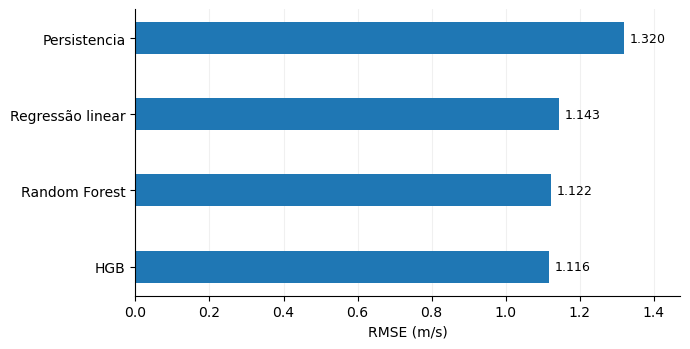

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_01_COMPARACAO_MODELOS_VALIDACAO.png


In [66]:
# ============================================================
# FIGURA 01 — COMPARAÇÃO DOS MODELOS NA VALIDAÇÃO
# ============================================================

import matplotlib.pyplot as plt

dados_grafico_modelos = comparacao_modelos_bloco_a.copy()

dados_grafico_modelos["modelo"] = dados_grafico_modelos["modelo"].replace({
    "Regressao Linear": "Regressão linear",
    "HistGradientBoosting": "HGB"
})

dados_grafico_modelos = dados_grafico_modelos.sort_values(
    "RMSE",
    ascending=True
)

fig, ax = plt.subplots(figsize=(7.0, 3.6))

barras = ax.barh(
    dados_grafico_modelos["modelo"],
    dados_grafico_modelos["RMSE"],
    height=0.42
)

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Valores no final das barras
for barra, valor in zip(
    barras,
    dados_grafico_modelos["RMSE"]
):
    ax.text(
        valor + 0.015,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    dados_grafico_modelos["RMSE"].max() + 0.15
)

plt.tight_layout()

arquivo_grafico_1 = (
    PASTA_GRAFICOS /
    "FIGURA_01_COMPARACAO_MODELOS_VALIDACAO.png"
)

plt.savefig(
    arquivo_grafico_1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_1)

### Figura 02 — Comparação do desempenho final no conjunto de teste

A figura compara o baseline de persistência com o modelo HistGradientBoosting parcimonioso no período de teste de 2018–2020, utilizando o RMSE como métrica principal.

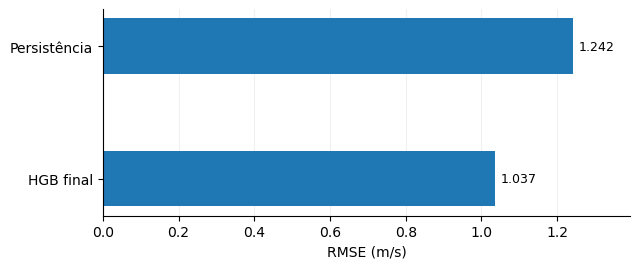

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_02_COMPARACAO_FINAL_TESTE.png


In [67]:
# ============================================================
# FIGURA 02 — PERSISTÊNCIA × HGB FINAL NO TESTE
# ============================================================

dados_teste_grafico = comparacao_teste_final.copy()

dados_teste_grafico["modelo"] = dados_teste_grafico["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

dados_teste_grafico = dados_teste_grafico.sort_values(
    "RMSE",
    ascending=True
)

fig, ax = plt.subplots(figsize=(6.5, 2.8))

barras = ax.barh(
    dados_teste_grafico["modelo"],
    dados_teste_grafico["RMSE"],
    height=0.42
)

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

for barra, valor in zip(
    barras,
    dados_teste_grafico["RMSE"]
):
    ax.text(
        valor + 0.015,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    dados_teste_grafico["RMSE"].max() + 0.15
)

plt.tight_layout()

arquivo_grafico_2 = (
    PASTA_GRAFICOS /
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

plt.savefig(
    arquivo_grafico_2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_2)

### Figura 03 — Série observada e prevista em uma janela do conjunto de teste

A figura apresenta uma janela de sete dias do período de teste, comparando a velocidade do vento observada com a previsão do modelo final.

O objetivo é visualizar o acompanhamento temporal da série pelo modelo sem sobrecarregar a figura com todo o período de 2018–2020.

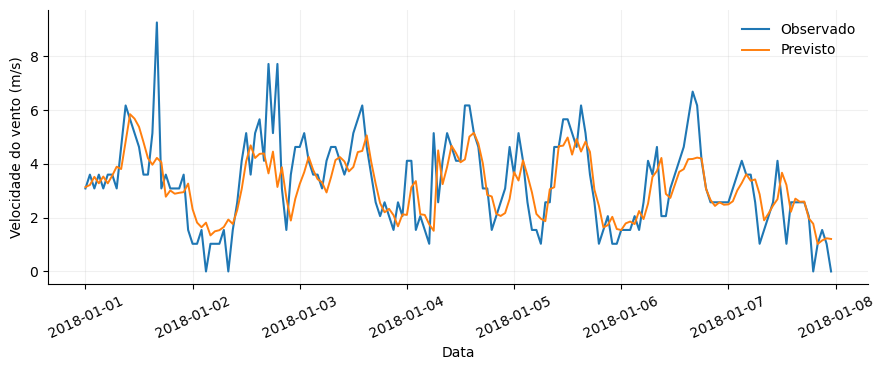

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_03_OBSERVADO_PREVISTO_7DIAS_TESTE.png


In [69]:
# ============================================================
# FIGURA 03 — OBSERVADO × PREVISTO EM JANELA DE 7 DIAS
# ============================================================

inicio_janela = pd.Timestamp("2018-01-01 00:00:00")
fim_janela = inicio_janela + pd.Timedelta(days=7)

janela_7d = previsoes_teste[
    (previsoes_teste["datetime_alvo"] >= inicio_janela) &
    (previsoes_teste["datetime_alvo"] < fim_janela)
].copy()

fig, ax = plt.subplots(figsize=(9.0, 3.8))

ax.plot(
    janela_7d["datetime_alvo"],
    janela_7d["vento_alvo_t1"],
    linewidth=1.5,
    label="Observado"
)

ax.plot(
    janela_7d["datetime_alvo"],
    janela_7d["pred_hgb_final"],
    linewidth=1.4,
    label="Previsto"
)

ax.set_xlabel("Data")
ax.set_ylabel("Velocidade do vento (m/s)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.18,
    linewidth=0.8
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.xticks(rotation=25)

plt.tight_layout()

arquivo_grafico_3 = (
    PASTA_GRAFICOS /
    "FIGURA_03_OBSERVADO_PREVISTO_7DIAS_TESTE.png"
)

plt.savefig(
    arquivo_grafico_3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_3)

### Figura 04 — Relação entre valores observados e previstos no conjunto de teste

A figura apresenta a relação entre a velocidade do vento observada e a prevista pelo modelo final no período de teste de 2018–2020.

A linha de referência 1:1 representa concordância perfeita entre observação e previsão.

O afastamento em relação a essa linha permite visualizar tendências de subestimação ou superestimação em diferentes faixas de velocidade.

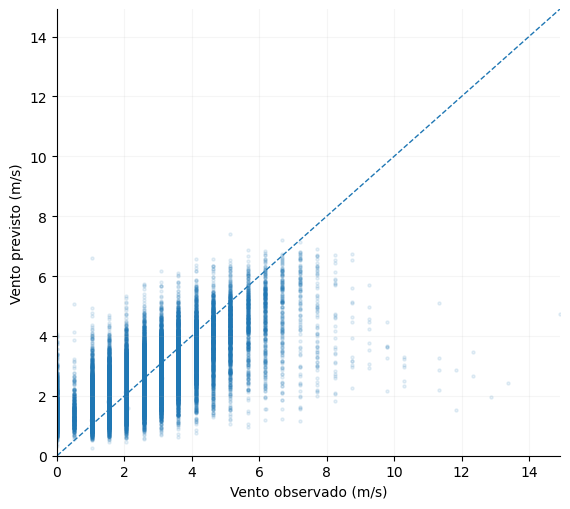

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_04_OBSERVADO_VS_PREVISTO_TESTE.png


In [71]:
# ============================================================
# FIGURA 04 — OBSERVADO × PREVISTO NO TESTE COMPLETO
# ============================================================

fig, ax = plt.subplots(figsize=(5.8, 5.2))

ax.scatter(
    previsoes_teste["vento_alvo_t1"],
    previsoes_teste["pred_hgb_final"],
    s=5,
    alpha=0.10
)

# Linha 1:1
lim_min = 0

lim_max = max(
    previsoes_teste["vento_alvo_t1"].max(),
    previsoes_teste["pred_hgb_final"].max()
)

ax.plot(
    [lim_min, lim_max],
    [lim_min, lim_max],
    linestyle="--",
    linewidth=1.0
)

ax.set_xlabel("Vento observado (m/s)")
ax.set_ylabel("Vento previsto (m/s)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.12,
    linewidth=0.8
)

ax.set_xlim(0, lim_max)
ax.set_ylim(0, lim_max)

plt.tight_layout()

arquivo_grafico_4 = (
    PASTA_GRAFICOS /
    "FIGURA_04_OBSERVADO_VS_PREVISTO_TESTE.png"
)

plt.savefig(
    arquivo_grafico_4,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_4)

### Figura 05 — Desempenho por hora do dia no conjunto de teste

A figura apresenta a variação do erro do modelo final ao longo das horas do dia no período de teste.

O objetivo é verificar se o desempenho preditivo apresenta padrão sistemático associado ao ciclo diário.

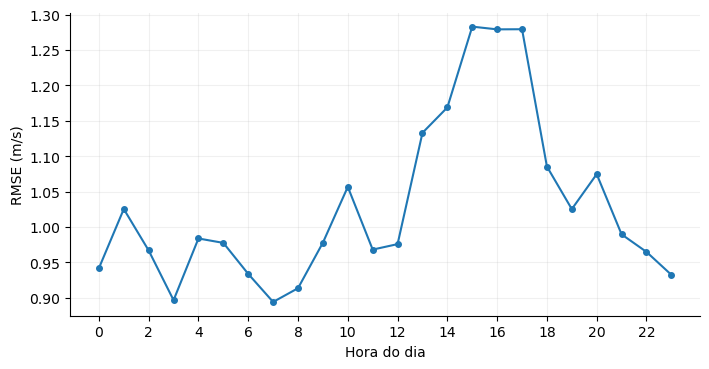

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_05_RMSE_POR_HORA_TESTE.png


In [72]:
# ============================================================
# FIGURA 05 — RMSE POR HORA DO DIA NO TESTE
# ============================================================

fig, ax = plt.subplots(figsize=(7.2, 3.8))

ax.plot(
    desempenho_hora_teste["hora_alvo"],
    desempenho_hora_teste["RMSE"],
    marker="o",
    linewidth=1.5,
    markersize=4
)

ax.set_xlabel("Hora do dia")
ax.set_ylabel("RMSE (m/s)")

ax.set_xticks(range(0, 24, 2))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.18,
    linewidth=0.8
)

plt.tight_layout()

arquivo_grafico_5 = (
    PASTA_GRAFICOS /
    "FIGURA_05_RMSE_POR_HORA_TESTE.png"
)

plt.savefig(
    arquivo_grafico_5,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_5)

### Interpretação do desempenho por hora do dia

O RMSE apresentou variação sistemática ao longo do ciclo diário.

Os menores erros ocorreram predominantemente durante a madrugada e o início da manhã, enquanto os maiores valores foram observados no período da tarde, com pico entre aproximadamente 15 h e 17 h.

Esse comportamento confirma o padrão identificado anteriormente na validação e indica que a dificuldade de previsão do modelo não é uniforme ao longo do dia.

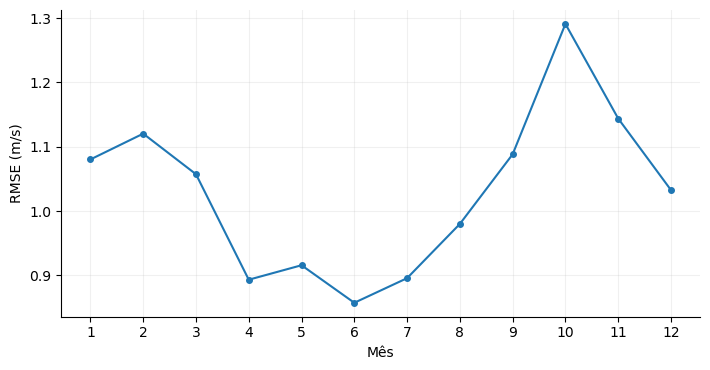

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_06_RMSE_POR_MES_TESTE.png


In [73]:
# ============================================================
# FIGURA 06 — RMSE POR MÊS NO TESTE
# ============================================================

fig, ax = plt.subplots(figsize=(7.2, 3.8))

ax.plot(
    desempenho_mes_teste["mes_alvo"],
    desempenho_mes_teste["RMSE"],
    marker="o",
    linewidth=1.5,
    markersize=4
)

ax.set_xlabel("Mês")
ax.set_ylabel("RMSE (m/s)")

ax.set_xticks(range(1, 13))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.18,
    linewidth=0.8
)

plt.tight_layout()

arquivo_grafico_6 = (
    PASTA_GRAFICOS /
    "FIGURA_06_RMSE_POR_MES_TESTE.png"
)

plt.savefig(
    arquivo_grafico_6,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_6)

### Interpretação do desempenho por mês

O RMSE apresentou variação sazonal ao longo do ano.

Os menores erros ocorreram principalmente entre abril e julho, com mínimo em junho. A partir de agosto, o erro aumentou progressivamente, atingindo o maior valor em outubro e permanecendo elevado em novembro.

Esse padrão reproduz o comportamento identificado durante a validação e indica que a dificuldade preditiva do modelo varia ao longo do ciclo anual.

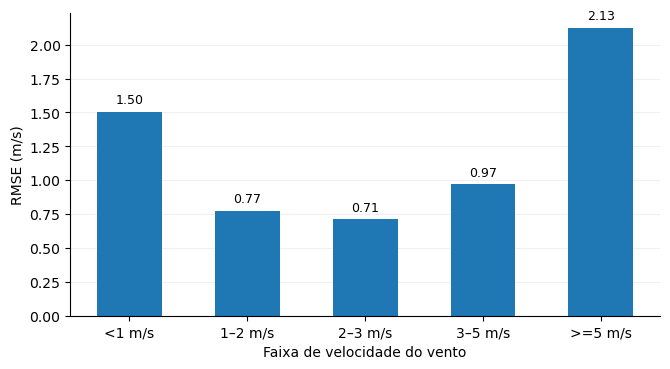

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_07_RMSE_POR_FAIXA_VENTO_TESTE.png


In [74]:
# ============================================================
# FIGURA 07 — RMSE POR FAIXA DE VELOCIDADE DO VENTO
# ============================================================

fig, ax = plt.subplots(figsize=(6.8, 3.8))

barras = ax.bar(
    desempenho_faixa_teste["faixa_vento"].astype(str),
    desempenho_faixa_teste["RMSE"],
    width=0.55
)

ax.set_xlabel("Faixa de velocidade do vento")
ax.set_ylabel("RMSE (m/s)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Valores acima das barras
for barra, valor in zip(
    barras,
    desempenho_faixa_teste["RMSE"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.04,
        f"{valor:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

arquivo_grafico_7 = (
    PASTA_GRAFICOS /
    "FIGURA_07_RMSE_POR_FAIXA_VENTO_TESTE.png"
)

plt.savefig(
    arquivo_grafico_7,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_7)

### Interpretação do desempenho por faixa de velocidade

O desempenho do modelo varia substancialmente conforme a faixa de velocidade do vento.

Os menores valores de RMSE ocorreram nas faixas intermediárias, especialmente entre 2 e 3 m/s, enquanto os maiores erros foram observados nos extremos da distribuição.

Para velocidades inferiores a 1 m/s, o RMSE foi aproximadamente 1,50 m/s. Para velocidades iguais ou superiores a 5 m/s, o RMSE aumentou para aproximadamente 2,13 m/s.

Esse resultado confirma que o modelo apresenta maior dificuldade em representar condições de calmaria e eventos de vento mais intenso.

### Figura 08 — Importância individual dos principais preditores

A figura apresenta os dez preditores com maior importância por permutação no conjunto de validação.

Valores maiores indicam maior perda de desempenho do modelo quando a variável é embaralhada, refletindo maior importância preditiva.

A interpretação deve considerar que variáveis correlacionadas podem compartilhar informação, reduzindo a importância aparente de cada uma individualmente.

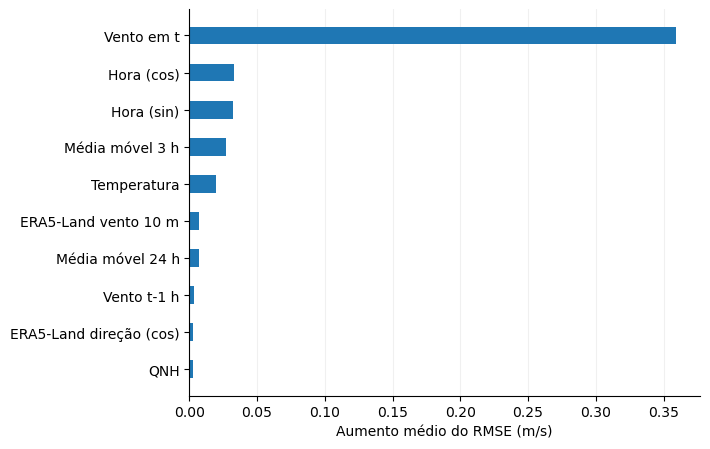

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_08_IMPORTANCIA_VARIAVEIS_TOP10.png


In [75]:
# ============================================================
# FIGURA 08 — TOP 10 IMPORTÂNCIA POR PERMUTAÇÃO
# ============================================================

top10_importancia = (
    importancia_perm
    .head(10)
    .copy()
    .sort_values(
        "importancia_media",
        ascending=True
    )
)

# Nomes mais legíveis
nomes_variaveis = {
    "vento_t": "Vento em t",
    "hora_cos": "Hora (cos)",
    "hora_sin": "Hora (sin)",
    "vento_media_3h": "Média móvel 3 h",
    "temperatura_c": "Temperatura",
    "era5land_vel_10m": "ERA5-Land vento 10 m",
    "vento_media_24h": "Média móvel 24 h",
    "vento_t_menos_1h": "Vento t-1 h",
    "era5land_dir_cos": "ERA5-Land direção (cos)",
    "qnh": "QNH"
}

top10_importancia["variavel_rotulo"] = (
    top10_importancia["variavel"]
    .replace(nomes_variaveis)
)

fig, ax = plt.subplots(figsize=(7.2, 4.6))

barras = ax.barh(
    top10_importancia["variavel_rotulo"],
    top10_importancia["importancia_media"],
    height=0.48
)

ax.set_xlabel("Aumento médio do RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

plt.tight_layout()

arquivo_grafico_8 = (
    PASTA_GRAFICOS /
    "FIGURA_08_IMPORTANCIA_VARIAVEIS_TOP10.png"
)

plt.savefig(
    arquivo_grafico_8,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_8)

### Figura 09 — Importância dos preditores secundários

Como a velocidade do vento no instante `t` apresenta importância muito superior às demais variáveis, é apresentada uma figura complementar excluindo esse preditor.

O objetivo é permitir a comparação visual entre os demais preditores relevantes sem alterar os valores originais de importância.

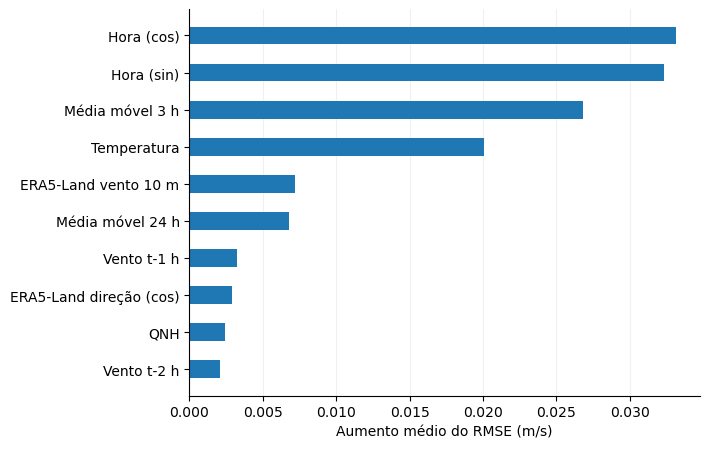

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_09_IMPORTANCIA_VARIAVEIS_SECUNDARIAS.png


In [76]:
# ============================================================
# FIGURA 09 — IMPORTÂNCIA DOS PREDITORES SECUNDÁRIOS
# ============================================================

top_secundarios = (
    importancia_perm[
        importancia_perm["variavel"] != "vento_t"
    ]
    .head(10)
    .copy()
    .sort_values(
        "importancia_media",
        ascending=True
    )
)

nomes_variaveis = {
    "hora_cos": "Hora (cos)",
    "hora_sin": "Hora (sin)",
    "vento_media_3h": "Média móvel 3 h",
    "temperatura_c": "Temperatura",
    "era5land_vel_10m": "ERA5-Land vento 10 m",
    "vento_media_24h": "Média móvel 24 h",
    "vento_t_menos_1h": "Vento t-1 h",
    "era5land_dir_cos": "ERA5-Land direção (cos)",
    "qnh": "QNH",
    "vento_t_menos_2h": "Vento t-2 h"
}

top_secundarios["variavel_rotulo"] = (
    top_secundarios["variavel"]
    .replace(nomes_variaveis)
)

fig, ax = plt.subplots(figsize=(7.2, 4.6))

ax.barh(
    top_secundarios["variavel_rotulo"],
    top_secundarios["importancia_media"],
    height=0.48
)

ax.set_xlabel("Aumento médio do RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

plt.tight_layout()

arquivo_grafico_9 = (
    PASTA_GRAFICOS /
    "FIGURA_09_IMPORTANCIA_VARIAVEIS_SECUNDARIAS.png"
)

plt.savefig(
    arquivo_grafico_9,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_9)

### Figura 10 — Importância dos grupos de preditores

A figura apresenta a importância por permutação dos principais grupos de preditores utilizados no modelo A+B+C1.

Cada valor representa o aumento médio do RMSE quando todas as variáveis de determinado grupo são permutadas conjuntamente.

Essa análise permite avaliar a contribuição relativa das diferentes fontes de informação de forma mais robusta do que a importância individual de variáveis correlacionadas.

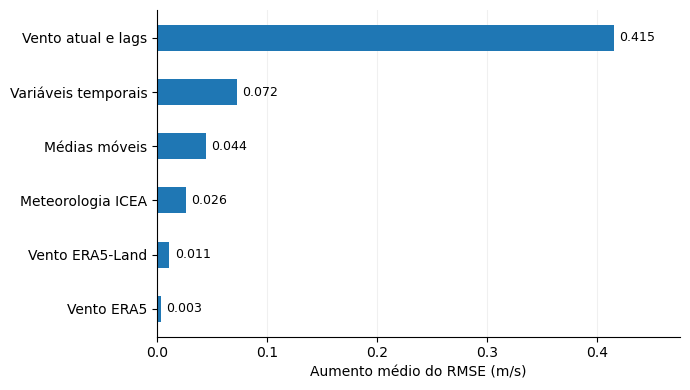

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_10_IMPORTANCIA_GRUPOS_PREDITORES.png


In [77]:
# ============================================================
# FIGURA 10 — IMPORTÂNCIA POR GRUPOS DE PREDITORES
# ============================================================

dados_grupos = (
    importancia_grupos
    .copy()
    .sort_values(
        "aumento_RMSE_medio",
        ascending=True
    )
)

nomes_grupos = {
    "Vento atual e lags": "Vento atual e lags",
    "Temporais": "Variáveis temporais",
    "Medias moveis": "Médias móveis",
    "Meteorologia ICEA": "Meteorologia ICEA",
    "ERA5-Land vento": "Vento ERA5-Land",
    "ERA5 vento": "Vento ERA5"
}

dados_grupos["grupo_rotulo"] = (
    dados_grupos["grupo"]
    .replace(nomes_grupos)
)

fig, ax = plt.subplots(figsize=(7.0, 4.0))

barras = ax.barh(
    dados_grupos["grupo_rotulo"],
    dados_grupos["aumento_RMSE_medio"],
    height=0.48
)

ax.set_xlabel("Aumento médio do RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

for barra, valor in zip(
    barras,
    dados_grupos["aumento_RMSE_medio"]
):
    ax.text(
        valor + 0.005,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    dados_grupos["aumento_RMSE_medio"].max() + 0.06
)

plt.tight_layout()

arquivo_grafico_10 = (
    PASTA_GRAFICOS /
    "FIGURA_10_IMPORTANCIA_GRUPOS_PREDITORES.png"
)

plt.savefig(
    arquivo_grafico_10,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_10)

### Interpretação da importância por grupos

A importância por grupos confirma que a previsão de curto prazo em `t+1` é fortemente determinada pelo estado atual e pelo histórico recente da velocidade do vento.

A permutação conjunta do grupo formado pelo vento atual e seus lags produziu aumento médio de aproximadamente 0,415 m/s no RMSE, valor muito superior ao observado para os demais grupos.

As variáveis temporais apresentaram a segunda maior contribuição, seguidas pelas médias móveis e pela meteorologia observada no ICEA.

As informações de vento provenientes das reanálises apresentaram contribuição complementar, com maior importância para o ERA5-Land do que para o ERA5.

Esse resultado reforça a adoção de um modelo parcimonioso, mantendo apenas grupos que apresentam contribuição preditiva mensurável.

## Síntese final do fluxo de modelagem

A tabela a seguir consolida as principais etapas de desenvolvimento do Artigo 3, incluindo baseline, modelos candidatos, inclusão incremental de blocos de preditores, seleção do modelo parcimonioso e desempenho final no conjunto de teste.

Essa síntese registra as decisões metodológicas tomadas ao longo do notebook e facilita a rastreabilidade dos resultados.

In [78]:
# ============================================================
# TABELA-SÍNTESE FINAL DO FLUXO METODOLÓGICO
# ============================================================

tabela_sintese_fluxo = pd.DataFrame([
    {
        "etapa": "Baseline",
        "modelo_bloco": "Persistência",
        "conjunto": "Validação",
        "n_preditores": 1,
        "MAE": metricas_validacao["MAE"],
        "RMSE": metricas_validacao["RMSE"],
        "R2": metricas_validacao["R2"],
        "decisao": "Referência mínima de desempenho"
    },
    {
        "etapa": "Modelo candidato",
        "modelo_bloco": "Regressão Linear - Bloco A",
        "conjunto": "Validação",
        "n_preditores": len(PREDITORES_BLOCO_A),
        "MAE": metricas_linear_validacao["MAE"],
        "RMSE": metricas_linear_validacao["RMSE"],
        "R2": metricas_linear_validacao["R2"],
        "decisao": "Superou a persistência"
    },
    {
        "etapa": "Modelo candidato",
        "modelo_bloco": "Random Forest - Bloco A",
        "conjunto": "Validação",
        "n_preditores": len(PREDITORES_BLOCO_A),
        "MAE": metricas_rf_validacao["MAE"],
        "RMSE": metricas_rf_validacao["RMSE"],
        "R2": metricas_rf_validacao["R2"],
        "decisao": "Melhora discreta sobre regressão linear"
    },
    {
        "etapa": "Modelo candidato",
        "modelo_bloco": "HGB - Bloco A",
        "conjunto": "Validação",
        "n_preditores": len(PREDITORES_BLOCO_A),
        "MAE": metricas_hgb_validacao["MAE"],
        "RMSE": metricas_hgb_validacao["RMSE"],
        "R2": metricas_hgb_validacao["R2"],
        "decisao": "Melhor algoritmo-base"
    },
    {
        "etapa": "Incremento de preditores",
        "modelo_bloco": "HGB - A+B",
        "conjunto": "Validação comparável",
        "n_preditores": len(PREDITORES_BLOCO_A + PREDITORES_B_PRINCIPAL),
        "MAE": metricas_hgb_ab["MAE"],
        "RMSE": metricas_hgb_ab["RMSE"],
        "R2": metricas_hgb_ab["R2"],
        "decisao": "Meteorologia ICEA mantida"
    },
    {
        "etapa": "Incremento de preditores",
        "modelo_bloco": "HGB - A+B+C1",
        "conjunto": "Validação comparável",
        "n_preditores": len(PREDITORES_ABC1),
        "MAE": metricas_hgb_abc1["MAE"],
        "RMSE": metricas_hgb_abc1["RMSE"],
        "R2": metricas_hgb_abc1["R2"],
        "decisao": "Vento de reanálise acrescenta ganho"
    },
    {
        "etapa": "Incremento de preditores",
        "modelo_bloco": "HGB - A+B+C2",
        "conjunto": "Validação comparável",
        "n_preditores": len(PREDITORES_ABC2),
        "MAE": metricas_hgb_abc2["MAE"],
        "RMSE": metricas_hgb_abc2["RMSE"],
        "R2": metricas_hgb_abc2["R2"],
        "decisao": "Ganho residual"
    },
    {
        "etapa": "Incremento de preditores",
        "modelo_bloco": "HGB - A+B+C3",
        "conjunto": "Validação comparável",
        "n_preditores": len(PREDITORES_ABC3),
        "MAE": metricas_hgb_abc3["MAE"],
        "RMSE": metricas_hgb_abc3["RMSE"],
        "R2": metricas_hgb_abc3["R2"],
        "decisao": "Melhor valor numérico, mas ganho mínimo sobre C1"
    },
    {
        "etapa": "Parcimônia",
        "modelo_bloco": "HGB - A+B+ERA5-Land",
        "conjunto": "Validação",
        "n_preditores": len(PREDITORES_PARCIMONIOSO),
        "MAE": metricas_hgb_parc["MAE"],
        "RMSE": metricas_hgb_parc["RMSE"],
        "R2": metricas_hgb_parc["R2"],
        "decisao": "Modelo candidato principal"
    },
    {
        "etapa": "Tuning",
        "modelo_bloco": "HGB parcimonioso ajustado",
        "conjunto": "Validação externa",
        "n_preditores": len(PREDITORES_PARCIMONIOSO),
        "MAE": metricas_hgb_ajustado_validacao["MAE"],
        "RMSE": metricas_hgb_ajustado_validacao["RMSE"],
        "R2": metricas_hgb_ajustado_validacao["R2"],
        "decisao": "Não superou configuração inicial"
    },
    {
        "etapa": "Avaliação final",
        "modelo_bloco": "Persistência",
        "conjunto": "Teste 2018–2020",
        "n_preditores": 1,
        "MAE": metricas_baseline_teste_final["MAE"],
        "RMSE": metricas_baseline_teste_final["RMSE"],
        "R2": metricas_baseline_teste_final["R2"],
        "decisao": "Baseline final"
    },
    {
        "etapa": "Avaliação final",
        "modelo_bloco": "HGB parcimonioso final",
        "conjunto": "Teste 2018–2020",
        "n_preditores": len(PREDITORES_PARCIMONIOSO),
        "MAE": metricas_teste_final["MAE"],
        "RMSE": metricas_teste_final["RMSE"],
        "R2": metricas_teste_final["R2"],
        "decisao": "Modelo final"
    }
])

display(
    tabela_sintese_fluxo.round(4)
)

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_sintese = (
    PASTA_TABELAS /
    "TABELA_SINTESE_FLUXO_METODOLOGICO_ARTIGO_3.csv"
)

tabela_sintese_fluxo.to_csv(
    arquivo_sintese,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_sintese)

,etapa,modelo_bloco,conjunto,n_preditores,MAE,RMSE,R2,decisao
0,Baseline,Persistência,Validação,1,0.9099,1.3204,0.2778,Referência mínima de desempenho
1,Modelo candidato,Regressão Linear - Bloco A,Validação,19,0.8252,1.1434,0.4584,Superou a persistência
2,Modelo candidato,Random Forest - Bloco A,Validação,19,0.8092,1.1224,0.4781,Melhora discreta sobre regressão linear
3,Modelo candidato,HGB - Bloco A,Validação,19,0.8031,1.1161,0.4839,Melhor algoritmo-base
4,Incremento de preditores,HGB - A+B,Validação comparável,24,0.7948,1.1055,0.4900,Meteorologia ICEA mantida
5,Incremento de preditores,HGB - A+B+C1,Validação comparável,30,0.7905,1.1002,0.4949,Vento de reanálise acrescenta ganho
6,Incremento de preditores,HGB - A+B+C2,Validação comparável,28,0.7939,1.1041,0.4913,Ganho residual
7,Incremento de preditores,HGB - A+B+C3,Validação comparável,34,0.7897,1.0996,0.4954,"Melhor valor numérico, mas ganho mínimo sobre C1"
8,Parcimônia,HGB - A+B+ERA5-Land,Validação,27,0.7903,1.1003,0.4949,Modelo candidato principal
9,Tuning,HGB parcimonioso ajustado,Validação externa,27,0.7906,1.1011,0.4941,Não superou configuração inicial



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_SINTESE_FLUXO_METODOLOGICO_ARTIGO_3.csv


## Encerramento do fluxo principal de modelagem

O fluxo principal de desenvolvimento do Artigo 3 foi concluído com definição da variável-alvo, construção dos preditores, divisão cronológica dos dados, estabelecimento de baseline, comparação de algoritmos, incorporação incremental de novos grupos de variáveis, análise de importância, experimentos de ablação, seleção por parcimônia, ajuste temporal de hiperparâmetros e avaliação final em período independente.

O modelo selecionado foi o HistGradientBoosting parcimonioso, composto pelos preditores históricos e temporais do Bloco A, pelas variáveis meteorológicas observadas do ICEA e pelas informações de vento do ERA5-Land.

O conjunto de teste de 2018–2020 permaneceu fora das etapas de seleção e ajuste e foi utilizado apenas na avaliação final.

As tabelas, previsões e figuras produzidas ao longo do fluxo foram exportadas para as respectivas pastas do projeto.

## Auditoria final do notebook

Antes de considerar o fluxo metodológico encerrado, é realizada uma auditoria final para verificar:

- existência das principais tabelas e figuras exportadas;
- coerência dos caminhos do projeto;
- disponibilidade das variáveis e objetos finais;
- consistência dos nomes dos blocos de preditores;
- presença dos resultados finais de validação e teste.

A auditoria não introduz novas análises. Seu objetivo é garantir reprodutibilidade e rastreabilidade do fluxo desenvolvido.

In [79]:
# ============================================================
# AUDITORIA FINAL DO NOTEBOOK — ARTIGO 3
# ============================================================

itens_auditoria = []

# ------------------------------------------------------------
# 1. Caminhos principais
# ------------------------------------------------------------

caminhos = {
    "PASTA_PROJETO": PASTA_PROJETO,
    "PASTA_DADOS": PASTA_DADOS,
    "PASTA_NOTEBOOKS": PASTA_NOTEBOOKS,
    "PASTA_RESULTADOS": PASTA_RESULTADOS,
    "PASTA_GRAFICOS": PASTA_GRAFICOS,
    "PASTA_TABELAS": PASTA_TABELAS,
    "PASTA_MODELOS": PASTA_MODELOS
}

for nome, caminho in caminhos.items():
    itens_auditoria.append({
        "categoria": "Caminho",
        "item": nome,
        "status": caminho.exists(),
        "detalhe": str(caminho)
    })

# ------------------------------------------------------------
# 2. Objetos principais em memória
# ------------------------------------------------------------

objetos_esperados = [
    "serie_alvo",
    "df_ml",
    "df_ml_b",
    "df_abc1",
    "treino_abc1",
    "validacao_abc1",
    "teste_abc1",
    "modelo_final",
    "comparacao_teste_final",
    "previsoes_teste",
    "importancia_perm",
    "importancia_grupos",
    "tabela_ablation",
    "tabela_sintese_fluxo"
]

for nome in objetos_esperados:
    existe = nome in globals()

    itens_auditoria.append({
        "categoria": "Objeto",
        "item": nome,
        "status": existe,
        "detalhe": "Disponível em memória" if existe else "Não encontrado"
    })

# ------------------------------------------------------------
# 3. Blocos de preditores
# ------------------------------------------------------------

blocos = {
    "Bloco A": PREDITORES_BLOCO_A,
    "Bloco B principal": PREDITORES_B_PRINCIPAL,
    "Bloco C1": PREDITORES_C1,
    "Bloco C2": PREDITORES_C2,
    "Modelo parcimonioso": PREDITORES_PARCIMONIOSO
}

for nome, variaveis in blocos.items():
    itens_auditoria.append({
        "categoria": "Bloco de preditores",
        "item": nome,
        "status": True,
        "detalhe": f"{len(variaveis)} preditores"
    })

# ------------------------------------------------------------
# 4. Arquivos principais esperados
# ------------------------------------------------------------

arquivos_esperados = [
    PASTA_TABELAS / "TABELA_BASELINE_PERSISTENCIA_T1_FINAL.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_MODELOS_BLOCO_A_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_BLOCO_A_VS_AB_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_AB_VS_ABC1_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_AB_VS_ABC2_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_BLOCOS_REANALISE_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_MODELO_COMPLETO_VS_PARCIMONIOSO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_HGB_INICIAL_VS_AJUSTADO_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_IMPORTANCIA_PERMUTACAO_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_IMPORTANCIA_GRUPOS_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_ABLACAO_GRUPOS_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv",
    PASTA_TABELAS / "TABELA_SINTESE_FLUXO_METODOLOGICO_ARTIGO_3.csv",
    PASTA_RESULTADOS / "PREVISOES_MODELO_FINAL_TESTE_2018_2020.csv"
]

for arquivo in arquivos_esperados:
    itens_auditoria.append({
        "categoria": "Arquivo",
        "item": arquivo.name,
        "status": arquivo.exists(),
        "detalhe": str(arquivo)
    })

# ------------------------------------------------------------
# 5. Figuras principais esperadas
# ------------------------------------------------------------

figuras_esperadas = [
    "FIGURA_01_COMPARACAO_MODELOS_VALIDACAO.png",
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png",
    "FIGURA_03_OBSERVADO_PREVISTO_7DIAS_TESTE.png",
    "FIGURA_04_OBSERVADO_VS_PREVISTO_TESTE.png",
    "FIGURA_05_RMSE_POR_HORA_TESTE.png",
    "FIGURA_06_RMSE_POR_MES_TESTE.png",
    "FIGURA_07_RMSE_POR_FAIXA_VENTO_TESTE.png",
    "FIGURA_08_IMPORTANCIA_VARIAVEIS_TOP10.png",
    "FIGURA_09_IMPORTANCIA_VARIAVEIS_SECUNDARIAS.png",
    "FIGURA_10_IMPORTANCIA_GRUPOS_PREDITORES.png"
]

for nome_figura in figuras_esperadas:
    arquivo = PASTA_GRAFICOS / nome_figura

    itens_auditoria.append({
        "categoria": "Figura",
        "item": nome_figura,
        "status": arquivo.exists(),
        "detalhe": str(arquivo)
    })

# ------------------------------------------------------------
# Consolidar auditoria
# ------------------------------------------------------------

auditoria_final = pd.DataFrame(itens_auditoria)

display(auditoria_final)

print("\nRESUMO")
print("-" * 50)
print("Itens verificados:", len(auditoria_final))
print("OK:", auditoria_final["status"].sum())
print("Pendentes:", (~auditoria_final["status"]).sum())

,categoria,item,status,detalhe
0,Caminho,PASTA_PROJETO,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML
1,Caminho,PASTA_DADOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\01_D...
2,Caminho,PASTA_NOTEBOOKS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\02_N...
3,Caminho,PASTA_RESULTADOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\03_R...
4,Caminho,PASTA_GRAFICOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_G...
5,Caminho,PASTA_TABELAS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_T...
6,Caminho,PASTA_MODELOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\06_M...
7,Objeto,serie_alvo,True,Disponível em memória
8,Objeto,df_ml,True,Disponível em memória
9,Objeto,df_ml_b,True,Disponível em memória



RESUMO
--------------------------------------------------
Itens verificados: 50
OK: 50
Pendentes: 0


## Status final do notebook

A auditoria final confirmou a existência e a disponibilidade de todos os principais objetos, tabelas, resultados e figuras produzidos no Artigo 3.

Foram verificados 50 itens, todos com status positivo, sem pendências de arquivos ou resultados.

Com isso, o fluxo principal de modelagem é considerado concluído e reprodutível dentro da estrutura atual do projeto.

## Extensão para múltiplos horizontes de previsão

Além do horizonte inicial de `t+1 h`, o desempenho do modelo será avaliado também para `t+3 h` e `t+6 h`.

A inclusão de múltiplos horizontes permite analisar a degradação da capacidade preditiva à medida que aumenta o intervalo entre o instante da previsão e o horário-alvo.

Os mesmos princípios metodológicos serão preservados:

- uso exclusivo de informações disponíveis até o instante `t`;
- manutenção da ordem temporal;
- separação entre treino, validação e teste;
- preservação de períodos temporais extensos, com no mínimo 10 anos no período de desenvolvimento do modelo;
- comparação com baseline de persistência específico para cada horizonte;
- utilização da mesma arquitetura de preditores e do mesmo modelo parcimonioso selecionado no horizonte `t+1 h`.

Essa estratégia permite comparar diretamente os horizontes sem introduzir diferenças metodológicas adicionais.

In [80]:
# ============================================================
# CRIAÇÃO DOS ALVOS PARA MÚLTIPLOS HORIZONTES
# ============================================================

def criar_alvo_horizonte(df, horas):
    """
    Cria alvo de velocidade do vento para t + horas,
    preservando também a proveniência do valor-alvo.
    """
    
    df_h = df.copy()
    
    df_h[f"vento_alvo_t{horas}"] = (
        df_h["vento_final"].shift(-horas)
    )
    
    df_h[f"fonte_alvo_t{horas}"] = (
        df_h["fonte_final"].shift(-horas)
    )
    
    df_h[f"alvo_reconstruido_t{horas}"] = (
        df_h["flag_reconstruido"].shift(-horas)
    )
    
    df_h[f"datetime_alvo_t{horas}"] = (
        df_h["datetime"] + pd.Timedelta(hours=horas)
    )
    
    return df_h


base_t3 = criar_alvo_horizonte(
    serie_alvo.sort_values("datetime").reset_index(drop=True),
    3
)

base_t6 = criar_alvo_horizonte(
    serie_alvo.sort_values("datetime").reset_index(drop=True),
    6
)

print("T+3:")
print(
    "Ausentes no alvo:",
    base_t3["vento_alvo_t3"].isna().sum()
)

print("\nT+6:")
print(
    "Ausentes no alvo:",
    base_t6["vento_alvo_t6"].isna().sum()
)

T+3:
Ausentes no alvo: 3

T+6:
Ausentes no alvo: 6


### Padronização dos experimentos para t+3 h e t+6 h

Os horizontes de `t+3 h` e `t+6 h` serão avaliados utilizando a mesma arquitetura de preditores e o mesmo algoritmo selecionado para `t+1 h`.

Essa decisão evita reotimização específica para cada horizonte e permite que as diferenças de desempenho sejam atribuídas principalmente ao aumento do intervalo de previsão.

Os cortes temporais permanecem:

- treino: 1991–2014;
- validação: 2015–2017;
- teste: 2018–2020.

O período de treinamento permanece superior ao mínimo de 10 anos definido para o estudo.

In [81]:
# ============================================================
# PIPELINE PADRONIZADO PARA T+3 E T+6
# ============================================================

def preparar_horizonte(base_h, horas):
    
    # Nome das colunas específicas do horizonte
    alvo = f"vento_alvo_t{horas}"
    datetime_alvo = f"datetime_alvo_t{horas}"
    fonte_alvo = f"fonte_alvo_t{horas}"
    flag_alvo = f"alvo_reconstruido_t{horas}"
    
    df = base_h.copy()

    # --------------------------------------------------------
    # Preditores históricos do vento
    # --------------------------------------------------------
    
    df["vento_t"] = df["vento_final"]

    for lag in [1, 2, 3, 6, 12, 24, 48, 72]:
        df[f"vento_t_menos_{lag}h"] = (
            df["vento_final"].shift(lag)
        )

    for janela in [3, 6, 12, 24]:
        df[f"vento_media_{janela}h"] = (
            df["vento_final"]
            .rolling(window=janela)
            .mean()
        )

    # --------------------------------------------------------
    # Variáveis temporais referentes ao horário-alvo
    # --------------------------------------------------------
    
    df["hora_alvo"] = df[datetime_alvo].dt.hour
    df["mes_alvo"] = df[datetime_alvo].dt.month
    df["dia_ano_alvo"] = df[datetime_alvo].dt.dayofyear

    df["hora_sin"] = np.sin(
        2 * np.pi * df["hora_alvo"] / 24
    )
    
    df["hora_cos"] = np.cos(
        2 * np.pi * df["hora_alvo"] / 24
    )

    df["mes_sin"] = np.sin(
        2 * np.pi * df["mes_alvo"] / 12
    )
    
    df["mes_cos"] = np.cos(
        2 * np.pi * df["mes_alvo"] / 12
    )

    df["dia_ano_sin"] = np.sin(
        2 * np.pi * df["dia_ano_alvo"] / 365.25
    )
    
    df["dia_ano_cos"] = np.cos(
        2 * np.pi * df["dia_ano_alvo"] / 365.25
    )

    # --------------------------------------------------------
    # Integrar meteorologia ICEA
    # --------------------------------------------------------
    
    df = (
        df
        .merge(
            temp_merge,
            on="datetime",
            how="left",
            validate="one_to_one"
        )
        .merge(
            pressao_merge,
            on="datetime",
            how="left",
            validate="one_to_one"
        )
        .merge(
            precip_merge,
            on="datetime",
            how="left",
            validate="one_to_one"
        )
    )

    # --------------------------------------------------------
    # Integrar ERA5-Land
    # --------------------------------------------------------
    
    df = df.merge(
        era5land_c1,
        on="datetime",
        how="left",
        validate="one_to_one"
    )

    # Direção circular ERA5-Land
    ang_rad = np.deg2rad(
        df["era5land_dir_10m"]
    )

    df["era5land_dir_sin"] = np.sin(ang_rad)
    df["era5land_dir_cos"] = np.cos(ang_rad)

    # --------------------------------------------------------
    # Exigir completude dos preditores do modelo parcimonioso
    # --------------------------------------------------------
    
    df = df.dropna(
        subset=PREDITORES_PARCIMONIOSO + [alvo]
    ).copy()

    # --------------------------------------------------------
    # Divisão temporal
    # --------------------------------------------------------
    
    treino_h = df[
        df[datetime_alvo] < "2015-01-01"
    ].copy()

    validacao_h = df[
        (df[datetime_alvo] >= "2015-01-01") &
        (df[datetime_alvo] < "2018-01-01")
    ].copy()

    teste_h = df[
        df[datetime_alvo] >= "2018-01-01"
    ].copy()

    return {
        "df": df,
        "treino": treino_h,
        "validacao": validacao_h,
        "teste": teste_h,
        "alvo": alvo,
        "datetime_alvo": datetime_alvo,
        "fonte_alvo": fonte_alvo,
        "flag_alvo": flag_alvo
    }


dados_t3 = preparar_horizonte(base_t3, 3)
dados_t6 = preparar_horizonte(base_t6, 6)

print("T+3")
print(
    len(dados_t3["treino"]),
    len(dados_t3["validacao"]),
    len(dados_t3["teste"])
)

print("\nT+6")
print(
    len(dados_t6["treino"]),
    len(dados_t6["validacao"]),
    len(dados_t6["teste"])
)

T+3
205551 25178 26185

T+6
205548 25178 26185


### Consistência amostral entre horizontes

Os horizontes de `t+3 h` e `t+6 h` preservaram praticamente a mesma estrutura amostral.

O conjunto de treino apresentou pequena redução no número de registros à medida que o horizonte aumentou, decorrente apenas do deslocamento adicional do alvo no final do período temporal.

Os conjuntos de validação e teste mantiveram exatamente o mesmo número de registros entre `t+3 h` e `t+6 h`, garantindo comparabilidade direta entre os horizontes.

In [82]:
# ============================================================
# AVALIAÇÃO DOS HORIZONTES T+3 E T+6
# Modelo parcimonioso fixo
# ============================================================

def avaliar_horizonte(dados_h, horas):

    treino_h = dados_h["treino"]
    validacao_h = dados_h["validacao"]
    teste_h = dados_h["teste"]

    alvo = dados_h["alvo"]

    # --------------------------------------------------------
    # Treino + validação
    # --------------------------------------------------------

    treino_final_h = pd.concat(
        [treino_h, validacao_h],
        axis=0
    ).sort_values("datetime")

    X_train_h = treino_final_h[
        PREDITORES_PARCIMONIOSO
    ]

    y_train_h = treino_final_h[
        alvo
    ]

    X_test_h = teste_h[
        PREDITORES_PARCIMONIOSO
    ]

    y_test_h = teste_h[
        alvo
    ]

    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_h = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=SEED
    )

    modelo_h.fit(
        X_train_h,
        y_train_h
    )

    pred_modelo = modelo_h.predict(
        X_test_h
    )

    # --------------------------------------------------------
    # Baseline de persistência
    # previsão t+h = vento em t
    # --------------------------------------------------------

    pred_persistencia = teste_h[
        "vento_t"
    ]

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    met_modelo = avaliar_previsao(
        y_test_h,
        pred_modelo
    )

    met_persist = avaliar_previsao(
        y_test_h,
        pred_persistencia
    )

    return {
        "horizonte_h": horas,
        "modelo": met_modelo,
        "persistencia": met_persist,
        "pred_modelo": pred_modelo,
        "pred_persistencia": pred_persistencia,
        "y_test": y_test_h,
        "modelo_obj": modelo_h,
        "teste": teste_h
    }


resultado_t3 = avaliar_horizonte(
    dados_t3,
    3
)

resultado_t6 = avaliar_horizonte(
    dados_t6,
    6
)

# ------------------------------------------------------------
# Tabela comparativa
# ------------------------------------------------------------

comparacao_horizontes = pd.DataFrame([
    {
        "horizonte": "t+1 h",
        "modelo": "Persistência",
        **metricas_baseline_teste_final
    },
    {
        "horizonte": "t+1 h",
        "modelo": "HGB",
        **metricas_teste_final
    },
    {
        "horizonte": "t+3 h",
        "modelo": "Persistência",
        **resultado_t3["persistencia"]
    },
    {
        "horizonte": "t+3 h",
        "modelo": "HGB",
        **resultado_t3["modelo"]
    },
    {
        "horizonte": "t+6 h",
        "modelo": "Persistência",
        **resultado_t6["persistencia"]
    },
    {
        "horizonte": "t+6 h",
        "modelo": "HGB",
        **resultado_t6["modelo"]
    }
])

display(
    comparacao_horizontes.round(4)
)

,horizonte,modelo,MAE,RMSE,R2
0,t+1 h,Persistência,0.8783,1.2424,0.3126
1,t+1 h,HGB,0.7568,1.0369,0.5212
2,t+3 h,Persistência,1.1910,1.6076,-0.1497
3,t+3 h,HGB,0.8860,1.1841,0.3763
4,t+6 h,Persistência,1.4345,1.8773,-0.5664
5,t+6 h,HGB,0.9371,1.2421,0.3143


### Desempenho em múltiplos horizontes de previsão

A extensão do experimento para `t+3 h` e `t+6 h` mostrou degradação progressiva do desempenho à medida que o horizonte de previsão aumenta.

No horizonte de `t+1 h`, o modelo HistGradientBoosting apresentou RMSE de 1,0369 m/s e R² de 0,5212.

Em `t+3 h`, o RMSE aumentou para 1,1841 m/s e o R² foi reduzido para 0,3763. Em `t+6 h`, o RMSE atingiu 1,2421 m/s e o R² foi 0,3143.

Apesar da degradação com o aumento do horizonte, o modelo manteve desempenho superior ao baseline de persistência em todos os casos.

A persistência apresentou R² negativo nos horizontes de `t+3 h` e `t+6 h`, indicando perda substancial de capacidade preditiva quando o valor observado no instante `t` é simplesmente propagado para horizontes mais distantes.

Esses resultados mostram que a contribuição do modelo de aprendizado de máquina se torna relativamente mais importante à medida que aumenta o horizonte de previsão.

In [83]:
# ============================================================
# GANHO RELATIVO DO HGB POR HORIZONTE
# ============================================================

ganhos_horizontes = []

for horizonte in ["t+1 h", "t+3 h", "t+6 h"]:

    linha_persist = comparacao_horizontes[
        (comparacao_horizontes["horizonte"] == horizonte) &
        (comparacao_horizontes["modelo"] == "Persistência")
    ].iloc[0]

    linha_hgb = comparacao_horizontes[
        (comparacao_horizontes["horizonte"] == horizonte) &
        (comparacao_horizontes["modelo"] == "HGB")
    ].iloc[0]

    ganho_mae = (
        100 *
        (linha_persist["MAE"] - linha_hgb["MAE"])
        / linha_persist["MAE"]
    )

    ganho_rmse = (
        100 *
        (linha_persist["RMSE"] - linha_hgb["RMSE"])
        / linha_persist["RMSE"]
    )

    ganhos_horizontes.append({
        "horizonte": horizonte,
        "MAE_persistencia": linha_persist["MAE"],
        "MAE_HGB": linha_hgb["MAE"],
        "ganho_MAE_pct": ganho_mae,
        "RMSE_persistencia": linha_persist["RMSE"],
        "RMSE_HGB": linha_hgb["RMSE"],
        "ganho_RMSE_pct": ganho_rmse,
        "R2_HGB": linha_hgb["R2"]
    })

tabela_ganhos_horizontes = pd.DataFrame(
    ganhos_horizontes
)

display(
    tabela_ganhos_horizontes.round(4)
)

arquivo_ganhos_horizontes = (
    PASTA_TABELAS /
    "TABELA_GANHO_HGB_POR_HORIZONTE.csv"
)

tabela_ganhos_horizontes.to_csv(
    arquivo_ganhos_horizontes,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_ganhos_horizontes)

,horizonte,MAE_persistencia,MAE_HGB,ganho_MAE_pct,RMSE_persistencia,RMSE_HGB,ganho_RMSE_pct,R2_HGB
0,t+1 h,0.8783,0.7568,13.8350,1.2424,1.0369,16.5444,0.5212
1,t+3 h,1.1910,0.8860,25.6092,1.6076,1.1841,26.3447,0.3763
2,t+6 h,1.4345,0.9371,34.6781,1.8773,1.2421,33.8369,0.3143



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_GANHO_HGB_POR_HORIZONTE.csv


### Ganho relativo do modelo em diferentes horizontes

O ganho do HistGradientBoosting em relação ao baseline de persistência aumentou progressivamente com o horizonte de previsão.

A redução relativa do RMSE foi de aproximadamente 16,54% em `t+1 h`, 26,34% em `t+3 h` e 33,84% em `t+6 h`.

Esse comportamento mostra que, embora a dificuldade absoluta de previsão aumente com o horizonte, o modelo de aprendizado de máquina preserva capacidade preditiva superior à persistência e amplia sua vantagem relativa em horizontes mais longos.

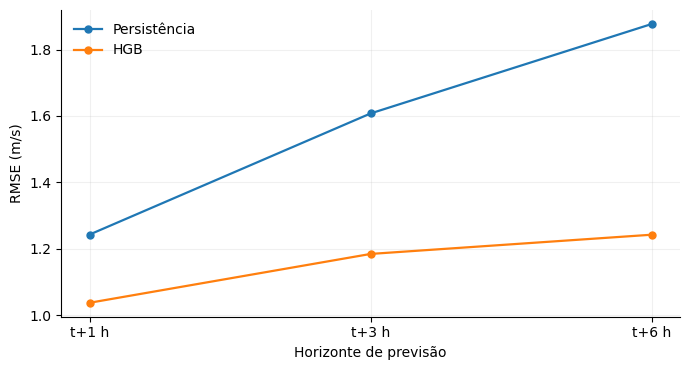

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_11_RMSE_POR_HORIZONTE.png


In [84]:
# ============================================================
# FIGURA 11 — RMSE POR HORIZONTE DE PREVISÃO
# ============================================================

dados_rmse_horizonte = comparacao_horizontes[
    ["horizonte", "modelo", "RMSE"]
].copy()

ordem_horizontes = ["t+1 h", "t+3 h", "t+6 h"]

fig, ax = plt.subplots(figsize=(7.0, 3.8))

for modelo in ["Persistência", "HGB"]:
    
    dados_modelo = dados_rmse_horizonte[
        dados_rmse_horizonte["modelo"] == modelo
    ].copy()

    dados_modelo["horizonte"] = pd.Categorical(
        dados_modelo["horizonte"],
        categories=ordem_horizontes,
        ordered=True
    )

    dados_modelo = dados_modelo.sort_values("horizonte")

    ax.plot(
        dados_modelo["horizonte"],
        dados_modelo["RMSE"],
        marker="o",
        linewidth=1.6,
        markersize=5,
        label=modelo
    )

ax.set_xlabel("Horizonte de previsão")
ax.set_ylabel("RMSE (m/s)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.18,
    linewidth=0.8
)

ax.legend(
    frameon=False
)

plt.tight_layout()

arquivo_grafico_11 = (
    PASTA_GRAFICOS /
    "FIGURA_11_RMSE_POR_HORIZONTE.png"
)

plt.savefig(
    arquivo_grafico_11,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_11)

### Interpretação do desempenho por horizonte

O aumento do horizonte de previsão elevou o RMSE tanto para o baseline de persistência quanto para o modelo HistGradientBoosting.

Entretanto, a degradação foi mais acentuada para a persistência. O RMSE desse baseline aumentou de aproximadamente 1,24 m/s em `t+1 h` para 1,88 m/s em `t+6 h`.

No HistGradientBoosting, o RMSE aumentou de aproximadamente 1,04 para 1,24 m/s no mesmo intervalo.

Assim, embora a incerteza aumente com o horizonte, o modelo de aprendizado de máquina preserva desempenho superior e amplia sua vantagem relativa em relação à persistência.

## Auditoria final atualizada

Após a inclusão dos horizontes adicionais de previsão (`t+3 h` e `t+6 h`), a auditoria final é atualizada para verificar também os novos objetos, tabelas e figuras produzidos.

O objetivo permanece o mesmo: garantir que o fluxo metodológico esteja completo, reprodutível e com todos os principais artefatos salvos.

In [85]:
# ============================================================
# AUDITORIA FINAL ATUALIZADA — ARTIGO 3
# ============================================================

itens_auditoria_atualizada = []

# ------------------------------------------------------------
# 1. Caminhos principais
# ------------------------------------------------------------

caminhos = {
    "PASTA_PROJETO": PASTA_PROJETO,
    "PASTA_DADOS": PASTA_DADOS,
    "PASTA_NOTEBOOKS": PASTA_NOTEBOOKS,
    "PASTA_RESULTADOS": PASTA_RESULTADOS,
    "PASTA_GRAFICOS": PASTA_GRAFICOS,
    "PASTA_TABELAS": PASTA_TABELAS,
    "PASTA_MODELOS": PASTA_MODELOS
}

for nome, caminho in caminhos.items():
    itens_auditoria_atualizada.append({
        "categoria": "Caminho",
        "item": nome,
        "status": caminho.exists(),
        "detalhe": str(caminho)
    })

# ------------------------------------------------------------
# 2. Objetos principais
# ------------------------------------------------------------

objetos_esperados = [
    "serie_alvo",
    "df_ml",
    "df_ml_b",
    "df_abc1",
    "treino_abc1",
    "validacao_abc1",
    "teste_abc1",
    "modelo_final",
    "comparacao_teste_final",
    "previsoes_teste",
    "importancia_perm",
    "importancia_grupos",
    "tabela_ablation",
    "tabela_sintese_fluxo",
    "base_t3",
    "base_t6",
    "dados_t3",
    "dados_t6",
    "resultado_t3",
    "resultado_t6",
    "comparacao_horizontes",
    "tabela_ganhos_horizontes"
]

for nome in objetos_esperados:
    existe = nome in globals()

    itens_auditoria_atualizada.append({
        "categoria": "Objeto",
        "item": nome,
        "status": existe,
        "detalhe": "Disponível em memória" if existe else "Não encontrado"
    })

# ------------------------------------------------------------
# 3. Arquivos principais
# ------------------------------------------------------------

arquivos_esperados = [
    PASTA_TABELAS / "TABELA_BASELINE_PERSISTENCIA_T1_FINAL.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_MODELOS_BLOCO_A_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_BLOCO_A_VS_AB_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_AB_VS_ABC1_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_AB_VS_ABC2_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_BLOCOS_REANALISE_HGB_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_MODELO_COMPLETO_VS_PARCIMONIOSO.csv",
    PASTA_TABELAS / "TABELA_COMPARACAO_HGB_INICIAL_VS_AJUSTADO_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_IMPORTANCIA_PERMUTACAO_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_IMPORTANCIA_GRUPOS_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_ABLACAO_GRUPOS_HGB_ABC1_VALIDACAO.csv",
    PASTA_TABELAS / "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv",
    PASTA_TABELAS / "TABELA_SINTESE_FLUXO_METODOLOGICO_ARTIGO_3.csv",
    PASTA_TABELAS / "TABELA_GANHO_HGB_POR_HORIZONTE.csv",
    PASTA_RESULTADOS / "PREVISOES_MODELO_FINAL_TESTE_2018_2020.csv"
]

for arquivo in arquivos_esperados:
    itens_auditoria_atualizada.append({
        "categoria": "Arquivo",
        "item": arquivo.name,
        "status": arquivo.exists(),
        "detalhe": str(arquivo)
    })

# ------------------------------------------------------------
# 4. Figuras esperadas
# ------------------------------------------------------------

figuras_esperadas = [
    "FIGURA_01_COMPARACAO_MODELOS_VALIDACAO.png",
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png",
    "FIGURA_03_OBSERVADO_PREVISTO_7DIAS_TESTE.png",
    "FIGURA_04_OBSERVADO_VS_PREVISTO_TESTE.png",
    "FIGURA_05_RMSE_POR_HORA_TESTE.png",
    "FIGURA_06_RMSE_POR_MES_TESTE.png",
    "FIGURA_07_RMSE_POR_FAIXA_VENTO_TESTE.png",
    "FIGURA_08_IMPORTANCIA_VARIAVEIS_TOP10.png",
    "FIGURA_09_IMPORTANCIA_VARIAVEIS_SECUNDARIAS.png",
    "FIGURA_10_IMPORTANCIA_GRUPOS_PREDITORES.png",
    "FIGURA_11_RMSE_POR_HORIZONTE.png"
]

for nome_figura in figuras_esperadas:
    arquivo = PASTA_GRAFICOS / nome_figura

    itens_auditoria_atualizada.append({
        "categoria": "Figura",
        "item": nome_figura,
        "status": arquivo.exists(),
        "detalhe": str(arquivo)
    })

# ------------------------------------------------------------
# Consolidar auditoria
# ------------------------------------------------------------

auditoria_final_atualizada = pd.DataFrame(
    itens_auditoria_atualizada
)

display(auditoria_final_atualizada)

print("\nRESUMO FINAL ATUALIZADO")
print("-" * 50)
print(
    "Itens verificados:",
    len(auditoria_final_atualizada)
)
print(
    "OK:",
    auditoria_final_atualizada["status"].sum()
)
print(
    "Pendentes:",
    (~auditoria_final_atualizada["status"]).sum()
)

,categoria,item,status,detalhe
0,Caminho,PASTA_PROJETO,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML
1,Caminho,PASTA_DADOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\01_D...
2,Caminho,PASTA_NOTEBOOKS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\02_N...
3,Caminho,PASTA_RESULTADOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\03_R...
4,Caminho,PASTA_GRAFICOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_G...
5,Caminho,PASTA_TABELAS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_T...
6,Caminho,PASTA_MODELOS,True,D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\06_M...
7,Objeto,serie_alvo,True,Disponível em memória
8,Objeto,df_ml,True,Disponível em memória
9,Objeto,df_ml_b,True,Disponível em memória



RESUMO FINAL ATUALIZADO
--------------------------------------------------
Itens verificados: 55
OK: 55
Pendentes: 0


## Encerramento definitivo do notebook

A auditoria final atualizada confirmou a disponibilidade de todos os objetos, tabelas, resultados e figuras produzidos ao longo do Artigo 3.

Foram verificados 55 itens, todos com status positivo e nenhuma pendência identificada.

O fluxo metodológico contempla:

- definição da variável-alvo;
- construção de preditores temporais, históricos, meteorológicos e de reanálise;
- divisão cronológica entre treino, validação e teste;
- baseline de persistência;
- comparação entre algoritmos;
- inclusão incremental de blocos de preditores;
- análise de importância e ablação;
- seleção por parcimônia;
- ajuste temporal de hiperparâmetros;
- avaliação final em período independente;
- diagnóstico por hora, mês e faixa de velocidade;
- avaliação em múltiplos horizontes de previsão (`t+1 h`, `t+3 h` e `t+6 h`);
- geração e exportação das tabelas, previsões e figuras finais.

Com isso, o notebook é considerado metodologicamente concluído e apto a servir de base para a redação do Artigo 3.

## Modelagem contemporânea do vento — t → t

Além dos experimentos de previsão futura, é realizado um experimento de modelagem contemporânea.

Nesse caso, a variável-alvo é a velocidade do vento no próprio instante `t`, estimada a partir de outras informações meteorológicas e temporais disponíveis no mesmo horário.

Diferentemente dos experimentos de previsão (`t+1 h`, `t+3 h` e `t+6 h`), não são utilizados como preditores a própria velocidade do vento em `t`, seus lags ou médias móveis.

Essa restrição evita circularidade e permite avaliar em que medida o vento pode ser representado a partir de variáveis meteorológicas, temporais e de reanálise.

O experimento mantém a divisão cronológica já adotada:

- treino: 1991–2014;
- validação: 2015–2017;
- teste: 2018–2020.

O período de desenvolvimento do modelo permanece superior ao mínimo de 10 anos definido para o estudo.

In [86]:
# ============================================================
# MODELAGEM CONTEMPORÂNEA — t → t
# vento(t) a partir de outras variáveis
# ============================================================

df_t0 = df_abc3.copy()

# ------------------------------------------------------------
# 1. Alvo contemporâneo
# ------------------------------------------------------------

ALVO_T0 = "vento_final"

# ------------------------------------------------------------
# 2. Variáveis temporais do próprio instante t
# ------------------------------------------------------------

df_t0["hora_t0"] = df_t0["datetime"].dt.hour
df_t0["mes_t0"] = df_t0["datetime"].dt.month
df_t0["dia_ano_t0"] = df_t0["datetime"].dt.dayofyear

df_t0["hora_t0_sin"] = np.sin(
    2 * np.pi * df_t0["hora_t0"] / 24
)

df_t0["hora_t0_cos"] = np.cos(
    2 * np.pi * df_t0["hora_t0"] / 24
)

df_t0["mes_t0_sin"] = np.sin(
    2 * np.pi * df_t0["mes_t0"] / 12
)

df_t0["mes_t0_cos"] = np.cos(
    2 * np.pi * df_t0["mes_t0"] / 12
)

df_t0["dia_ano_t0_sin"] = np.sin(
    2 * np.pi * df_t0["dia_ano_t0"] / 365.25
)

df_t0["dia_ano_t0_cos"] = np.cos(
    2 * np.pi * df_t0["dia_ano_t0"] / 365.25
)

# ------------------------------------------------------------
# 3. Preditores contemporâneos
# SEM vento_t, lags ou médias móveis do próprio vento
# ------------------------------------------------------------

PREDITORES_T0 = [
    # Temporais
    "hora_t0_sin",
    "hora_t0_cos",
    "mes_t0_sin",
    "mes_t0_cos",
    "dia_ano_t0_sin",
    "dia_ano_t0_cos",

    # Meteorologia observada ICEA
    "temperatura_c",
    "ponto_orvalho_c",
    "qnh",
    "qfe",
    "precip",

    # Vento ERA5-Land
    "era5land_vel_10m",
    "era5land_dir_sin",
    "era5land_dir_cos",

    # Meteorologia ERA5
    "era5_temp_c",
    "era5_ponto_orvalho_c",
    "era5_pressao_hpa",
    "era5_precipitacao_mm"
]

print(f"Preditores contemporâneos: {len(PREDITORES_T0)}")

# ------------------------------------------------------------
# 4. Base complete-case
# ------------------------------------------------------------

df_t0_modelo = (
    df_t0
    .dropna(
        subset=PREDITORES_T0 + [ALVO_T0]
    )
    .copy()
)

print(f"Registros utilizáveis: {len(df_t0_modelo):,}")

# ------------------------------------------------------------
# 5. Divisão cronológica
# ------------------------------------------------------------

treino_t0 = df_t0_modelo[
    df_t0_modelo["datetime"] < "2015-01-01"
].copy()

validacao_t0 = df_t0_modelo[
    (df_t0_modelo["datetime"] >= "2015-01-01") &
    (df_t0_modelo["datetime"] < "2018-01-01")
].copy()

teste_t0 = df_t0_modelo[
    df_t0_modelo["datetime"] >= "2018-01-01"
].copy()

resumo_t0 = pd.DataFrame([
    {
        "conjunto": "Treino",
        "inicio": treino_t0["datetime"].min(),
        "fim": treino_t0["datetime"].max(),
        "n": len(treino_t0)
    },
    {
        "conjunto": "Validação",
        "inicio": validacao_t0["datetime"].min(),
        "fim": validacao_t0["datetime"].max(),
        "n": len(validacao_t0)
    },
    {
        "conjunto": "Teste",
        "inicio": teste_t0["datetime"].min(),
        "fim": teste_t0["datetime"].max(),
        "n": len(teste_t0)
    }
])

display(resumo_t0)

Preditores contemporâneos: 18
Registros utilizáveis: 256,987


,conjunto,inicio,fim,n
0,Treino,1991-01-01,2014-12-31 23:00:00,205625
1,Validação,2015-01-01,2017-12-31 23:00:00,25178
2,Teste,2018-01-01,2020-12-31 22:00:00,26184


### Verificação do período da modelagem contemporânea

A modelagem contemporânea utiliza a velocidade do vento no próprio instante `t` como variável-alvo.

Antes do treinamento, verifica-se se a base cobre integralmente o período de 1991–2020, pois, diferentemente dos experimentos de previsão futura, não há necessidade de perda das últimas horas da série em função de deslocamento do alvo.

In [87]:
# ============================================================
# VERIFICAÇÃO DO LIMITE TEMPORAL — MODELAGEM t → t
# ============================================================

print("Último horário em df_t0:")
print(df_t0["datetime"].max())

print("\nÚltimo horário em df_t0_modelo:")
print(df_t0_modelo["datetime"].max())

print("\nRegistro de 2020-12-31 23:00 existe em df_t0?")
print(
    (df_t0["datetime"] == pd.Timestamp("2020-12-31 23:00:00")).any()
)

print("\nRegistro de 2020-12-31 23:00 existe em df_t0_modelo?")
print(
    (df_t0_modelo["datetime"] == pd.Timestamp("2020-12-31 23:00:00")).any()
)

Último horário em df_t0:
2020-12-31 22:00:00

Último horário em df_t0_modelo:
2020-12-31 22:00:00

Registro de 2020-12-31 23:00 existe em df_t0?
False

Registro de 2020-12-31 23:00 existe em df_t0_modelo?
False


### Correção da base contemporânea

A primeira versão da base de modelagem `t → t` foi derivada de uma estrutura construída originalmente para previsão em `t+1 h`. Como essa estrutura já havia removido a última hora da série por ausência de alvo futuro, o registro de 2020-12-31 23:00 foi perdido de forma desnecessária.

Para a modelagem contemporânea, essa restrição não se aplica. A base é, portanto, reconstruída diretamente a partir da série final do Artigo 2, preservando integralmente o período de 1991–2020.

In [88]:
# ============================================================
# RECONSTRUÇÃO CORRETA DA BASE CONTEMPORÂNEA — t → t
# ============================================================

# Começar diretamente da série final do Artigo 2
df_t0 = (
    serie_alvo
    .sort_values("datetime")
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# Integrar meteorologia ICEA
# ------------------------------------------------------------

df_t0 = (
    df_t0
    .merge(
        temp_merge,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
    .merge(
        pressao_merge,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
    .merge(
        precip_merge,
        on="datetime",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# Integrar ERA5-Land
# ------------------------------------------------------------

df_t0 = df_t0.merge(
    era5land_c1,
    on="datetime",
    how="left",
    validate="one_to_one"
)

ang_rad = np.deg2rad(
    df_t0["era5land_dir_10m"]
)

df_t0["era5land_dir_sin"] = np.sin(ang_rad)
df_t0["era5land_dir_cos"] = np.cos(ang_rad)

# ------------------------------------------------------------
# Integrar meteorologia ERA5
# ------------------------------------------------------------

df_t0 = df_t0.merge(
    era5_c2,
    on="datetime",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Variáveis temporais contemporâneas
# ------------------------------------------------------------

df_t0["hora_t0"] = df_t0["datetime"].dt.hour
df_t0["mes_t0"] = df_t0["datetime"].dt.month
df_t0["dia_ano_t0"] = df_t0["datetime"].dt.dayofyear

df_t0["hora_t0_sin"] = np.sin(
    2 * np.pi * df_t0["hora_t0"] / 24
)

df_t0["hora_t0_cos"] = np.cos(
    2 * np.pi * df_t0["hora_t0"] / 24
)

df_t0["mes_t0_sin"] = np.sin(
    2 * np.pi * df_t0["mes_t0"] / 12
)

df_t0["mes_t0_cos"] = np.cos(
    2 * np.pi * df_t0["mes_t0"] / 12
)

df_t0["dia_ano_t0_sin"] = np.sin(
    2 * np.pi * df_t0["dia_ano_t0"] / 365.25
)

df_t0["dia_ano_t0_cos"] = np.cos(
    2 * np.pi * df_t0["dia_ano_t0"] / 365.25
)

# ------------------------------------------------------------
# Preditores contemporâneos
# ------------------------------------------------------------

PREDITORES_T0 = [
    "hora_t0_sin",
    "hora_t0_cos",
    "mes_t0_sin",
    "mes_t0_cos",
    "dia_ano_t0_sin",
    "dia_ano_t0_cos",

    "temperatura_c",
    "ponto_orvalho_c",
    "qnh",
    "qfe",
    "precip",

    "era5land_vel_10m",
    "era5land_dir_sin",
    "era5land_dir_cos",

    "era5_temp_c",
    "era5_ponto_orvalho_c",
    "era5_pressao_hpa",
    "era5_precipitacao_mm"
]

ALVO_T0 = "vento_final"

# ------------------------------------------------------------
# Complete-case
# ------------------------------------------------------------

df_t0_modelo = (
    df_t0
    .dropna(
        subset=PREDITORES_T0 + [ALVO_T0]
    )
    .copy()
)

# ------------------------------------------------------------
# Divisão temporal
# ------------------------------------------------------------

treino_t0 = df_t0_modelo[
    df_t0_modelo["datetime"] < "2015-01-01"
].copy()

validacao_t0 = df_t0_modelo[
    (df_t0_modelo["datetime"] >= "2015-01-01") &
    (df_t0_modelo["datetime"] < "2018-01-01")
].copy()

teste_t0 = df_t0_modelo[
    df_t0_modelo["datetime"] >= "2018-01-01"
].copy()

print("Último horário da base completa:")
print(df_t0["datetime"].max())

print("\nÚltimo horário da base de modelagem:")
print(df_t0_modelo["datetime"].max())

print("\nTamanhos:")
print("Treino:", len(treino_t0))
print("Validação:", len(validacao_t0))
print("Teste:", len(teste_t0))

Último horário da base completa:
2020-12-31 23:00:00

Último horário da base de modelagem:
2020-12-31 23:00:00

Tamanhos:
Treino: 205625
Validação: 25178
Teste: 26185


## Modelagem contemporânea — comparação entre modelos

A modelagem contemporânea busca estimar a velocidade do vento no instante `t` a partir de variáveis meteorológicas, temporais e de reanálise observadas no mesmo horário.

Como o próprio vento não é utilizado como preditor, a comparação é realizada entre modelos estatísticos e de aprendizado de máquina aplicados ao mesmo conjunto de 18 preditores contemporâneos.

São avaliados inicialmente:

- Regressão Linear;
- Random Forest;
- HistGradientBoosting.

O conjunto de teste permanece reservado para a avaliação final.

In [89]:
# ============================================================
# MODELAGEM CONTEMPORÂNEA t → t
# Regressão Linear × Random Forest × HGB
# ============================================================

# ------------------------------------------------------------
# Matrizes
# ------------------------------------------------------------

X_treino_t0 = treino_t0[PREDITORES_T0].copy()
y_treino_t0 = treino_t0[ALVO_T0].copy()

X_validacao_t0 = validacao_t0[PREDITORES_T0].copy()
y_validacao_t0 = validacao_t0[ALVO_T0].copy()

# ------------------------------------------------------------
# 1. REGRESSÃO LINEAR
# ------------------------------------------------------------

modelo_linear_t0 = LinearRegression()

modelo_linear_t0.fit(
    X_treino_t0,
    y_treino_t0
)

pred_linear_t0 = modelo_linear_t0.predict(
    X_validacao_t0
)

metricas_linear_t0 = avaliar_previsao(
    y_validacao_t0,
    pred_linear_t0
)

# ------------------------------------------------------------
# 2. RANDOM FOREST
# ------------------------------------------------------------

modelo_rf_t0 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

modelo_rf_t0.fit(
    X_treino_t0,
    y_treino_t0
)

pred_rf_t0 = modelo_rf_t0.predict(
    X_validacao_t0
)

metricas_rf_t0 = avaliar_previsao(
    y_validacao_t0,
    pred_rf_t0
)

# ------------------------------------------------------------
# 3. HISTGRADIENTBOOSTING
# ------------------------------------------------------------

modelo_hgb_t0 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_hgb_t0.fit(
    X_treino_t0,
    y_treino_t0
)

pred_hgb_t0 = modelo_hgb_t0.predict(
    X_validacao_t0
)

metricas_hgb_t0 = avaliar_previsao(
    y_validacao_t0,
    pred_hgb_t0
)

# ------------------------------------------------------------
# Comparação
# ------------------------------------------------------------

comparacao_t0_validacao = pd.DataFrame([
    {
        "modelo": "Regressão Linear",
        **metricas_linear_t0
    },
    {
        "modelo": "Random Forest",
        **metricas_rf_t0
    },
    {
        "modelo": "HistGradientBoosting",
        **metricas_hgb_t0
    }
])

comparacao_t0_validacao = (
    comparacao_t0_validacao
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    comparacao_t0_validacao.round(4)
)

,modelo,MAE,RMSE,R2
0,HistGradientBoosting,0.9438,1.2702,0.3257
1,Random Forest,0.9485,1.2779,0.3175
2,Regressão Linear,1.0089,1.3484,0.2401


### Desempenho da modelagem contemporânea

Na modelagem contemporânea (`t → t`), o HistGradientBoosting apresentou o melhor desempenho entre os modelos avaliados, com MAE de 0,9438 m/s, RMSE de 1,2702 m/s e R² de 0,3257.

O desempenho foi superior ao Random Forest e à regressão linear, indicando a presença de relações não lineares entre o vento e os preditores meteorológicos, temporais e de reanálise.

Entretanto, a capacidade explicativa da modelagem contemporânea foi inferior à obtida nos experimentos de previsão de curto prazo que utilizaram o histórico recente do próprio vento.

Esse resultado indica que as variáveis meteorológicas e temporais representam parte da variabilidade da velocidade do vento, mas o estado atual e a memória temporal do próprio vento constituem informações preditivas particularmente relevantes.

In [90]:
# ============================================================
# AVALIAÇÃO FINAL — MODELAGEM CONTEMPORÂNEA t → t
# ============================================================

# Treino + validação
treino_final_t0 = pd.concat(
    [treino_t0, validacao_t0],
    axis=0
).sort_values("datetime")

X_treino_final_t0 = treino_final_t0[PREDITORES_T0]
y_treino_final_t0 = treino_final_t0[ALVO_T0]

X_teste_t0 = teste_t0[PREDITORES_T0]
y_teste_t0 = teste_t0[ALVO_T0]

# Modelo final
modelo_final_t0 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=SEED
)

modelo_final_t0.fit(
    X_treino_final_t0,
    y_treino_final_t0
)

pred_teste_t0 = modelo_final_t0.predict(
    X_teste_t0
)

metricas_teste_t0 = avaliar_previsao(
    y_teste_t0,
    pred_teste_t0
)

tabela_t0_final = pd.DataFrame([
    {
        "experimento": "Modelagem contemporânea t→t",
        **metricas_teste_t0
    }
])

display(tabela_t0_final.round(4))

,experimento,MAE,RMSE,R2
0,Modelagem contemporânea t→t,0.9032,1.2095,0.3486


### Desempenho final da modelagem contemporânea

No conjunto de teste de 2018–2020, o HistGradientBoosting aplicado à modelagem contemporânea (`t → t`) apresentou MAE de 0,9032 m/s, RMSE de 1,2095 m/s e R² de 0,3486.

Esse resultado indica que variáveis meteorológicas, temporais e de reanálise conseguem representar parcela relevante da variabilidade da velocidade do vento mesmo sem utilizar o próprio vento como preditor.

Entretanto, o desempenho é inferior ao obtido nos experimentos de previsão futura de curto prazo que incorporam o estado atual e o histórico recente do vento.

Assim, os resultados sugerem que a variabilidade do vento pode ser parcialmente modelada a partir de outras condições atmosféricas e temporais, mas a memória temporal do próprio vento constitui informação fundamental para aumentar a capacidade preditiva.

## Síntese integrada — modelagem e previsão

A tabela a seguir integra os resultados da modelagem contemporânea (`t → t`) e dos experimentos de previsão futura (`t+1 h`, `t+3 h` e `t+6 h`).

A modelagem contemporânea avalia em que medida o vento pode ser estimado a partir de variáveis meteorológicas, temporais e de reanálise no mesmo instante, sem utilizar o próprio vento como preditor.

Os experimentos de previsão futura incorporam também o estado atual e o histórico recente do vento, permitindo avaliar como a capacidade preditiva se modifica com o aumento do horizonte de previsão.

In [91]:
# ============================================================
# TABELA INTEGRADA — MODELAGEM t→t E PREVISÃO FUTURA
# ============================================================

tabela_integrada_modelagem_previsao = pd.DataFrame([
    {
        "tipo": "Modelagem contemporânea",
        "horizonte": "t → t",
        "modelo": "HGB",
        "usa_historico_do_vento": "Não",
        "MAE": metricas_teste_t0["MAE"],
        "RMSE": metricas_teste_t0["RMSE"],
        "R2": metricas_teste_t0["R2"]
    },
    {
        "tipo": "Previsão futura",
        "horizonte": "t+1 h",
        "modelo": "HGB",
        "usa_historico_do_vento": "Sim",
        "MAE": metricas_teste_final["MAE"],
        "RMSE": metricas_teste_final["RMSE"],
        "R2": metricas_teste_final["R2"]
    },
    {
        "tipo": "Previsão futura",
        "horizonte": "t+3 h",
        "modelo": "HGB",
        "usa_historico_do_vento": "Sim",
        "MAE": resultado_t3["modelo"]["MAE"],
        "RMSE": resultado_t3["modelo"]["RMSE"],
        "R2": resultado_t3["modelo"]["R2"]
    },
    {
        "tipo": "Previsão futura",
        "horizonte": "t+6 h",
        "modelo": "HGB",
        "usa_historico_do_vento": "Sim",
        "MAE": resultado_t6["modelo"]["MAE"],
        "RMSE": resultado_t6["modelo"]["RMSE"],
        "R2": resultado_t6["modelo"]["R2"]
    }
])

display(
    tabela_integrada_modelagem_previsao.round(4)
)

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_integrado = (
    PASTA_TABELAS /
    "TABELA_INTEGRADA_MODELAGEM_E_PREVISAO_ARTIGO_3.csv"
)

tabela_integrada_modelagem_previsao.to_csv(
    arquivo_integrado,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabela salva em:")
print(arquivo_integrado)

,tipo,horizonte,modelo,usa_historico_do_vento,MAE,RMSE,R2
0,Modelagem contemporânea,t → t,HGB,Não,0.9032,1.2095,0.3486
1,Previsão futura,t+1 h,HGB,Sim,0.7568,1.0369,0.5212
2,Previsão futura,t+3 h,HGB,Sim,0.8860,1.1841,0.3763
3,Previsão futura,t+6 h,HGB,Sim,0.9371,1.2421,0.3143



Tabela salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\05_TABELAS\TABELA_INTEGRADA_MODELAGEM_E_PREVISAO_ARTIGO_3.csv


In [1]:
# ============================================================
# FIGURA 03 — PERSISTÊNCIA × HGB FINAL NO TESTE
# Versão mais discreta para artigo
# ============================================================

dados_teste_grafico = comparacao_teste_final.copy()

dados_teste_grafico["modelo"] = dados_teste_grafico["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

dados_teste_grafico = dados_teste_grafico.sort_values(
    "RMSE",
    ascending=False
)

fig, ax = plt.subplots(figsize=(5.8, 2.4))

ax.scatter(
    dados_teste_grafico["RMSE"],
    dados_teste_grafico["modelo"],
    s=55
)

for _, linha in dados_teste_grafico.iterrows():
    ax.text(
        linha["RMSE"] + 0.015,
        linha["modelo"],
        f'{linha["RMSE"]:.3f}',
        va="center",
        fontsize=9
    )

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.set_xlim(
    dados_teste_grafico["RMSE"].min() - 0.08,
    dados_teste_grafico["RMSE"].max() + 0.12
)

plt.tight_layout()

arquivo_grafico_2 = (
    PASTA_GRAFICOS /
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

plt.savefig(
    arquivo_grafico_2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico_2)

NameError: name 'comparacao_teste_final' is not defined

In [2]:
# ============================================================
# RECARREGAR RESULTADO FINAL DO TESTE
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PASTA_PROJETO = Path(r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML")
PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"

arquivo_resultado = (
    PASTA_TABELAS /
    "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv"
)

comparacao_teste_final = pd.read_csv(
    arquivo_resultado
)

display(comparacao_teste_final)

,modelo,MAE,RMSE,R2,ganho_MAE_vs_persistencia_pct,ganho_RMSE_vs_persistencia_pct
0,Persistencia,0.878260,1.242417,0.312581,0.000000,0.000000
1,HGB parcimonioso final,0.756752,1.036866,0.521224,13.835026,16.544437


OSError: [Errno 22] Invalid argument: 'D:\\Mestrado\\ARTIGOS_2_3_VENTO\\ARTIGO_3_ML\\04_GRAFICOS\\FIGURA_02_COMPARACAO_FINAL_TESTE.png'

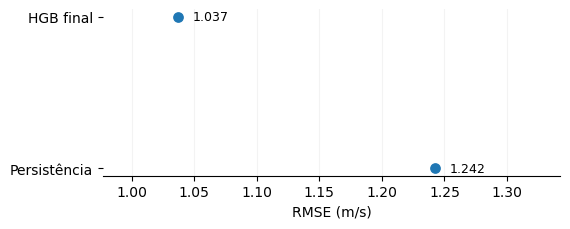

In [3]:
# ============================================================
# FIGURA — PERSISTÊNCIA × HGB FINAL NO TESTE
# Versão discreta para artigo
# ============================================================

dados_teste_grafico = comparacao_teste_final.copy()

dados_teste_grafico["modelo"] = dados_teste_grafico["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

dados_teste_grafico = dados_teste_grafico.sort_values(
    "RMSE",
    ascending=False
)

fig, ax = plt.subplots(figsize=(5.8, 2.4))

ax.scatter(
    dados_teste_grafico["RMSE"],
    dados_teste_grafico["modelo"],
    s=45
)

for _, linha in dados_teste_grafico.iterrows():
    ax.text(
        linha["RMSE"] + 0.012,
        linha["modelo"],
        f'{linha["RMSE"]:.3f}',
        va="center",
        fontsize=9
    )

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.set_xlim(
    dados_teste_grafico["RMSE"].min() - 0.06,
    dados_teste_grafico["RMSE"].max() + 0.10
)

plt.tight_layout()

arquivo_grafico = (
    PASTA_GRAFICOS /
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

plt.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico)

In [4]:
# ============================================================
# CORRIGIR CAMINHO DE SALVAMENTO
# ============================================================

from pathlib import Path

PASTA_GRAFICOS = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS"
)

# Garantir que a pasta existe
PASTA_GRAFICOS.mkdir(
    parents=True,
    exist_ok=True
)

print("Pasta existe:", PASTA_GRAFICOS.exists())
print("Caminho:", PASTA_GRAFICOS)
print("Representação:", repr(str(PASTA_GRAFICOS)))

Pasta existe: True
Caminho: D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS
Representação: 'D:\\Mestrado\\ARTIGOS_2_3_VENTO\\ARTIGO_3_ML\\04_GRAFICOS'


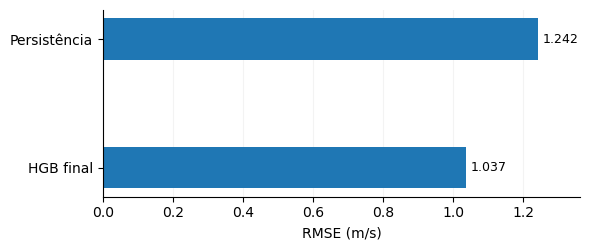

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_02_COMPARACAO_FINAL_TESTE.png


In [5]:
# ============================================================
# FIGURA 03 — PERSISTÊNCIA × HGB FINAL NO TESTE
# Versão final para artigo
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PASTA_PROJETO = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML"
)

PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"

# Recarregar resultados salvos
comparacao_teste_final = pd.read_csv(
    PASTA_TABELAS /
    "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv"
)

dados = comparacao_teste_final.copy()

dados["modelo"] = dados["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

dados = dados.sort_values(
    "RMSE",
    ascending=True
)

fig, ax = plt.subplots(figsize=(6.0, 2.6))

barras = ax.barh(
    dados["modelo"],
    dados["RMSE"],
    height=0.32
)

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

for barra, valor in zip(
    barras,
    dados["RMSE"]
):
    ax.text(
        valor + 0.012,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    dados["RMSE"].max() + 0.12
)

plt.tight_layout()

arquivo_grafico = (
    PASTA_GRAFICOS /
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico)

OSError: [Errno 22] Invalid argument: 'D:\\Mestrado\\ARTIGOS_2_3_VENTO\\ARTIGO_3_ML\\04_GRAFICOS\\FIGURA_02_COMPARACAO_FINAL_TESTE.png'

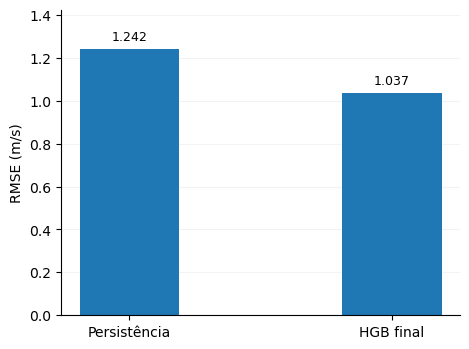

In [6]:
# ============================================================
# FIGURA 03 — PERSISTÊNCIA × HGB FINAL NO TESTE
# Versão compacta com colunas
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PASTA_PROJETO = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML"
)

PASTA_TABELAS = PASTA_PROJETO / "05_TABELAS"
PASTA_GRAFICOS = PASTA_PROJETO / "04_GRAFICOS"

comparacao_teste_final = pd.read_csv(
    PASTA_TABELAS /
    "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv"
)

dados = comparacao_teste_final.copy()

dados["modelo"] = dados["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

fig, ax = plt.subplots(figsize=(4.8, 3.6))

barras = ax.bar(
    dados["modelo"],
    dados["RMSE"],
    width=0.38
)

ax.set_ylabel("RMSE (m/s)")
ax.set_xlabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

for barra, valor in zip(
    barras,
    dados["RMSE"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.025,
        f"{valor:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(
    0,
    dados["RMSE"].max() + 0.18
)

plt.tight_layout()

arquivo_grafico = (
    PASTA_GRAFICOS /
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_grafico)

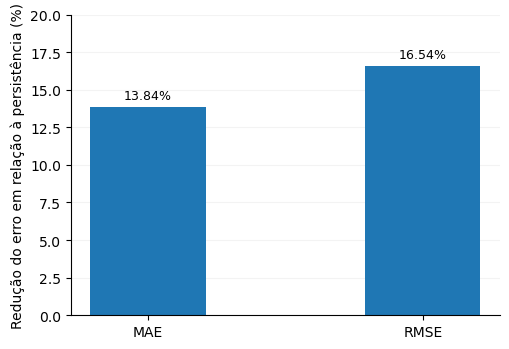

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png


In [7]:
# ============================================================
# FIGURA — GANHO DO HGB EM RELAÇÃO À PERSISTÊNCIA
# TESTE 2018–2020
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Caminho
# ------------------------------------------------------------

PASTA_GRAFICOS = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS"
)

PASTA_GRAFICOS.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Dados já obtidos no teste
# ------------------------------------------------------------

metricas = [
    "MAE",
    "RMSE"
]

ganhos = [
    13.8350,
    16.5444
]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5.2, 3.6))

barras = ax.bar(
    metricas,
    ganhos,
    width=0.42
)

ax.set_ylabel("Redução do erro em relação à persistência (%)")
ax.set_xlabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Valores sobre as barras
for barra, valor in zip(barras, ganhos):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.35,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, 20)

plt.tight_layout()

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_figura = PASTA_GRAFICOS / (
    "FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png"
)

fig.savefig(
    str(arquivo_figura),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_figura)

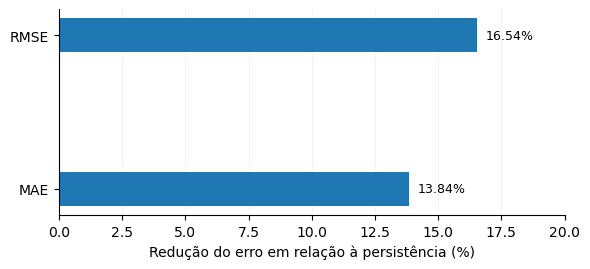

Figura salva em:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png


In [8]:
# ============================================================
# FIGURA — GANHO DO HGB EM RELAÇÃO À PERSISTÊNCIA
# TESTE 2018–2020
# BARRAS HORIZONTAIS E FINAS
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Caminho de salvamento
# ------------------------------------------------------------

PASTA_GRAFICOS = Path(
    r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS"
)

PASTA_GRAFICOS.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Dados
# ------------------------------------------------------------

metricas = [
    "MAE",
    "RMSE"
]

ganhos = [
    13.8350,
    16.5444
]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 2.8))

barras = ax.barh(
    metricas,
    ganhos,
    height=0.22
)

# ------------------------------------------------------------
# Eixos
# ------------------------------------------------------------

ax.set_xlabel("Redução do erro em relação à persistência (%)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Valores ao final das barras
# ------------------------------------------------------------

for barra, valor in zip(barras, ganhos):
    ax.text(
        valor + 0.35,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, 20)

plt.tight_layout()

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_figura = (
    PASTA_GRAFICOS /
    "FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png"
)

fig.savefig(
    str(arquivo_figura),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_figura)

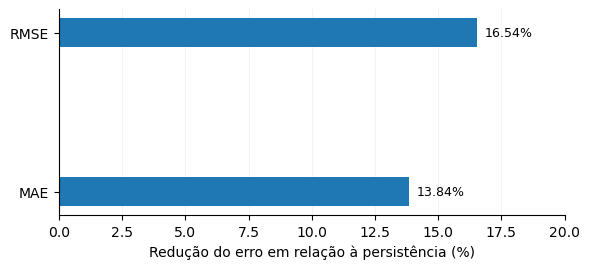

Caminho:
D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS\FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png

Arquivo salvo com sucesso?
True


In [9]:
# ============================================================
# FIGURA — GANHO DO HGB EM RELAÇÃO À PERSISTÊNCIA
# TESTE 2018–2020
# HORIZONTAL, BARRAS FINAS E SALVAMENTO ROBUSTO
# ============================================================

import os
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Pasta de saída
# ------------------------------------------------------------

PASTA_GRAFICOS = r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS"

os.makedirs(
    PASTA_GRAFICOS,
    exist_ok=True
)

# ------------------------------------------------------------
# Dados
# ------------------------------------------------------------

metricas = [
    "MAE",
    "RMSE"
]

ganhos = [
    13.8350,
    16.5444
]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 2.8))

barras = ax.barh(
    metricas,
    ganhos,
    height=0.18
)

ax.set_xlabel(
    "Redução do erro em relação à persistência (%)"
)

ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Valores ao final das barras
for barra, valor in zip(barras, ganhos):

    ax.text(
        valor + 0.30,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, 20)

plt.tight_layout()

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_figura = os.path.join(
    PASTA_GRAFICOS,
    "FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png"
)

fig.savefig(
    arquivo_figura,
    dpi=300,
    bbox_inches="tight",
    format="png"
)

plt.show()

# ------------------------------------------------------------
# Conferência
# ------------------------------------------------------------

print("Caminho:")
print(arquivo_figura)

print("\nArquivo salvo com sucesso?")
print(os.path.exists(arquivo_figura))

OSError: [Errno 22] Invalid argument: 'D:\\Mestrado\\ARTIGOS_2_3_VENTO\\ARTIGO_3_ML\\04_GRAFICOS\\FIGURA_02_COMPARACAO_FINAL_TESTE.png'

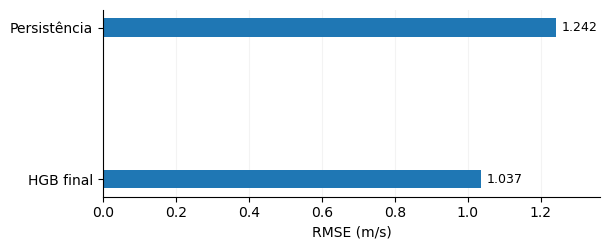

In [10]:
# ============================================================
# FIGURA — PERSISTÊNCIA × HGB FINAL NO TESTE
# BARRAS HORIZONTAIS FINAS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Caminhos
# ------------------------------------------------------------

PASTA_PROJETO = r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML"
PASTA_TABELAS = os.path.join(PASTA_PROJETO, "05_TABELAS")
PASTA_GRAFICOS = os.path.join(PASTA_PROJETO, "04_GRAFICOS")

os.makedirs(PASTA_GRAFICOS, exist_ok=True)

# ------------------------------------------------------------
# Recarregar resultados
# ------------------------------------------------------------

arquivo_resultado = os.path.join(
    PASTA_TABELAS,
    "TABELA_DESEMPENHO_FINAL_TESTE_2018_2020.csv"
)

dados = pd.read_csv(arquivo_resultado)

dados["modelo"] = dados["modelo"].replace({
    "Persistencia": "Persistência",
    "HGB parcimonioso final": "HGB final"
})

dados = dados.sort_values(
    "RMSE",
    ascending=True
)

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.2, 2.6))

barras = ax.barh(
    dados["modelo"],
    dados["RMSE"],
    height=0.12
)

ax.set_xlabel("RMSE (m/s)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Valores ao final das barras
for barra, valor in zip(
    barras,
    dados["RMSE"]
):
    ax.text(
        valor + 0.015,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    dados["RMSE"].max() + 0.12
)

plt.tight_layout()

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_figura = os.path.join(
    PASTA_GRAFICOS,
    "FIGURA_02_COMPARACAO_FINAL_TESTE.png"
)

fig.savefig(
    arquivo_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_figura)

print("\nArquivo existe?")
print(os.path.exists(arquivo_figura))

OSError: [Errno 22] Invalid argument: 'D:\\Mestrado\\ARTIGOS_2_3_VENTO\\ARTIGO_3_ML\\04_GRAFICOS\\FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png'

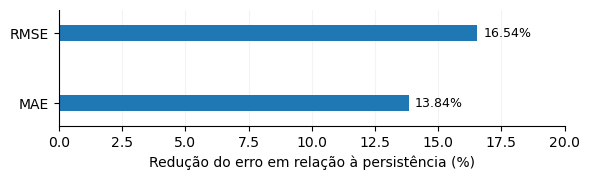

In [11]:
# ============================================================
# FIGURA — GANHO DO HGB EM RELAÇÃO À PERSISTÊNCIA
# TESTE 2018–2020
# BARRAS HORIZONTAIS, FINAS E COMPACTAS
# ============================================================

import os
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Pasta de saída
# ------------------------------------------------------------

PASTA_GRAFICOS = r"D:\Mestrado\ARTIGOS_2_3_VENTO\ARTIGO_3_ML\04_GRAFICOS"

os.makedirs(
    PASTA_GRAFICOS,
    exist_ok=True
)

# ------------------------------------------------------------
# Dados
# ------------------------------------------------------------

metricas = [
    "MAE",
    "RMSE"
]

ganhos = [
    13.8350,
    16.5444
]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.0, 1.9)
)

barras = ax.barh(
    metricas,
    ganhos,
    height=0.22
)

# ------------------------------------------------------------
# Eixos
# ------------------------------------------------------------

ax.set_xlabel(
    "Redução do erro em relação à persistência (%)"
)

ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.15,
    linewidth=0.8
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Valores ao final das barras
# ------------------------------------------------------------

for barra, valor in zip(
    barras,
    ganhos
):
    ax.text(
        valor + 0.25,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Limites do eixo
# ------------------------------------------------------------

ax.set_xlim(
    0,
    20
)

# Aproximar visualmente as duas barras
ax.margins(y=0.18)

plt.tight_layout()

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

arquivo_figura = os.path.join(
    PASTA_GRAFICOS,
    "FIGURA_GANHO_HGB_VS_PERSISTENCIA_TESTE.png"
)

fig.savefig(
    arquivo_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:")
print(arquivo_figura)

print("\nArquivo existe?")
print(os.path.exists(arquivo_figura))